# Tomato leaf: semua dataset ikut latih, nested CV, uji per dataset, banyak augmentasi + SAM

Lanjutan dari `fork-of-run4-bismillah-final-project-tomato-leaf_v2_aug`. **Semua metode lama (10 buah) dipertahankan** dengan nama dan isi yang sama; yang berubah adalah protokol data (sekarang 6 dataset digabung, nested CV) dan ditambah metode baru.

## Protokol
| | Notebook lama | Notebook ini |
|---|---|---|
| Data | latih PlantVillage saja; uji PlantDoc dan PlantSeg | **6 dataset digabung ke satu kolam**: Tomato-Village, PlantDoc, MedSeg, `aliefflostyo/tomato-leaf-disease`, `kaustubhb999/tomatoleaf`, PlantVillage (PlantSeg ikut bila di-Add Input) |
| Dedup | hanya uji vs latih | **semua dataset**, dHash 256-bit + LSH, sebelum gambar dimuat; laporan "dibuang dari dataset X karena duplikat dengan dataset Y" |
| Split | 1 split tetap | **Nested CV**: fold luar (uji) 5 lipatan StratifiedGroupKFold, fold dalam (val) 8 lipatan; setiap kombinasi dataset x kelas tersebar di semua fold, jadi **tidak ada dataset yang hanya dipakai uji** |
| Uji | PlantDoc, PlantSeg | uji fold luar **dilaporkan terpisah per dataset** (+ gabungan `ALL`), raw dan `_iso` |
| Data latih | raw + augmentasi | raw + hasil mask (isolasi) + latar/tekstur + semua augmentasi + data sintetis, digabung |

Pencegahan bocor: grup foto yang sama (awalan nama `___`/uuid) selalu satu fold; gambar sintetis hanya dipakai di fold yang induknya (dan induk gayanya) ada di data latih fold itu; GAN dilatih ulang per fold hanya dari data latih fold itu; bank lesi dibangun dari data latih fold; uji fold luar tidak pernah dipakai untuk early stopping atau memilih metode.

## Metode (23)
| Kelompok | Metode |
|---|---|
| 0-3 (lama, tidak diubah) | `DAPR-AM-Net [Baseline]`, `ExG+Otsu+GrabCut`, `U-Net (ResNet34)`, `Raw+Seg (campur)`, `Raw+Seg+Latar`, `Raw+Seg+Tekstur`, `Aug lengkap (Latar+Tekstur+CopyPaste)`, `Aug lengkap + Rebalancing generatif` (SD Img2Img), `Aug lengkap + Multi-channel`, `Aug lengkap + Curriculum` |
| 4 (baru, masing-masing diuji sendirian) | `BgRecomp+LesionCP+GAN rebal`, `Synthetic UE5`, `Domain randomization`, `RPCP`, `STAug`, `Lesion-level copy-paste`, `Texture overlay (parametrik)`, `Neural style transfer`, `Raw+Mask+BgRecomposed`, `CycleGAN/AR-GAN rebalancing` |
| 5 | `ALL-aug (gabungan semua)`: raw + mask + latar + tekstur + semua augmentasi + SD + NST + GAN (+ UE5 bila ada) |
| 6 | `SAM: Raw+Seg (campur)`, `SAM: ALL-aug`: mask dari **SAM zero-shot** (prompt kotak+titik dari ExG, tanpa fine-tuning) |
| 7 (analisis) | `NESTED-SELECT`: per fold luar dipilih metode terbaik menurut val dalam, lalu diuji; ini klaim yang paling jujur |

## Cara menjalankan di Kaggle
1. GPU T4 (atau P100), **Internet ON** (bobot ImageNet, VGG19, SAM, Stable Diffusion).
2. Add Input: keenam dataset (dan opsional PlantSeg, render UE5). Bila ada yang tidak terdeteksi otomatis, isi `--roots NAMA=/kaggle/input/...` di `NB_ARGS`.
3. **Mulai kecil**: `NB_ARGS = ['--quick']` (uji asap), lalu `['--outer-folds','0']`. Satu fold x 23 metode bisa makan beberapa jam; loop berurutan fold demi fold dan berhenti rapi di `--max-seconds`. **Lanjutkan di sesi lain: cukup Add Input > Notebooks > output notebook lama.** Resume OTOMATIS (`--resume-from auto`): output lama dicari di `/kaggle/input`, `runs/ preds/ masks/ gen/ logs/` disalin, job yang sudah selesai dilewati, dan di awal log tercetak baris `RESUME: ...` (kandidat, jumlah job selesai, alasan berhenti run lama, selesai per fold, job pertama yang akan dilatih). Fold run ini diverifikasi identik dengan run lama; bila beda, run dihentikan (`--force-resume` untuk memaksa). Matikan dengan `--resume-from none`; path manual: `--resume-from <folder outputs_aug>`.
4. Hemat waktu/RAM: `--methods ...`, `--no-sam`, `--no-gen`, `--no-gan`, `--max-per-dataset 6000`, `--epochs 8`.

## Catatan jujur
- **Tidak ada jaminan mengalahkan baseline.** Notebook menguji secara adil (fold, seed, arsitektur, optimizer sama) dan melaporkan McNemar + CI bootstrap + Holm. Bila tidak signifikan, jangan diklaim.
- **UE5**: Unreal Engine tidak bisa dijalankan di Kaggle. Metode ini hanya jalan bila Anda menyediakan render (folder per kelas); render dipakai khusus latih. Tanpa itu dilewati otomatis.
- **STAug dan AR-GAN**: diimplementasikan berdasarkan idenya (target salient diaugmentasi terpisah dari latar; generator GAN beratensi). Arsitektur/detail paper aslinya tidak direproduksi persis.
- **GAN dilatih singkat** (`--gan-minutes` per kelas per fold): kualitas terbatas. Periksa `figures/gan_examples_fold*.png` dan `nst_examples.png`; hasil identitas dan hasil NST yang kehilangan konten disaring otomatis.
- **MedSeg**: deteksi folder memakai nama `medseg`; pastikan label kelasnya terpetakan (lihat tabel laporan dataset dan daftar label tak terpetakan). Kelas di luar 8 kelas (mis. leaf miner, defisiensi nutrisi di Tomato-Village) dibuang.
- Dedup memakai kemiripan visual (dHash); pasangan dengan **label berbeda** antar dataset diberi peringatan (`tables/duplicates_pairs.csv`). Bootstrap meresampel gambar, bukan grup foto, jadi CI sedikit optimis.
- Segmenter (U-Net) dilatih pada mask PlantVillage (hanya bentuk daun, bukan kelas) dan dipakai untuk semua fold.
- Kode GPU belum bisa saya jalankan di lingkungan ini (tidak ada GPU/torch); bagian dedup, pembagian fold, dan sintaks diuji. Jalankan `--quick` dulu dan kirim log bila ada error.

## Keluaran (`outputs_aug`)
`tables/dedup_matrix.csv`, `duplicates_pairs.csv`, `dataset_report.csv`, `folds.csv`, `all_results_comparison.csv`, `significance_vs_baseline.csv`, `nested_selection.csv`, `RESULTS_TABLES.md`, `figures/*.png` (contoh duplikat, mask per dataset termasuk SAM, contoh semua augmentasi, GAN/NST, grafik F1, heatmap selisih), `hasil_ringan_outputs_aug.zip`.


## 1. Pengaturan

In [1]:
# ---- PENJELASAN KODE ----
# 1. NB_ARGS = argumen (setara command line). Bawaan: nested CV 5 fold luar, 1 seed, 12 epoch, mask baru dari U-Net ResNet34, semua augmentasi/sintetis aktif.
# 2. CFG = hyperparameter klasifikasi (sama dengan notebook lama agar perbandingan apple-to-apple). SEG = hyperparameter segmenter.
# 3. --quick mengecilkan semuanya untuk uji asap (beberapa menit).
import argparse, sys, os
IN_NB = 'ipykernel' in sys.modules
NB_ARGS = ['--seeds', '42', '--no-sam']   # --no-sam: langsung lewati metode SAM (bank SAM OOM di run lama)
#   contoh: ['--outer-folds','0'] (hanya fold 0) | ['--seeds','42','43'] | ['--quick'] | ['--no-gen'] | ['--new-seg','sam'] | ['--methods','DAPR-AM-Net [Baseline]','ALL-aug (gabungan semua)']
#   dataset tidak terdeteksi otomatis? tambahkan: ['--roots','TomatoVillage=/kaggle/input/nama-folder','MedSeg=/kaggle/input/nama-folder']

def parse_args():
    ap = argparse.ArgumentParser()
    ap.add_argument('--seeds', type=int, nargs='+', default=[42])
    ap.add_argument('--methods', nargs='*', default=None, help='nama metode yang dijalankan (default: semua)')
    ap.add_argument('--skip-methods', nargs='*', default=[])
    ap.add_argument('--quick', action='store_true', help='uji asap (data kecil, 2 epoch)')
    ap.add_argument('--out', default=None)
    ap.add_argument('--data-root', default=None)
    ap.add_argument('--epochs', type=int, default=12)
    ap.add_argument('--patience', type=int, default=4)
    ap.add_argument('--new-seg', choices=['unet', 'exg', 'sam'], default='unet', help='segmenter untuk metode augmentasi baru')
    ap.add_argument('--no-gen', action='store_true', help='lewati rebalancing generatif (tanpa Stable Diffusion)')
    ap.add_argument('--gen-per-class', type=int, default=150)
    ap.add_argument('--gen-max-min', type=float, default=40)
    ap.add_argument('--seg-train-n', type=int, default=4000)
    ap.add_argument('--max-seconds', type=int, default=41400, help='batas total waktu (11,5 jam)')
    ap.add_argument('--boot', type=int, default=1000)
    # ---- nested CV + multi-dataset ----
    ap.add_argument('--outer-k', type=int, default=5, help='jumlah fold luar (uji) pada nested CV')
    ap.add_argument('--outer-folds', type=int, nargs='*', default=None, help='fold luar yang dijalankan (default: semua). Contoh: --outer-folds 0 1')
    ap.add_argument('--inner-k', type=int, default=8, help='jumlah fold dalam; 1 fold dalam = val (early stopping dan pemilihan checkpoint/metode)')
    ap.add_argument('--roots', nargs='*', default=[], help='override lokasi dataset: NAMA=/path (NAMA: TomatoVillage, PlantDoc, MedSeg, AliefTomato, KaustubhTomato, PlantVillage, PlantSeg, UE5)')
    ap.add_argument('--dup-bits', type=int, default=10, help='ambang duplikat: jarak Hamming dHash 256-bit <= nilai ini')
    ap.add_argument('--max-per-dataset', type=int, default=0, help='batasi gambar per dataset setelah dedup (0 = tanpa batas; untuk menghemat RAM)')
    ap.add_argument('--resume-from', default='auto', help="'auto' (bawaan): cari output notebook lama di /kaggle/input (Add Input > Notebooks) dan lanjutkan; 'none' = mulai dari nol; atau path folder outputs_aug lama")
    ap.add_argument('--force-resume', action='store_true', help='abaikan hasil verifikasi fold saat resume (tidak disarankan)')
    # ---- segmentasi SAM ----
    ap.add_argument('--sam-model', default='facebook/sam-vit-base')
    ap.add_argument('--sam-bs', type=int, default=16)
    ap.add_argument('--no-sam', action='store_true')
    # ---- sintetis ----
    ap.add_argument('--no-sd', action='store_true', help='lewati Stable Diffusion Img2Img (rebalancing generatif lama)')
    ap.add_argument('--no-nst', action='store_true'); ap.add_argument('--nst-n', type=int, default=1200); ap.add_argument('--nst-steps', type=int, default=40)
    ap.add_argument('--nst-style-w', type=float, default=2.0)
    ap.add_argument('--no-gan', action='store_true'); ap.add_argument('--gan-per-class', type=int, default=150)
    ap.add_argument('--gan-minutes', type=float, default=5.0, help='menit latih GAN per kelas minoritas per fold luar')
    ap.add_argument('--gan-kind', choices=['attn', 'cyclegan'], default='attn')
    ap.add_argument('--ue5-root', default=None, help='folder render UE5 (subfolder per kelas); bila kosong dicari otomatis')
    a, _ = ap.parse_known_args(NB_ARGS if IN_NB else None)
    return a
ARGS = parse_args()
QUICK = ARGS.quick
ON_KAGGLE = os.path.isdir('/kaggle/working')
OUT = ARGS.out or ('/kaggle/working/outputs_aug' if ON_KAGGLE else os.path.abspath('./outputs_aug'))
DATA_ROOTS = [ARGS.data_root] if ARGS.data_root else ['/kaggle/input', './data']
os.environ.setdefault('HF_HUB_DOWNLOAD_TIMEOUT', '30'); os.environ.setdefault('HF_HUB_ETAG_TIMEOUT', '15')

CFG = dict(SEED=42, IMG_STORE=256, IMG_SIZE=224, EPOCHS=ARGS.epochs, PATIENCE=ARGS.patience, BATCH=64,
           LR_DAPR=5e-4, WD_DAPR=1e-3, LABEL_SMOOTH=0.1, MIX_ALPHA=0.1, MIX_P=0.5, BETA_AUX_MAX=0.3, LAMBDA_ATT=0.05)
SEG = dict(MIN_FRAC=0.08, MAX_FRAC=0.92, SEG_TRAIN_N=ARGS.seg_train_n, SEG_VAL_N=500, SEG_EPOCHS=6, SEG_BATCH=32, SEG_LR=5e-4, SEG_BG_P=0.7)
GEN = dict(PER_CLASS=ARGS.gen_per_class, N_MINOR=3, BS=8, MAX_MIN=ARGS.gen_max_min,
           SD_MODELS=['stable-diffusion-v1-5/stable-diffusion-v1-5', 'sd-legacy/stable-diffusion-v1-5', 'runwayml/stable-diffusion-v1-5'],
           STRENGTH=0.35, GUIDANCE=7.5, STEPS=50)
NST = dict(N=ARGS.nst_n, STEPS=ARGS.nst_steps, STYLE_W=ARGS.nst_style_w, RES=224, BS=16, MIN_CORR=0.55)
GAN = dict(PER_CLASS=ARGS.gan_per_class, MINUTES=ARGS.gan_minutes, RES=128, BS=8, KIND=ARGS.gan_kind, N_MINOR=3)
if ARGS.no_gen: ARGS.no_sd = ARGS.no_nst = ARGS.no_gan = True
OUTER_K = ARGS.outer_k; OUTER_RUN = sorted(set(ARGS.outer_folds)) if ARGS.outer_folds else list(range(OUTER_K))
assert all(0 <= f < OUTER_K for f in OUTER_RUN), f'--outer-folds harus di antara 0 dan {OUTER_K-1}'
if QUICK:
    CFG.update(EPOCHS=2, PATIENCE=2); NST.update(N=32, STEPS=4); GAN.update(PER_CLASS=8, MINUTES=0.3); OUTER_RUN = OUTER_RUN[:1]
    SEG.update(SEG_TRAIN_N=200, SEG_VAL_N=60, SEG_EPOCHS=1)
    GEN.update(PER_CLASS=8)
NEW_SEG = ARGS.new_seg          # 'unet', 'exg' atau 'sam': segmenter untuk semua metode augmentasi baru
SEGMENTERS = ['exg', 'unet'] + ([] if ARGS.no_sam else ['sam'])   # bank mask yang tersedia

## 2. Pustaka, logger, dan fungsi bantu

In [2]:
# ---- PENJELASAN KODE ----
# 1. `log()` mencetak ke layar dan ke logs/run_log.txt. `slug`/`norm` = normalisasi nama.
# 2. `par_map_sink()` = map paralel berbasis thread (tanpa multiprocessing.Pool, supaya tidak ada deadlock fork setelah GPU aktif).
import re, json, math, time, glob, random, shutil, hashlib, warnings, platform, zipfile, fnmatch, subprocess, textwrap, traceback, datetime
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score, balanced_accuracy_score, matthews_corrcoef)
from sklearn.model_selection import StratifiedGroupKFold, StratifiedShuffleSplit
from scipy import stats
warnings.filterwarnings('ignore')
try:
    import cv2
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'opencv-python-headless'], check=False, timeout=300)
    import cv2

T0 = time.time()
for sub_ in ['figures', 'tables', 'runs', 'preds', 'masks', 'logs', 'confusion_matrices', 'gen']:
    os.makedirs(os.path.join(OUT, sub_), exist_ok=True)
# ---- RESUME OTOMATIS: cari output run sebelumnya di Input (Add Input > Notebooks > output notebook lama) dan salin supaya job selesai tidak diulang ----
RESUME_INFO = dict(dir=None, msgs=[], prev_log='', n_runs=0)
def _find_prev_outputs(roots, exclude):
    """Folder yang berisi runs/*.json (output run lama) di bawah Input, kedalaman <= 5. Urut: paling banyak job selesai, lalu terbaru."""
    ex = os.path.realpath(exclude); cands = []
    for root in roots:
        if not root or not os.path.isdir(root): continue
        for k in range(0, 6):
            for rd in glob.glob(os.path.join(root, *(['*'] * k), 'runs')):
                d = os.path.dirname(rd)
                if not os.path.isdir(rd) or os.path.realpath(d).startswith(ex): continue
                n = len(glob.glob(os.path.join(rd, '*.json')))
                if n: cands.append((n, os.path.getmtime(rd), d))
    return sorted(set(cands), reverse=True)

_rf = (ARGS.resume_from or 'auto').strip(); _src = None
if _rf.lower() == 'none':
    RESUME_INFO['msgs'].append('RESUME: dimatikan (--resume-from none) -> mulai dari nol.')
elif _rf.lower() == 'auto':
    _c = _find_prev_outputs(DATA_ROOTS, OUT)
    if _c:
        _src = _c[0][2]
        for _n, _mt, _d in _c[:5]: RESUME_INFO['msgs'].append(f'RESUME: kandidat output lama: {_d} ({_n} job selesai)' + ('  <-- DIPAKAI' if _d == _src else ''))
    else:
        RESUME_INFO['msgs'].append('RESUME: TIDAK ada output run sebelumnya di Input -> mulai dari NOL. (Untuk melanjutkan: Add Input > Notebooks > pilih output notebook lama; atau isi --resume-from <folder outputs_aug>.)')
else:
    if os.path.isdir(os.path.join(_rf, 'runs')): _src = _rf
    else: RESUME_INFO['msgs'].append(f'RESUME: PERINGATAN, --resume-from "{_rf}" tidak punya folder runs/ -> mulai dari NOL. Periksa path (salin dari panel Input).')
if _src:
    _lp = os.path.join(_src, 'logs', 'run_log.txt')
    if os.path.exists(_lp):
        RESUME_INFO['prev_log'] = open(_lp, errors='ignore').read()
        _k = len(glob.glob(os.path.join(OUT, 'logs', 'run_log_sebelumnya_*.txt'))) + len(glob.glob(os.path.join(_src, 'logs', 'run_log_sebelumnya_*.txt'))) + 1
    for sub_ in ['runs', 'preds', 'masks', 'gen', 'logs']:
        if os.path.isdir(os.path.join(_src, sub_)):
            shutil.copytree(os.path.join(_src, sub_), os.path.join(OUT, sub_), dirs_exist_ok=True, ignore=shutil.ignore_patterns('run_log.txt') if sub_ == 'logs' else None)
    if RESUME_INFO['prev_log']: shutil.copy2(_lp, os.path.join(OUT, 'logs', f'run_log_sebelumnya_{_k}.txt'))   # riwayat log lama disimpan terpisah; run_log.txt run ini mulai bersih
    RESUME_INFO['dir'] = _src; RESUME_INFO['n_runs'] = len(glob.glob(os.path.join(OUT, 'runs', '*.json')))
    _stop = [l for l in RESUME_INFO['prev_log'].splitlines() if 'Training selesai' in l]
    RESUME_INFO['msgs'] += [f'RESUME: output lama DISALIN dari {_src}',
                            f'RESUME: runs/*.json = {RESUME_INFO["n_runs"]} | preds/*.npz = {len(glob.glob(os.path.join(OUT, "preds", "*.npz")))} | masks/ = {len(os.listdir(os.path.join(OUT, "masks")))} berkas | gen/ = {len(os.listdir(os.path.join(OUT, "gen")))} berkas',
                            'RESUME: run lama berhenti karena -> ' + (_stop[-1].strip() if _stop else '(tidak tercatat di run_log.txt lama)')]
FIG = os.path.join(OUT, 'figures'); TAB = os.path.join(OUT, 'tables'); MSK = os.path.join(OUT, 'masks')
LOGF = open(os.path.join(OUT, 'logs', 'run_log.txt'), 'a')
def log(*a):
    msg = ' '.join(str(x) for x in a); stamp = f"[{(time.time()-T0)/60:7.1f}m] "
    print(stamp + msg, flush=True); LOGF.write(stamp + msg + '\n'); LOGF.flush()

slug = lambda s: re.sub(r'[^A-Za-z0-9]+', '_', s).strip('_')
norm = lambda s: re.sub(r'[^a-z0-9]+', ' ', str(s).lower()).strip()

def par_map_sink(fn, items, sink, workers=None, log_every=0, desc=''):
    """Jalankan fn(item) paralel (thread) dan panggil sink(i, hasil) berurutan di thread utama."""
    workers = workers or min(32, (os.cpu_count() or 4) * 2); t = time.time()
    with ThreadPoolExecutor(workers) as ex:
        for i, r in enumerate(ex.map(fn, items)):
            sink(i, r)
            if log_every and (i + 1) % log_every == 0: log(f'  {desc}: {i+1}/{len(items)} ({time.time()-t:.0f}s)')

def seed_everything(s):
    random.seed(s); np.random.seed(s)
    try:
        import torch
        torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    except ImportError:
        pass
log(f'Python {platform.python_version()} | OUT = {OUT} | seeds {ARGS.seeds} | quick={QUICK} | segmenter metode baru = {NEW_SEG} | CPU={os.cpu_count()}')
for _m in RESUME_INFO['msgs']: log(_m)


[    0.3m] Python 3.13.15 | OUT = /kaggle/working/outputs_aug | seeds [42] | quick=False | segmenter metode baru = unet | CPU=4
[    0.3m] RESUME: kandidat output lama: /kaggle/input/notebooks/munasyifaalfiah/run-percobaan2-bismillah-final-project-tomato-leaf/outputs_aug (50 job selesai)  <-- DIPAKAI
[    0.3m] RESUME: output lama DISALIN dari /kaggle/input/notebooks/munasyifaalfiah/run-percobaan2-bismillah-final-project-tomato-leaf/outputs_aug
[    0.3m] RESUME: runs/*.json = 50 | preds/*.npz = 50 | masks/ = 3 berkas | gen/ = 4 berkas
[    0.3m] RESUME: run lama berhenti karena -> [  654.8m] Training selesai (batas waktu: sisa 35 menit < perkiraan job (32 menit) + cadangan analisis). Total waktu: 10.91 jam


## 3. Data: 6 dataset digabung (semua ikut latih)

Daftar gambar dibuat langsung dari folder dataset Kaggle. Nama folder/berkas dipetakan ke 8 kelas; label di luar 8 kelas dibuang dan dilaporkan. **Periksa tabel laporan**: dataset yang `TIDAK DITEMUKAN` atau jumlah per kelas yang janggal harus diperbaiki dulu (`--roots`).

In [3]:
# ---- PENJELASAN KODE ----
# 1. `map_label()` memetakan teks (nama folder/berkas/metadata) ke 8 kelas; teks berisi spider mite / target spot / gray mold dst. dibuang.
# 2. `scan_pv()` membaca PlantVillage: folder `color` = raw, folder `segmented` dipakai sebagai label mask untuk melatih U-Net.
# 3. `scan_dataset()` (BARU) membaca dataset mana pun lewat nama folder kelas; `scan_test_set()` (lama) tetap ada.
# 4. Registri 6 dataset (+ PlantSeg bila ada, + render UE5 bila ada). SEMUA dataset masuk ke satu kolam; pembagian latih/uji dibuat di sel nested CV.
# 5. Dataset yang tidak ditemukan dilaporkan jelas (jangan lanjut diam-diam). Override lokasi: --roots NAMA=/path.
ID_CLASSES = ['Bacterial_spot', 'Early_blight', 'Late_blight', 'Leaf_mold', 'Septoria_leaf_spot', 'Yellow_leaf_curl_virus', 'Mosaic_virus', 'Healthy']
C = len(ID_CLASSES); CLS2ID = {c: i for i, c in enumerate(ID_CLASSES)}; HEALTHY = CLS2ID['Healthy']
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff'}
S = CFG['IMG_STORE']
EXCLUDE = re.compile(r'gray|grey|botrytis|spider|mite|target|wilt|canker|miner|powdery|speck')
CLASS_PATTERNS = [(r'yellow\s*leaf\s*curl|yellow\s*virus|curl|tylcv|ylcv', 'Yellow_leaf_curl_virus'),
                  (r'mosaic|\btomv\b|\btmv\b', 'Mosaic_virus'), (r'septoria', 'Septoria_leaf_spot'),
                  (r'early\s*blight', 'Early_blight'), (r'late\s*blight', 'Late_blight'), (r'bacterial\s*spot', 'Bacterial_spot'),
                  (r'mou?ld', 'Leaf_mold'), (r'healthy', 'Healthy')]
SKIP_DIR = re.compile(r'mask|annotation|label|segmentation|ground ?truth|\bgt\b')

def map_label(*texts):
    for txt in texts:
        t = norm(txt) if txt else ''
        if not t: continue
        if EXCLUDE.search(t): return None
        for pat, lab in CLASS_PATTERNS:
            if re.search(pat, t): return lab
        if t in ('tomato leaf', 'tomato leaves'): return 'Healthy'        # PlantDoc: folder "Tomato leaf" = sehat
    return None

def find_roots(hints, maxdepth=4):
    out = []
    for base in DATA_ROOTS:
        if not os.path.isdir(base): continue
        b0 = base.rstrip(os.sep).count(os.sep)
        for dp, dns, fns in os.walk(base):
            if any(h in norm(os.path.basename(dp)) for h in hints):
                out.append(dp); dns[:] = []; continue
            if dp.count(os.sep) - b0 >= maxdepth: dns[:] = []
    return out

def stem_key(f):
    return re.sub(r'_final_masked$', '', os.path.splitext(f)[0], flags=re.I).lower()

def scan_pv():
    rows, seg = [], {}
    for r in find_roots(('plantvillage', 'plant village')):
        for dp, dns, fns in os.walk(r):
            parts = [norm(x) for x in os.path.relpath(dp, r).split(os.sep)]
            if 'grayscale' in parts: dns[:] = []; continue
            cls = os.path.basename(dp); imgs = [f for f in sorted(fns) if os.path.splitext(f)[1].lower() in IMG_EXT]
            if not imgs or not norm(cls).startswith('tomato'): continue
            if 'segmented' in parts:
                for f in imgs: seg[(cls, stem_key(f))] = os.path.join(dp, f)
                continue
            lab = map_label(cls)
            if lab is None: continue
            for f in imgs: rows.append(dict(path=os.path.join(dp, f), label_name=lab, src='PlantVillage', cls_dir=cls, stem=os.path.splitext(f)[0]))
    return rows, seg

def load_meta_lookup(roots):
    """PlantSeg: Metadata.csv -> {nama berkas: 'plant disease'}."""
    look = {}
    for r in roots:
        for dp, dns, fns in os.walk(r):
            for f in fns:
                if not (f.lower().endswith('.csv') and 'meta' in f.lower()): continue
                try: d = pd.read_csv(os.path.join(dp, f), encoding_errors='ignore')
                except Exception: continue
                low = {c: str(c).lower().strip() for c in d.columns}
                namec = next((c for c, l in low.items() if l in ('name', 'image', 'filename', 'file name', 'image name')), None) or next((c for c, l in low.items() if 'name' in l), None)
                txtc = [c for c, l in low.items() if any(k in l for k in ('plant', 'disease', 'class', 'category'))]
                if namec is None or not txtc: continue
                for _, row in d.iterrows():
                    k = str(row[namec]).lower().strip(); txt = ' '.join(str(row[c]) for c in txtc)
                    look[k] = txt; look[os.path.splitext(k)[0]] = txt
                log(f'  metadata PlantSeg: {os.path.join(dp, f)} ({len(d)} baris, kolom nama={namec}, kolom teks={txtc})')
    return look

def scan_test_set(name, hints, use_meta=False):
    roots = find_roots(hints)
    if not roots: return [], dict(set=name, status='TIDAK DITEMUKAN (Add Input?)', n_scanned=0, n_tomato=0, n_mapped=0), Counter()
    look = load_meta_lookup(roots) if use_meta else {}
    rows, n_scan, n_tom, unm, seen = [], 0, 0, Counter(), set()
    for r in roots:
        for dp, dns, fns in os.walk(r):
            dns[:] = [d for d in dns if not SKIP_DIR.search(norm(d))]
            for f in sorted(fns):
                if os.path.splitext(f)[1].lower() not in IMG_EXT: continue
                p = os.path.join(dp, f)
                if p in seen: continue
                seen.add(p); n_scan += 1
                mt = look.get(f.lower(), look.get(os.path.splitext(f)[0].lower(), ''))
                if 'tomato' not in norm(os.path.relpath(p, r) + ' ' + mt): continue
                n_tom += 1
                lab = map_label(mt, os.path.basename(dp), os.path.splitext(f)[0])
                if lab is None: unm[norm(mt) or norm(os.path.basename(dp))] += 1; continue
                rows.append(dict(path=p, label_name=lab, src=name, cls_dir=os.path.basename(dp), stem=os.path.splitext(f)[0]))
    rep = dict(set=name, status='ditemukan' if rows else 'ditemukan, tetapi tidak ada gambar tomat yang terpetakan', n_scanned=n_scan, n_tomato=n_tom, n_mapped=len(rows), root=roots[0])
    return rows, rep, unm

# ===================== BARU: registri dataset =====================
def scan_dataset(name, roots, need_tomato=True, use_meta=False):
    """Pindai satu dataset dari daftar folder `roots`. Label dari nama folder (induk, kakek) atau nama berkas; label tak terpetakan dihitung."""
    if not roots: return [], dict(set=name, status='TIDAK DITEMUKAN', n_scanned=0, n_tomato=0, n_mapped=0, root=''), Counter()
    look = load_meta_lookup(roots) if use_meta else {}
    rows, n_scan, n_tom, unm, seen = [], 0, 0, Counter(), set()
    for r in roots:
        for dp, dns, fns in os.walk(r):
            dns[:] = [d for d in dns if not SKIP_DIR.search(norm(d))]
            for f in sorted(fns):
                if os.path.splitext(f)[1].lower() not in IMG_EXT: continue
                p = os.path.join(dp, f)
                if p in seen: continue
                seen.add(p); n_scan += 1
                mt = look.get(f.lower(), look.get(os.path.splitext(f)[0].lower(), ''))
                rel = os.path.relpath(p, r)
                if need_tomato and 'tomato' not in norm(rel + ' ' + mt): continue
                n_tom += 1
                lab = map_label(mt, os.path.basename(dp), os.path.basename(os.path.dirname(dp)), os.path.splitext(f)[0])
                if lab is None: unm[norm(mt) or norm(os.path.basename(dp))] += 1; continue
                rows.append(dict(path=p, label_name=lab, src=name, cls_dir=os.path.basename(dp), stem=os.path.splitext(f)[0]))
    rep = dict(set=name, status='ditemukan' if rows else 'ditemukan, tetapi tidak ada gambar yang terpetakan ke 8 kelas', n_scanned=n_scan, n_tomato=n_tom, n_mapped=len(rows), root=roots[0])
    return rows, rep, unm

# nama, petunjuk nama folder (setelah norm), perlu filter 'tomato' di path?, pakai Metadata.csv?
DS_REG = [('TomatoVillage', ('tomato village', 'tomatovillage'), False, False),
          ('PlantDoc', ('plantdoc', 'plant doc'), True, False),
          ('MedSeg', ('medseg', 'med seg'), False, False),
          ('AliefTomato', ('tomato leaf disease',), False, False),
          ('KaustubhTomato', ('tomatoleaf',), False, False),
          ('PlantSeg', ('plantseg',), True, True)]                 # PlantSeg dari notebook lama; dipakai bila di-Add Input
OVERRIDE = {}
for kv in ARGS.roots:
    if '=' in kv: k_, v_ = kv.split('=', 1); OVERRIDE[k_.strip()] = v_.strip()

rows_pv, SEG_INDEX = scan_pv()
if 'PlantVillage' in OVERRIDE: log('PlantVillage: pakai --roots', OVERRIDE['PlantVillage'])
assert len(rows_pv) > 100, ('PlantVillage tomat tidak ditemukan. Pastikan dataset abdallahalidev/plantvillage-dataset di-Add Input '
                            f'(folder berisi color/Tomato___...). Ditemukan: {len(rows_pv)} gambar.')
claimed = [r for r in find_roots(('plantvillage', 'plant village'))]
ALL_ROWS = list(rows_pv); REPORT = [dict(set='PlantVillage', status='ditemukan', n_scanned=len(rows_pv), n_tomato=len(rows_pv), n_mapped=len(rows_pv), root=claimed[0] if claimed else '')]
UNMAPPED = {}
for name, hints, need_tom, use_meta in DS_REG:
    roots = [OVERRIDE[name]] if name in OVERRIDE else [r for r in find_roots(hints) if not any(r == c or r.startswith(c + os.sep) or c.startswith(r + os.sep) for c in claimed)]
    rows, rep, unm = scan_dataset(name, roots, need_tom, use_meta)
    claimed += roots; ALL_ROWS += rows; REPORT.append(rep); UNMAPPED[name] = unm
# render UE5 (opsional; hanya untuk latih, tidak pernah untuk uji)
ue5_roots = [ARGS.ue5_root] if ARGS.ue5_root else [r for r in find_roots(('ue5', 'unreal', 'synthetic tomato', 'tomato synthetic')) if not any(r == c or r.startswith(c + os.sep) for c in claimed)]
rows_ue, rep_ue, unm_ue = scan_dataset('UE5', ue5_roots, need_tomato=False)
ALL_ROWS += rows_ue; REPORT.append(rep_ue); UNMAPPED['UE5'] = unm_ue
HAS_UE5 = len(rows_ue) > 0
if not HAS_UE5: log('UE5: tidak ada render yang ditemukan -> metode "Synthetic UE5" dilewati. (Render di Unreal Engine 5, simpan per folder kelas, Add Input, atau pakai --ue5-root)')

meta_all = pd.DataFrame(ALL_ROWS)
meta_all['y'] = meta_all.label_name.map(CLS2ID).astype(int)
meta_all['train_only'] = meta_all.src.eq('UE5')
if QUICK:
    meta_all = pd.concat([d.sample(min(len(d), 40), random_state=0) for _, d in meta_all.groupby(['src', 'label_name'])]).reset_index(drop=True)
    log('QUICK: subset', len(meta_all), 'gambar')
meta_all = meta_all.reset_index(drop=True)

REP = pd.DataFrame(REPORT); print(REP.to_string(index=False))
missing = REP[REP.status.str.startswith('TIDAK')].set.tolist()
if [m for m in missing if m not in ('PlantSeg', 'UE5')]:
    log('PERINGATAN: dataset berikut TIDAK ditemukan (cek nama folder di /kaggle/input atau pakai --roots NAMA=/path):', [m for m in missing if m not in ('PlantSeg', 'UE5')])
    log('Isi /kaggle/input:', sorted(os.listdir('/kaggle/input'))[:40] if os.path.isdir('/kaggle/input') else 'tidak ada')
print('\nJumlah gambar per sumber x kelas (SEBELUM dedup):')
print(pd.crosstab(meta_all.src, meta_all.label_name).reindex(columns=ID_CLASSES, fill_value=0).to_string())
for nm, unm in UNMAPPED.items():
    if unm: print(f'\n{nm}: label yang TIDAK terpetakan ke 8 kelas (dibuang), 10 teratas:', unm.most_common(10))
REP.to_csv(os.path.join(TAB, 'dataset_report.csv'), index=False); meta_all.to_csv(os.path.join(TAB, 'meta_images_before_dedup.csv'), index=False)


[    0.7m]   metadata PlantSeg: /kaggle/input/datasets/weitianqi/plantseg/plantsegv2/Metadatav2.csv (11458 baris, kolom nama=Name, kolom teks=['Plant', 'Disease'])
[    0.7m] UE5: tidak ada render yang ditemukan -> metode "Synthetic UE5" dilewati. (Render di Unreal Engine 5, simpan per folder kelas, Add Input, atau pakai --ue5-root)
           set          status  n_scanned  n_tomato  n_mapped                                                       root
  PlantVillage       ditemukan      30160     30160     30160 /kaggle/input/datasets/abdallahalidev/plantvillage-dataset
 TomatoVillage       ditemukan      18893     18893      1616   /kaggle/input/datasets/aliefflostyo/alief-tomato-village
      PlantDoc       ditemukan       2552       731       731   /kaggle/input/datasets/abdulhasibuddin/plant-doc-dataset
        MedSeg TIDAK DITEMUKAN          0         0         0                                                           
   AliefTomato       ditemukan       2627      2627      180

**Dedup lintas dataset.** Hash dihitung dari berkas, pasangan duplikat dicari dengan LSH, lalu dilaporkan dibuang dari dataset mana karena duplikat dengan dataset mana.

[    3.7m]   dHash: 8000/43900 (181s)
[    6.6m]   dHash: 16000/43900 (350s)
[    7.0m]   dHash: 24000/43900 (378s)
[    7.5m]   dHash: 32000/43900 (407s)
[    8.1m]   dHash: 40000/43900 (442s)
[    8.3m] dHash 43900 gambar: 457s | gagal dibaca: 0
[    8.5m] Pasangan mirip (<= 10 bit dari 256): 31101 | gambar dibuang sebagai duplikat: 23161

MATRIKS DUPLIKAT: baris = gambar DIBUANG dari dataset ini; kolom = karena duplikat dengan gambar di dataset ini (yang dipertahankan)
duplikat_dengan  AliefTomato  KaustubhTomato  PlantDoc  PlantSeg  PlantVillage  TomatoVillage
dibuang_dari                                                                                 
AliefTomato               14               0         0         0             0              0
KaustubhTomato             0             192         0         0             0              0
PlantDoc                   0               0        17        71             0              0
PlantSeg                   0               0         

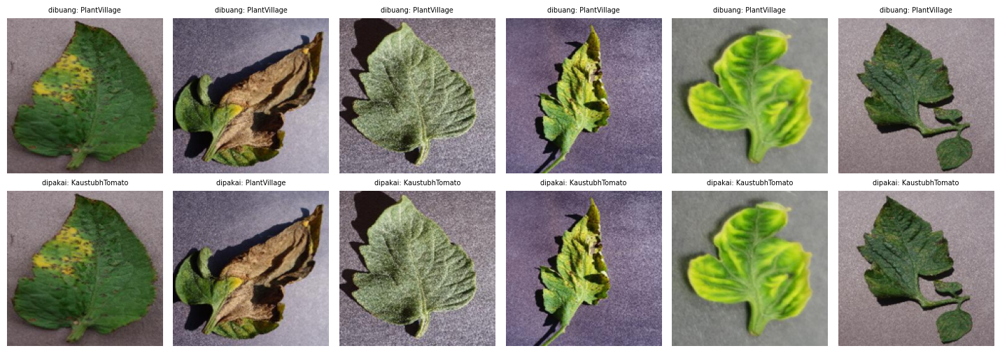


Jumlah gambar per sumber x kelas (SETELAH dedup):
label_name      Bacterial_spot  Early_blight  Late_blight  Leaf_mold  Septoria_leaf_spot  Yellow_leaf_curl_virus  Mosaic_virus  Healthy
src                                                                                                                                    
AliefTomato                375           203          159        220                   0                     392             0      438
KaustubhTomato            1100          1081         1097       1085                1098                    1100           953     1094
PlantDoc                    99            64           96         82                 123                      64            53       62
PlantSeg                     0           185          163        155                 127                      90            61        0
PlantVillage              1027            50          807         48                 682                    4257            19      5

In [4]:
# ---- PENJELASAN KODE ----
# 1. Dedup SEBELUM gambar dimuat ke RAM: dHash 256-bit (16x16) dihitung langsung dari berkas (cepat, paralel, di-cache).
# 2. Pencarian pasangan duplikat memakai LSH (16 blok x 16 bit; jarak <= --dup-bits pasti berbagi >= 1 blok identik) sehingga tidak perlu matriks N x N.
# 3. Prioritas simpan: dataset lapangan/langka dulu, PlantVillage terakhir. Gambar yang duplikat dibuang dari dataset berprioritas lebih rendah.
# 4. Laporan: matriks "dibuang dari dataset X karena duplikat dengan dataset Y", daftar pasangan (CSV), dan contoh visual.
DS_PRIORITY = ['TomatoVillage', 'MedSeg', 'PlantSeg', 'PlantDoc', 'AliefTomato', 'KaustubhTomato', 'PlantVillage']   # urutan = prioritas SIMPAN
POP8 = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)

def dhash256_file(p):
    try:
        im = Image.open(p)
        try: im.draft('L', (160, 160))
        except Exception: pass
        g = np.asarray(im.convert('L').resize((17, 16), Image.BILINEAR), dtype=np.int16)
        return np.packbits((g[:, 1:] > g[:, :-1]).flatten()).view('>u8').astype(np.uint64)        # 4 x uint64 = 256 bit
    except Exception:
        return None

def popcnt(x):                      # x [...,4] uint64 -> jumlah bit 1 [...]
    return POP8[np.ascontiguousarray(x).view(np.uint8)].reshape(*x.shape[:-1], -1).sum(-1)

def hash_all(paths):
    sig = hashlib.sha1('|'.join(paths).encode()).hexdigest()[:12]; fp = os.path.join(TAB, f'dhash256_{sig}.npy')
    if os.path.exists(fp): return np.load(fp)
    H_ = np.zeros((len(paths), 4), np.uint64); ok = np.ones(len(paths), bool)
    def sink(i, r):
        if r is None: ok[i] = False
        else: H_[i] = r
    t = time.time(); par_map_sink(dhash256_file, paths, sink, log_every=8000, desc='dHash'); log(f'dHash {len(paths)} gambar: {time.time()-t:.0f}s | gagal dibaca: {(~ok).sum()}')
    H_[~ok] = np.random.RandomState(0).randint(0, 2**63, size=((~ok).sum(), 4), dtype=np.int64).astype(np.uint64)     # gambar rusak: hash acak (tidak dianggap duplikat)
    np.save(fp, H_); return H_

def near_pairs(H_, thr, cap=4000):
    """Semua pasangan (i<j) dengan jarak Hamming <= thr, lewat LSH 16 blok x 16 bit."""
    U = np.ascontiguousarray(H_).view(np.uint16).reshape(len(H_), 16); found = {}
    for b in range(16):
        keys = U[:, b]; order = np.argsort(keys, kind='stable'); ks = keys[order]
        cuts = np.flatnonzero(np.diff(ks)) + 1; starts = np.concatenate([[0], cuts]); ends = np.concatenate([cuts, [len(ks)]])
        for s_, e_ in zip(starts, ends):
            g = e_ - s_
            if g < 2: continue
            if g > cap: log(f'  blok {b}: grup {g} > {cap}, dilewati (hash tidak informatif)'); continue
            ids = order[s_:e_]; X = H_[ids]; d = popcnt(X[:, None, :] ^ X[None, :, :]); ii, jj = np.where(np.triu(d <= thr, 1))
            for a, c in zip(ids[ii], ids[jj]):
                i_, j_ = (a, c) if a < c else (c, a); found[(int(i_), int(j_))] = int(popcnt((H_[i_] ^ H_[j_])[None])[0])
    return found

def dedup_meta(m, thr):
    paths = m.path.tolist(); H_ = hash_all(paths); src = m.src.values; real = ~m.train_only.values
    pri = np.array([DS_PRIORITY.index(s) if s in DS_PRIORITY else len(DS_PRIORITY) for s in src])
    ridx = np.where(real)[0]; pairs = near_pairs(H_[ridx], thr); pairs = {(int(ridx[i]), int(ridx[j])): d for (i, j), d in pairs.items()}
    nbr = defaultdict(list)
    for (i, j), d in pairs.items(): nbr[i].append((j, d)); nbr[j].append((i, d))
    order = sorted(ridx.tolist(), key=lambda i: (pri[i], i)); removed = {}; 
    for i in order:
        if i in removed: continue
        for j, d in nbr.get(i, []):
            if j not in removed and (pri[j], j) > (pri[i], i): removed[j] = (i, d)
    return H_, removed, len(pairs)

H_ALL, REMOVED, N_PAIRS = dedup_meta(meta_all, ARGS.dup_bits)
log(f'Pasangan mirip (<= {ARGS.dup_bits} bit dari 256): {N_PAIRS} | gambar dibuang sebagai duplikat: {len(REMOVED)}')
rm_idx = np.array(sorted(REMOVED)); keep_mask = np.ones(len(meta_all), bool); keep_mask[rm_idx] = False
dup_rows = [dict(dibuang_dari=meta_all.src[j], duplikat_dengan=meta_all.src[i], jarak_bit=d, path_dibuang=meta_all.path[j], path_dipertahankan=meta_all.path[i],
                 kelas_dibuang=meta_all.label_name[j], kelas_dipertahankan=meta_all.label_name[i]) for j, (i, d) in REMOVED.items()]
DUP = pd.DataFrame(dup_rows); DUP.to_csv(os.path.join(TAB, 'duplicates_pairs.csv'), index=False)
if len(DUP):
    mat = pd.crosstab(DUP.dibuang_dari, DUP.duplikat_dengan); mat.to_csv(os.path.join(TAB, 'dedup_matrix.csv'))
    print('\nMATRIKS DUPLIKAT: baris = gambar DIBUANG dari dataset ini; kolom = karena duplikat dengan gambar di dataset ini (yang dipertahankan)'); print(mat.to_string())
    for (a, b), n in DUP.groupby(['dibuang_dari', 'duplikat_dengan']).size().sort_values(ascending=False).items():
        log(f'  {n:6d} gambar {"DI DALAM " + a if a == b else a + " duplikat dg " + b}')
    lab_conf = DUP[DUP.kelas_dibuang != DUP.kelas_dipertahankan]
    if len(lab_conf): log(f'PERINGATAN: {len(lab_conf)} pasangan duplikat punya LABEL BERBEDA antar dataset (lihat duplicates_pairs.csv, filter kelas_dibuang != kelas_dipertahankan)')
else:
    print('Tidak ada duplikat ditemukan.')
ds_tab = pd.DataFrame([dict(dataset=s, awal=int((meta_all.src == s).sum()), dibuang_duplikat=int(((meta_all.src == s) & ~keep_mask).sum()), dipakai=int(((meta_all.src == s) & keep_mask).sum())) for s in meta_all.src.unique()])
print('\n', ds_tab.to_string(index=False)); ds_tab.to_csv(os.path.join(TAB, 'dedup_summary.csv'), index=False)

# contoh visual pasangan duplikat
try:
    if len(DUP):
        pick = DUP.sample(min(6, len(DUP)), random_state=0); fg, axes = plt.subplots(2, len(pick), figsize=(2.4 * len(pick), 5.2), squeeze=False)
        for k, (_, r) in enumerate(pick.iterrows()):
            for row_, (pk, tt) in enumerate(((r.path_dibuang, 'dibuang: ' + r.dibuang_dari), (r.path_dipertahankan, 'dipakai: ' + r.duplikat_dengan))):
                axes[row_, k].imshow(Image.open(pk).convert('RGB').resize((160, 160))); axes[row_, k].set_title(tt, fontsize=7); axes[row_, k].axis('off')
        fg.tight_layout(); fg.savefig(os.path.join(FIG, 'duplicate_examples.png'), dpi=120); plt.show()
except Exception as e: log('contoh duplikat gagal:', e)

meta = meta_all[keep_mask].reset_index(drop=True)
if ARGS.max_per_dataset > 0:
    parts = []
    for s, d in meta.groupby('src'):
        if d.train_only.all() or len(d) <= ARGS.max_per_dataset: parts.append(d)
        else: parts.append(d.groupby('label_name', group_keys=False).apply(lambda g: g.sample(max(1, int(round(len(g) * ARGS.max_per_dataset / len(d)))), random_state=0)))
    meta = pd.concat(parts).reset_index(drop=True); log('--max-per-dataset aktif ->', len(meta), 'gambar')
N_BASE = len(meta)
DS_PRESENT = [s for s in DS_PRIORITY if s in set(meta.src[~meta.train_only])]
print('\nJumlah gambar per sumber x kelas (SETELAH dedup):'); print(pd.crosstab(meta.src, meta.label_name).reindex(columns=ID_CLASSES, fill_value=0).to_string())
log(f'N_BASE = {N_BASE} gambar | dataset untuk uji: {DS_PRESENT} | RAM perkiraan X_np: {N_BASE*3*S*S/1e9:.1f} GB (+ bank mask {N_BASE*S*S/1e9:.1f} GB per segmenter)')
meta.to_csv(os.path.join(TAB, 'meta_images.csv'), index=False)


Memuat semua gambar ke RAM (256x256, `uint8`, format NCHW). Ada **baris cadangan** di akhir array untuk gambar sintetis (rebalancing generatif) supaya array tidak perlu disalin ulang.

In [5]:
# ---- PENJELASAN KODE ----
# 1. `X_np` [N_BASE + cadangan sintetis, 3, S, S] uint8. Baris N_BASE.. dicadangkan untuk gambar sintetis (SD, NST, GAN) yang diisi nanti.
# 2. Setiap baris sintetis mencatat INDUK (gambar asal) dan, untuk GAN, fold luar-nya. Saat latih fold k, hanya sintetis yang induknya ada di
#    data latih fold k yang dipakai -> tidak ada kebocoran dari gambar uji ke data sintetis.
# 3. `load_one()` membuka, RGB, resize; gambar rusak -> nol dan dihitung (assert bila > 0,5%).
SD_ON = not ARGS.no_sd; NST_ON = not ARGS.no_nst; GAN_ON = not ARGS.no_gan
CAP_SD = GEN['N_MINOR'] * GEN['PER_CLASS'] if SD_ON else 0
CAP_NST = NST['N'] if NST_ON else 0
CAP_GAN_FOLD = GAN['N_MINOR'] * GAN['PER_CLASS'] if GAN_ON else 0
CAP_GAN = CAP_GAN_FOLD * len(OUTER_RUN)
NG_MAX = CAP_SD + CAP_NST + CAP_GAN
N_TOTAL = N_BASE + NG_MAX
X_np = np.zeros((N_TOTAL, 3, S, S), np.uint8)
Y_np = np.zeros(N_TOTAL, np.int64); Y_np[:N_BASE] = meta.y.values
PARENT = np.full(N_TOTAL, -1, np.int64); PARENT2 = np.full(N_TOTAL, -1, np.int64)       # -1 = tidak ada induk
SYN_KIND = np.array([''] * N_TOTAL, dtype=object); SYN_FOLD = np.full(N_TOTAL, -1, np.int64)
_SYN = dict(ptr=N_BASE)
def syn_alloc(n):
    p = _SYN['ptr']; assert p + n <= N_TOTAL, f'cadangan sintetis habis ({p}+{n} > {N_TOTAL})'
    _SYN['ptr'] = p + n; return np.arange(p, p + n)
def syn_register(rows, kind, parent, parent2=None, fold=-1):
    SYN_KIND[rows] = kind; PARENT[rows] = parent; SYN_FOLD[rows] = fold
    if parent2 is not None: PARENT2[rows] = parent2
def syn_select(kinds, tr_set, fold):
    """Baris sintetis yang boleh dipakai pada fold ini: induk (dan induk gaya) ada di data latih fold, atau GAN yang dilatih pada fold ini."""
    rows = np.where(np.isin(SYN_KIND[:_SYN['ptr']], list(kinds)))[0]
    if not len(rows): return rows
    ok = np.zeros(len(rows), bool)
    for n_, r in enumerate(rows):
        if SYN_FOLD[r] >= 0: ok[n_] = SYN_FOLD[r] == fold
        else: ok[n_] = (PARENT[r] < 0 or PARENT[r] in tr_set) and (PARENT2[r] < 0 or PARENT2[r] in tr_set)
    return rows[ok]

GEN_ON = SD_ON or NST_ON or GAN_ON
def load_one(p):
    try:
        im = Image.open(p).convert('RGB').resize((S, S), Image.BILINEAR, reducing_gap=3.0)
        return np.asarray(im, dtype=np.uint8), True
    except Exception:
        return np.zeros((S, S, 3), np.uint8), False
n_bad = [0]
def _sink(i, r):
    X_np[i] = r[0].transpose(2, 0, 1); n_bad[0] += (not r[1])
t = time.time()
par_map_sink(load_one, meta.path.tolist(), _sink, log_every=4000, desc='muat gambar')
log(f'Loaded {N_BASE} gambar dalam {time.time()-t:.0f}s | RAM X = {X_np.nbytes/1e9:.2f} GB (termasuk cadangan sintetis {NG_MAX}) | gagal dibaca: {n_bad[0]}')
assert n_bad[0] <= max(5, 0.005 * N_BASE), f'{n_bad[0]} gambar gagal dibaca; periksa path dataset.'
SIG = hashlib.sha1('|'.join(meta.path.tolist()).encode()).hexdigest()[:10]       # tanda daftar gambar (untuk cache mask)


[    8.6m]   muat gambar: 4000/20739 (4s)
[    8.7m]   muat gambar: 8000/20739 (8s)
[    9.9m]   muat gambar: 12000/20739 (80s)
[   10.0m]   muat gambar: 16000/20739 (84s)
[   10.0m]   muat gambar: 20000/20739 (89s)
[   10.1m] Loaded 20739 gambar dalam 91s | RAM X = 4.84 GB (termasuk cadangan sintetis 3900) | gagal dibaca: 0


**Nested CV.** Fold luar = uji (tiap dataset ikut latih dan uji), fold dalam = val untuk early stopping. Uji dilaporkan per dataset.

In [6]:
# ---- PENJELASAN KODE ----
# 1. NESTED CV. Kolam = SEMUA dataset (kecuali render UE5 yang hanya untuk latih). Fold LUAR (uji) = StratifiedGroupKFold(--outer-k) yang menyebar
#    setiap kombinasi dataset x kelas ke semua fold -> setiap dataset ikut dilatih DAN diuji, tidak ada dataset yang hanya dipakai di uji.
# 2. Grup = foto daun yang sama (awalan nama berkas PlantVillage/Kaustubh sebelum `___`, atau uuid) supaya potongan/rotasi daun yang sama tidak bocor antar fold.
# 3. Fold DALAM = StratifiedGroupKFold(--inner-k) di dalam data latih fold luar; satu lipatan = val untuk early stopping dan pemilihan checkpoint/metode.
#    Data uji fold luar TIDAK pernah dipakai untuk memilih apa pun.
# 4. Hasil uji dilaporkan TERPISAH per dataset (dan gabungan 'ALL').
UUID = re.compile(r'^[0-9a-f]{8}-[0-9a-f]{4}-')
def group_key(src, stem):
    s = str(stem)
    if '___' in s: return s.split('___')[0]                     # PlantVillage / turunannya: satu daun = banyak foto
    if UUID.match(s): return s[:36]
    return f'{src}|{s}'
meta['grp'] = [group_key(a, b) for a, b in zip(meta.src.values, meta.stem.values)]
POOL = np.where(~meta.train_only.values)[0]; UE5_ROWS = np.where(meta.train_only.values)[0]
SRC_ID = {s: i for i, s in enumerate(DS_PRESENT)}; NS = len(DS_PRESENT) + 1
comp = np.array([meta.y.values[i] * NS + SRC_ID.get(meta.src.values[i], NS - 1) for i in POOL])
cnt = Counter(comp.tolist()); comp = np.array([c if cnt[c] >= 2 * OUTER_K else (c // NS) * NS + NS - 1 for c in comp])      # sel dataset x kelas terlalu kecil -> gabung per kelas
FOLD = np.full(N_BASE, -1, np.int64)
try:
    for k, (_, te_) in enumerate(StratifiedGroupKFold(n_splits=OUTER_K, shuffle=True, random_state=0).split(POOL, comp, meta.grp.values[POOL])): FOLD[POOL[te_]] = k
except Exception as e:
    log('StratifiedGroupKFold gagal, pakai KFold per grup:', e)
    from sklearn.model_selection import GroupKFold
    for k, (_, te_) in enumerate(GroupKFold(n_splits=OUTER_K).split(POOL, meta.y.values[POOL], meta.grp.values[POOL])): FOLD[POOL[te_]] = k
assert (FOLD[POOL] >= 0).all()
leak = sum(len(set(meta.grp.values[POOL][FOLD[POOL] == a]) & set(meta.grp.values[POOL][FOLD[POOL] == b])) for a in range(OUTER_K) for b in range(a + 1, OUTER_K))
log(f'Fold luar: {OUTER_K} | grup foto unik: {len(set(meta.grp.values[POOL]))} | grup yang bocor antar fold: {leak} (0 = aman) | fold dijalankan: {OUTER_RUN}')
meta['fold'] = FOLD; meta[['path', 'src', 'label_name', 'grp', 'fold', 'train_only']].to_csv(os.path.join(TAB, 'folds.csv'), index=False)

def fold_indices(k):
    """-> dict(tr, va, te): indeks baris `meta`. tr/va dari fold dalam; te = fold luar k (tidak pernah dipakai untuk pemilihan)."""
    te = POOL[FOLD[POOL] == k]; trall = POOL[FOLD[POOL] != k]
    ytr = meta.y.values[trall]; g = meta.grp.values[trall]
    c2 = np.array([meta.y.values[i] * NS + SRC_ID.get(meta.src.values[i], NS - 1) for i in trall]); cc = Counter(c2.tolist())
    c2 = np.array([c if cc[c] >= 2 * ARGS.inner_k else (c // NS) * NS + NS - 1 for c in c2])
    try: a, b = next(StratifiedGroupKFold(n_splits=max(2, ARGS.inner_k), shuffle=True, random_state=100 + k).split(trall, c2, g))
    except Exception: a, b = next(StratifiedShuffleSplit(1, test_size=1 / max(2, ARGS.inner_k), random_state=100 + k).split(trall, ytr))
    return dict(tr=trall[a], va=trall[b], te=te)

pt = pd.crosstab(meta.src[meta.fold >= 0], meta.fold[meta.fold >= 0]); print('\nJumlah gambar uji per dataset x fold luar:'); print(pt.to_string())
pc = pd.crosstab(meta.label_name[meta.fold >= 0], meta.fold[meta.fold >= 0]).reindex(ID_CLASSES, fill_value=0); print('\nJumlah gambar uji per kelas x fold luar:'); print(pc.to_string())
pt.to_csv(os.path.join(TAB, 'test_counts_dataset_fold.csv')); pc.to_csv(os.path.join(TAB, 'test_counts_class_fold.csv'))
for k in OUTER_RUN:
    fi = fold_indices(k)
    log(f'fold luar {k}: latih={len(fi["tr"])} val_dalam={len(fi["va"])} uji={len(fi["te"])} | uji per dataset: ' + str({s: int((meta.src.values[fi["te"]] == s).sum()) for s in DS_PRESENT}))
    assert not (set(meta.grp.values[fi['tr']]) & set(meta.grp.values[fi['te']])) and not (set(meta.grp.values[fi['va']]) & set(meta.grp.values[fi['te']]))
EVAL_SETS = DS_PRESENT                       # tiap dataset diuji terpisah
EVAL_NAME = {s: s for s in DS_PRESENT}

IDX = {}; GEN_STATUS = 'lihat SYN_STATUS'     # hanya agar fungsi protokol lama (evaluate, analyze) yang dipertahankan tetap terdefinisi; tidak dipakai di nested CV

# ---- RESUME: fold run ini harus IDENTIK dengan run yang dilanjutkan; bila beda, hasil job lama tidak boleh dicampur ----
FOLD_SIG = dict(N_BASE=int(N_BASE), outer_k=OUTER_K, inner_k=ARGS.inner_k, fold_md5=hashlib.md5(FOLD.tobytes()).hexdigest(),
                folds={str(k_): [len(f_['tr']), len(f_['va']), len(f_['te'])] for k_ in range(OUTER_K) for f_ in [fold_indices(k_)]})
def check_resume_consistency():
    d = RESUME_INFO.get('dir')
    if not d: return
    p = os.path.join(d, 'logs', 'fold_signature.json'); bad = []
    if os.path.exists(p):
        prev = json.load(open(p))
        if prev.get('N_BASE') != FOLD_SIG['N_BASE']: bad.append(f"jumlah gambar berbeda ({prev.get('N_BASE')} vs {FOLD_SIG['N_BASE']})")
        if prev.get('fold_md5') != FOLD_SIG['fold_md5']: bad.append('pembagian fold luar berbeda (hash FOLD)')
        how = 'tanda tangan fold'
    else:
        txt = RESUME_INFO.get('prev_log', ''); nb_ = re.findall(r'N_BASE = (\d+)', txt)
        fl_ = dict(re.findall(r'fold luar (\d+): (latih=\d+ val_dalam=\d+ uji=\d+)', txt)); how = 'log lama'
        if not nb_ or not fl_:
            log('RESUME: PERINGATAN, run lama tidak punya tanda tangan fold dan log-nya tidak memuat jumlah fold -> konsistensi TIDAK bisa diverifikasi. Pastikan dataset Input sama persis.'); return
        if int(nb_[-1]) != FOLD_SIG['N_BASE']: bad.append(f'jumlah gambar berbeda (lama {nb_[-1]} vs sekarang {FOLD_SIG["N_BASE"]})')
        for k_, v_ in fl_.items():
            c_ = FOLD_SIG['folds'].get(k_)
            if c_ and f'latih={c_[0]} val_dalam={c_[1]} uji={c_[2]}' != v_: bad.append(f'fold {k_}: lama [{v_}] vs sekarang [latih={c_[0]} val_dalam={c_[1]} uji={c_[2]}]')
    if bad and not ARGS.force_resume:
        log('RESUME: GAGAL verifikasi fold (' + how + '): ' + ' | '.join(bad)); log('RESUME: job lama TIDAK boleh dipakai bersama pembagian fold baru. Samakan Input dataset atau pakai --resume-from none. (Abaikan dengan --force-resume, tidak disarankan.)')
        raise RuntimeError('Resume dibatalkan: pembagian fold berbeda dari run sebelumnya.')
    log(f'RESUME: verifikasi fold ({how}) ' + ('OK, fold identik dengan run lama' if not bad else 'DIABAIKAN (--force-resume): ' + ' | '.join(bad)))
check_resume_consistency()
json.dump(FOLD_SIG, open(os.path.join(OUT, 'logs', 'fold_signature.json'), 'w'))


[   10.2m] Fold luar: 5 | grup foto unik: 19721 | grup yang bocor antar fold: 0 (0 = aman) | fold dijalankan: [0, 1, 2, 3, 4]

Jumlah gambar uji per dataset x fold luar:
fold               0     1     2     3     4
src                                         
AliefTomato      316   369   367   368   367
KaustubhTomato  2362  1580  1559  1549  1558
PlantDoc         116   134   131   131   131
PlantSeg         145   162   157   160   157
PlantVillage    1325  1501  1521  1530  1522
TomatoVillage    288   307   308   309   309

Jumlah gambar uji per kelas x fold luar:
fold                       0     1     2     3     4
label_name                                          
Bacterial_spot           494   529   529   528   521
Early_blight             472   397   378   402   382
Late_blight              553   660   657   637   672
Leaf_mold                436   294   306   279   275
Septoria_leaf_spot       385   422   418   410   395
Yellow_leaf_curl_virus  1094  1178  1181  1212  1238
Mosa

## 4. GPU, augmentasi dasar, dan augmentasi baru

In [7]:
# ---- PENJELASAN KODE ----
# 1. `X_all`/`Y_all` = tensor yang BERBAGI memori dengan X_np/Y_np (gambar sintetis nanti ditulis ke X_np lalu langsung terlihat di sini).
# 2. `fetch(idx)` mengambil batch ke GPU dalam skala 0..1 (NCHW).
import torch, torch.nn as nn, torch.nn.functional as F, torchvision
from torchvision import models as tvm
DEV = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEV.type == 'cuda'
log('torch', torch.__version__, '| torchvision', torchvision.__version__, '| device', DEV)
if DEV.type == 'cuda':
    log('GPU:', torch.cuda.get_device_name(0), 'capability', torch.cuda.get_device_capability(0)); torch.backends.cudnn.benchmark = True
else:
    log('PERINGATAN: GPU tidak terdeteksi -> sangat lambat. Aktifkan Accelerator GPU T4.')
X_all = torch.from_numpy(X_np); Y_all = torch.from_numpy(Y_np)
TI = lambda a: torch.as_tensor(np.asarray(a), dtype=torch.long)
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEV).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=DEV).view(1, 3, 1, 1)
IMG = CFG['IMG_SIZE']; OFF = (S - IMG) // 2
def fetch(idx):
    return X_all[TI(idx)].to(DEV, non_blocking=True).float().div_(255.)

[   11.8m] torch 2.11.0+cu128 | torchvision 0.26.0+cu128 | device cuda
[   11.8m] GPU: Tesla T4 capability (7, 5)


Augmentasi dasar (sama dengan notebook lama): crop/rotasi/flip acak, jitter warna, blur, noise, coarse dropout. Semuanya di GPU.

In [8]:
# ---- PENJELASAN KODE ----
# 1. `random_affine_crop` bekerja untuk jumlah channel berapa pun (dipakai juga untuk gambar+mask sekaligus).
def random_affine_crop(x, out, scale=(0.6, 1.0), ratio=(3/4, 4/3), rot_deg=15., p_rot90=0.3, p_vflip=0.3):
    B, d = x.shape[0], x.device
    area = torch.empty(B, device=d).uniform_(*scale)
    r = torch.exp(torch.empty(B, device=d).uniform_(math.log(ratio[0]), math.log(ratio[1])))
    sw = torch.sqrt(area * r).clamp(max=1.); sh = torch.sqrt(area / r).clamp(max=1.)
    tx = (torch.rand(B, device=d) * 2 - 1) * (1 - sw); ty = (torch.rand(B, device=d) * 2 - 1) * (1 - sh)
    ang = (torch.rand(B, device=d) * 2 - 1) * math.radians(rot_deg)
    ang = ang + torch.randint(0, 4, (B,), device=d).float() * (math.pi / 2) * (torch.rand(B, device=d) < p_rot90).float()
    fx = 1 - 2 * (torch.rand(B, device=d) < 0.5).float(); fy = 1 - 2 * (torch.rand(B, device=d) < p_vflip).float()
    cs, sn = torch.cos(ang), torch.sin(ang)
    theta = torch.zeros(B, 2, 3, device=d)
    theta[:, 0, 0] = sw * cs * fx; theta[:, 0, 1] = -sh * sn * fy; theta[:, 0, 2] = tx
    theta[:, 1, 0] = sw * sn * fx; theta[:, 1, 1] = sh * cs * fy; theta[:, 1, 2] = ty
    grid = F.affine_grid(theta, (B, x.shape[1], out, out), align_corners=False)
    return F.grid_sample(x, grid, mode='bilinear', padding_mode='reflection', align_corners=False)

def _gauss_kernel(k, sigma, d):
    ax = torch.arange(k, device=d).float() - (k - 1) / 2
    g = torch.exp(-ax ** 2 / (2 * sigma ** 2)); g = g / g.sum()
    return (g[:, None] * g[None, :]).expand(3, 1, k, k).contiguous()
def blur(x, k=5, sigma=1.2):
    return F.conv2d(F.pad(x, [k // 2] * 4, mode='reflect'), _gauss_kernel(k, sigma, x.device), groups=3)

def photometric(x, b=0.25, c=0.25, s=0.25, p_blur=0.2, p_noise=0.2):
    B, d = x.shape[0], x.device
    u = lambda: (torch.rand(B, 1, 1, 1, device=d) * 2 - 1)
    x = x * (1 + u() * b)
    m = x.mean(dim=(1, 2, 3), keepdim=True); x = (x - m) * (1 + u() * c) + m
    g = 0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3]; x = (x - g) * (1 + u() * s) + g
    sel = (torch.rand(B, 1, 1, 1, device=d) < p_blur).float(); x = sel * blur(x) + (1 - sel) * x
    sel = (torch.rand(B, 1, 1, 1, device=d) < p_noise).float()
    x = x + sel * torch.randn_like(x) * torch.empty(B, 1, 1, 1, device=d).uniform_(0.01, 0.05)
    return x.clamp(0, 1)

def coarse_dropout(x, p=0.3, holes=8, size=20):
    B, _, H, W = x.shape; d = x.device
    cy = torch.randint(0, H, (B, holes, 1, 1), device=d); cx = torch.randint(0, W, (B, holes, 1, 1), device=d)
    yy = torch.arange(H, device=d).view(1, 1, H, 1); xx = torch.arange(W, device=d).view(1, 1, 1, W)
    m = ((yy - cy).abs() < size // 2) & ((xx - cx).abs() < size // 2)
    m = m.any(1, keepdim=True).float() * (torch.rand(B, 1, 1, 1, device=d) < p).float()
    return x * (1 - m) + m * x.mean(dim=(2, 3), keepdim=True)

**Augmentasi baru (semuanya memakai mask daun dari segmenter, di GPU):**

- `isolate` = daun terisolasi, latar hitam (representasi *hasil segmentasi*).
- `synthetic_background` = **variasi latar**: noise warna + potongan daun lain yang diburamkan (sama dengan notebook lama).
- `texture_background` = **variasi tekstur**: 5 jenis tekstur prosedural (tanah, kayu, rumput, kain, batu) dengan warna, orientasi, dan blur acak.
- `copy_paste_lesion` = **copy-paste lesi**: area lesi (piksel daun yang kurang hijau dibanding rata-rata daun itu sendiri) diambil dari daun lain **sekelas** di batch yang sama, ditransformasi acak, lalu ditempel pada area daun penerima. Kelas Healthy dilewati.
- `compose_branches` = tiap sampel memilih satu cabang: raw / isolasi / latar acak / tekstur, menurut peluang di `spec['probs']`. Mask yang cakupannya di luar 8-92% dianggap tidak valid, sampel itu tetap raw.
- `mc_input` = input multi-channel 7 channel: raw, daun tersegmentasi (latar nol), mask.

In [9]:
# ---------------- mask warna LPBR (dipakai hanya sebagai pseudo-label bila mask PlantVillage tidak ada) ----------------
def leaf_mask_hard(x):
    bw = 8
    border = torch.cat([x[:, :, :bw, :].flatten(2), x[:, :, -bw:, :].flatten(2), x[:, :, :, :bw].flatten(2), x[:, :, :, -bw:].flatten(2)], 2)
    bg = border.median(dim=2).values.view(-1, 3, 1, 1)
    dist = (x - bg).pow(2).sum(1, keepdim=True).sqrt(); sat = x.max(1, keepdim=True).values - x.min(1, keepdim=True).values
    m = ((dist > 0.22) | (sat > 0.22)).float()
    m = -F.max_pool2d(-F.max_pool2d(m, 15, 1, 7), 15, 1, 7)
    return F.max_pool2d(-F.max_pool2d(-m, 5, 1, 2), 5, 1, 2)

# ---------------- variasi LATAR (sama dengan notebook lama) ----------------
_TINTS = torch.tensor([[.25, .45, .15], [.40, .30, .20], [.55, .55, .55], [.20, .30, .45], [.35, .50, .25]])
def synthetic_background(x):
    B, _, H, W = x.shape; d = x.device
    low = F.interpolate(torch.rand(B, 3, 4, 4, device=d), size=(H, W), mode='bicubic', align_corners=False)
    mid = F.interpolate(torch.rand(B, 3, 16, 16, device=d), size=(H, W), mode='bilinear', align_corners=False)
    tint = _TINTS.to(d)[torch.randint(0, len(_TINTS), (B,), device=d)].view(B, 3, 1, 1)
    noise = (0.5 * (0.7 * low + 0.3 * mid) + 0.5 * tint).clamp(0, 1)
    clutter = random_affine_crop(x[torch.randperm(B, device=d)], H, scale=(0.15, 0.5), rot_deg=180)
    clutter = blur(clutter, 7, 2.0) * torch.empty(B, 1, 1, 1, device=d).uniform_(0.6, 1.0)
    a = torch.rand(B, 1, 1, 1, device=d)
    return (a * clutter + (1 - a) * noise).clamp(0, 1)

# ---------------- variasi TEKSTUR (prosedural) ----------------
def _fractal(B, H, W, d, grids=((4, 4), (12, 12), (40, 40)), w=(0.5, 0.3, 0.2)):
    out = 0
    for (gh, gw), wi in zip(grids, w):
        out = out + wi * F.interpolate(torch.rand(B, 1, gh, gw, device=d), size=(H, W), mode='bicubic', align_corners=False)
    return out.clamp(0, 1)

def texture_background(x):
    """5 jenis tekstur: 0 tanah, 1 kayu, 2 rumput, 3 kain, 4 batu/beton. Warna, frekuensi, orientasi, blur diacak."""
    B, _, H, W = x.shape; d = x.device
    jit = lambda lo, hi: torch.empty(B, 1, 1, 1, device=d).uniform_(lo, hi)
    col = lambda rgb: torch.tensor(rgb, device=d).view(1, 3, 1, 1) * jit(0.8, 1.2)
    yy = torch.linspace(0, 1, H, device=d).view(1, 1, H, 1); xx = torch.linspace(0, 1, W, device=d).view(1, 1, 1, W)
    ang = jit(0, math.pi); u = xx * torch.cos(ang) + yy * torch.sin(ang); v = -xx * torch.sin(ang) + yy * torch.cos(ang)
    mix = lambda t, c0, c1: col(c0) * (1 - t) + col(c1) * t
    soil = mix(_fractal(B, H, W, d, ((6, 6), (24, 24), (96, 96)), (0.4, 0.3, 0.3)), (.18, .12, .07), (.45, .33, .20))
    wood = mix((0.5 + 0.5 * torch.sin(2 * math.pi * (jit(6, 16) * u + 3 * _fractal(B, H, W, d, ((3, 3), (10, 10)), (0.6, 0.4))))), (.30, .18, .08), (.62, .42, .22))
    grass = mix(_fractal(B, H, W, d, ((4, 64), (8, 128), (16, 200)), (0.4, 0.35, 0.25)), (.08, .22, .05), (.38, .58, .16))
    tint = _TINTS.to(d)[torch.randint(0, len(_TINTS), (B,), device=d)].view(B, 3, 1, 1)
    weave = 0.5 + 0.25 * torch.sin(2 * math.pi * jit(20, 60) * u) + 0.25 * torch.sin(2 * math.pi * jit(20, 60) * v)
    fabric = (tint * (0.55 + 0.45 * weave) * (0.85 + 0.3 * _fractal(B, H, W, d, ((8, 8),), (1.0,)))).clamp(0, 1)
    gray = jit(0.35, 0.7); stone = (gray * (0.6 + 0.8 * _fractal(B, H, W, d, ((5, 5), (20, 20), (80, 80)), (0.3, 0.3, 0.4)))).expand(B, 3, H, W)
    kind = torch.randint(0, 5, (B,), device=d)
    out = sum(t * (kind == k).view(B, 1, 1, 1).float() for k, t in enumerate([soil, wood, grass, fabric, stone]))
    sel = (torch.rand(B, 1, 1, 1, device=d) < 0.5).float()
    out = sel * blur(out, 7, 2.0) + (1 - sel) * out                      # kedalaman medan acak (latar buram)
    return (out * jit(0.75, 1.15)).clamp(0, 1)

# ---------------- isolasi, validasi mask, komposisi cabang ----------------
soft = lambda m: F.avg_pool2d(m, 7, 1, 3)                             # tepi mask lembut
def leaf_valid(m):
    frac = m.mean((1, 2, 3)); return (frac > SEG['MIN_FRAC']) & (frac < SEG['MAX_FRAC'])

def compose_branches(x, m, probs):
    """x [B,3,H,W] 0..1, m [B,1,H,W] {0,1}. Tiap sampel -> satu cabang: 0 raw, 1 isolasi, 2 latar acak, 3 tekstur (peluang = probs)."""
    B, d = x.shape[0], x.device
    c = torch.cumsum(torch.tensor([probs['raw'], probs['iso'], probs['bg'], probs['tex']], device=d, dtype=torch.float32), 0)
    branch = (torch.rand(B, 1, device=d) > c[:3].unsqueeze(0)).sum(1)                         # 0..3
    branch = torch.where(leaf_valid(m), branch, torch.zeros_like(branch))                     # mask tidak valid -> raw
    ms = soft(m); sel = lambda k: (branch == k).float().view(B, 1, 1, 1)
    out = x
    if probs['iso'] > 0: out = out * (1 - sel(1)) + sel(1) * (ms * x)
    if probs['bg'] > 0: out = out * (1 - sel(2)) + sel(2) * (ms * x + (1 - ms) * synthetic_background(x))
    if probs['tex'] > 0: out = out * (1 - sel(3)) + sel(3) * (ms * x + (1 - ms) * texture_background(x))
    return out

# ---------------- copy-paste lesi ----------------
def lesion_alpha(x, m):
    """Perkiraan lesi: piksel dalam daun yang lebih tidak-hijau (Excess-Green rendah) dari rata-rata daun itu sendiri. Hasil: alpha lembut [B,1,H,W]."""
    exg = 2 * x[:, 1:2] - x[:, 0:1] - x[:, 2:3]
    n = m.sum((1, 2, 3), keepdim=True).clamp_min(1.0)
    mu = (exg * m).sum((1, 2, 3), keepdim=True) / n
    sd = (((exg - mu) ** 2 * m).sum((1, 2, 3), keepdim=True) / n).sqrt()
    les = (exg < mu - 0.8 * sd).float() * m
    les = -F.max_pool2d(-les, 3, 1, 1)                  # buang bintik kecil
    les = F.max_pool2d(les, 5, 1, 2)                    # perluas sedikit supaya tepi lesi ikut
    return F.avg_pool2d(les, 5, 1, 2) * m

def copy_paste_lesion(x, m, y, p):
    """Tempel lesi dari donor sekelas (acak dalam batch) ke daun penerima, dengan peluang p per sampel. Healthy dilewati."""
    B, d = x.shape[0], x.device
    alpha = lesion_alpha(x, m)
    same = (y[:, None] == y[None, :]).float()
    j = (torch.rand(B, B, device=d) * same).argmax(1)                                   # donor sekelas (bisa dirinya sendiri)
    z = torch.cat([x, alpha], 1)[j]
    z = random_affine_crop(z, x.shape[-1], scale=(0.5, 1.0), rot_deg=180., p_rot90=0.0, p_vflip=0.5)     # geser/rotasi/flip acak
    xd, ad = z[:, :3], z[:, 3:4]
    sel = ((torch.rand(B, device=d) < p) & (y != HEALTHY)).float().view(B, 1, 1, 1)
    a = ad * m * sel                                                                       # hanya di area daun penerima
    return a * xd + (1 - a) * x

# ---------------- input multi-channel & jadwal curriculum ----------------
def mc_input(x, m):
    xn = (x - MEAN) / STD
    return torch.cat([xn, m * xn, m], 1)               # raw | daun tersegmentasi (latar = 0) | mask

def stage_probs(spec, ep, E):
    p = dict(spec['probs'])
    if spec.get('curriculum'):                          # peluang non-raw naik linear 10% -> 80%
        a = 0.1 + 0.7 * (ep / max(E - 1, 1)); rest = sum(v for k, v in p.items() if k != 'raw')
        p = {k: (1 - a if k == 'raw' else v / rest * a) for k, v in p.items()}
    return p

def build_train_input(xb, mb, yb, spec, ep, E):
    if mb is not None and spec.get('cp', 0) > 0: xb = copy_paste_lesion(xb, mb, yb, spec['cp'])
    if mb is not None: xb = compose_branches(xb, mb, stage_probs(spec, ep, E))
    if spec.get('mc'):
        z = random_affine_crop(torch.cat([xb, mb], 1), IMG)                 # gambar dan mask ditransformasi bersama
        x, m = z[:, :3], (z[:, 3:4] > 0.5).float()
        return mc_input(coarse_dropout(photometric(x)), m)
    x = coarse_dropout(photometric(random_affine_crop(xb, IMG)))
    return (x - MEAN) / STD

def build_eval_input(x, m, mc, iso):
    x = x[:, :, OFF:OFF + IMG, OFF:OFF + IMG]
    if m is not None: m = m[:, :, OFF:OFF + IMG, OFF:OFF + IMG]
    if iso: x = torch.where(leaf_valid(m).view(-1, 1, 1, 1), soft(m) * x, x)       # uji pada daun terisolasi (mask tidak valid -> raw)
    return mc_input(x, m) if mc else (x - MEAN) / STD

# ---- uji asap fungsi augmentasi pada data acak (menangkap error bentuk tensor lebih awal) ----
_x = torch.rand(8, 3, S, S, device=DEV); _m = (torch.rand(8, 1, S, S, device=DEV) > 0.4).float(); _y = torch.randint(0, C, (8,), device=DEV)
assert texture_background(_x).shape == _x.shape and synthetic_background(_x).shape == _x.shape
assert copy_paste_lesion(_x, _m, _y, 1.0).shape == _x.shape
assert compose_branches(_x, _m, dict(raw=.25, iso=.25, bg=.25, tex=.25)).shape == _x.shape
_spec = dict(probs=dict(raw=.3, iso=.15, bg=.275, tex=.275), cp=0.5, mc=True)
assert build_train_input(_x, _m, _y, _spec, 0, 12).shape == (8, 7, IMG, IMG)
assert build_train_input(_x, _m, _y, dict(probs=dict(raw=1, iso=0, bg=0, tex=0)), 0, 12).shape == (8, 3, IMG, IMG)
assert build_eval_input(_x, _m, True, True).shape == (8, 7, IMG, IMG)
del _x, _m, _y, _spec
print('augmentasi OK')

augmentasi OK


**Augmentasi tambahan**: lesion-level copy-paste, RPCP, STAug, texture overlay parametrik, domain randomization (+ perakitan input latih v2). Fungsi lama di atas tidak diubah.

In [10]:
# ---- PENJELASAN KODE ----
# AUGMENTASI TAMBAHAN (semuanya di GPU, memakai mask daun dari segmenter). Fungsi lama di sel sebelumnya TIDAK diubah.
# 1. proj_warp / affine_warp: transformasi proyektif / afin dipakai bersama (RPCP, STAug, domain randomization).
# 2. lesion_level_paste: bank lesi per-INSTANS (komponen terhubung) dari data latih fold, ditempel ke daun sekelas dengan skala/rotasi acak.
# 3. rpcp: Random Projected Copy-and-Paste; lesi donor diproyeksikan (homografi acak) lalu ditempel; peluang tempel lebih besar pada daun dengan piksel lesi sedikit (pixel imbalance).
# 4. staug: augmentasi Salient Target: target salient (daun+lesi) ditransformasi kuat terpisah dari latar, latar diganti, area non-salient dihapus sebagian.
# 5. texture_overlay: sintesis tekstur terparameter per kelas (bintik, cincin, bercak, mosaik) di atas daun.
# 6. domain_randomize: pencahayaan, suhu warna, gamma, bayangan, blur, noise sensor, kompresi, kemiringan perspektif acak.
# 7. build_train_input_v2 menggantikan build_train_input (tetap memanggil logika lama bila kunci spec baru tidak dipakai).
def fetch_mask(bank, idx):
    return torch.from_numpy(bank[np.asarray(idx)]).to(DEV, non_blocking=True).float().unsqueeze(1)

def affine_warp(z, scale=(0.7, 1.1), rot=180., shift=0.15, flip=True, pad='zeros'):
    """z [B,C,H,W]. scale > 1 = objek diperbesar. Padding nol (area di luar = 0)."""
    B, d = z.shape[0], z.device
    s = torch.empty(B, device=d).uniform_(*scale); ang = (torch.rand(B, device=d) * 2 - 1) * math.radians(rot)
    tx = (torch.rand(B, device=d) * 2 - 1) * shift; ty = (torch.rand(B, device=d) * 2 - 1) * shift
    fx = (1 - 2 * (torch.rand(B, device=d) < 0.5).float()) if flip else torch.ones(B, device=d)
    cs, sn = torch.cos(ang), torch.sin(ang); th = torch.zeros(B, 2, 3, device=d)
    th[:, 0, 0] = cs * fx / s; th[:, 0, 1] = -sn / s; th[:, 0, 2] = tx; th[:, 1, 0] = sn * fx / s; th[:, 1, 1] = cs / s; th[:, 1, 2] = ty
    return F.grid_sample(z, F.affine_grid(th, tuple(z.shape), align_corners=False), mode='bilinear', padding_mode=pad, align_corners=False)

def proj_warp(z, strength=0.25, scale=(0.8, 1.2), rot=30., pad='zeros'):
    """Homografi acak: afin + suku perspektif g,h. z [B,C,H,W]."""
    B, C, H, W = z.shape; d = z.device
    s = torch.empty(B, device=d).uniform_(*scale); ang = (torch.rand(B, device=d) * 2 - 1) * math.radians(rot)
    tx = (torch.rand(B, device=d) * 2 - 1) * 0.15; ty = (torch.rand(B, device=d) * 2 - 1) * 0.15
    g = (torch.rand(B, device=d) * 2 - 1) * strength; h = (torch.rand(B, device=d) * 2 - 1) * strength
    cs, sn = torch.cos(ang), torch.sin(ang); A = torch.zeros(B, 3, 3, device=d)
    A[:, 0, 0] = cs / s; A[:, 0, 1] = -sn / s; A[:, 0, 2] = tx; A[:, 1, 0] = sn / s; A[:, 1, 1] = cs / s; A[:, 1, 2] = ty; A[:, 2, 0] = g; A[:, 2, 1] = h; A[:, 2, 2] = 1
    ys, xs = torch.meshgrid(torch.linspace(-1, 1, H, device=d), torch.linspace(-1, 1, W, device=d), indexing='ij')
    P = torch.stack([xs, ys, torch.ones_like(xs)]).view(1, 3, -1); Q = A @ P; den = Q[:, 2:3].clamp(min=0.3)
    grid = (Q[:, :2] / den).permute(0, 2, 1).reshape(B, H, W, 2)
    return F.grid_sample(z, grid, mode='bilinear', padding_mode=pad, align_corners=False)

def _blobs(B, H, W, d, n, rmin, rmax, inner=0.5, res=128):
    """n blob Gaussian acak per sampel pada resolusi `res`. -> (luar, dalam) [B,1,H,W] di 0..1 (pusat sama; `dalam` = jari-jari x inner)."""
    cy = torch.rand(B, n, 1, 1, device=d) * res; cx = torch.rand(B, n, 1, 1, device=d) * res; r = torch.empty(B, n, 1, 1, device=d).uniform_(rmin, rmax)
    yy = torch.arange(res, device=d).view(1, 1, res, 1).float(); xx = torch.arange(res, device=d).view(1, 1, 1, res).float(); d2 = (yy - cy) ** 2 + (xx - cx) ** 2
    o = torch.exp(-d2 / (2 * r ** 2)).amax(1, keepdim=True); i = torch.exp(-d2 / (2 * (r * inner) ** 2)).amax(1, keepdim=True)
    up = lambda t: F.interpolate(t, size=(H, W), mode='bilinear', align_corners=False)
    return up(o), up(i)

# ---------------- bank lesi per-instans + lesion-level copy-paste ----------------
LESION = dict(rgb=None, a=None, sz=None, cls=None, by_cls={})
def build_lesion_bank(rows, bank, max_imgs=3000, per_img=4, P=48, seed=0):
    """Ekstrak lesi per-instans (komponen terhubung dari peta lesi) dari gambar latih `rows`. `bank` = array mask [N_TOTAL,S,S] atau None (mask warna)."""
    rng = np.random.RandomState(seed); rows = np.asarray(rows); rows = rows[Y_np[rows] != HEALTHY]
    if len(rows) > max_imgs: rows = rng.choice(rows, max_imgs, replace=False)
    R, A, SZ, CL = [], [], [], []
    for s in range(0, len(rows), 128):
        ch = rows[s:s + 128]; x = fetch(ch)
        m = fetch_mask(bank, ch) if bank is not None else leaf_mask_hard(x)
        al = (lesion_alpha(x, m) > 0.5).cpu().numpy().astype(np.uint8)[:, 0]
        for k, i in enumerate(ch):
            n_, lab, st, ce = cv2.connectedComponentsWithStats(al[k], connectivity=8)
            comps = [l for l in range(1, n_) if 25 <= st[l, cv2.CC_STAT_AREA] <= 2500]
            comps = sorted(comps, key=lambda l: -st[l, cv2.CC_STAT_AREA])[:8]; rng.shuffle(comps)
            img = np.ascontiguousarray(X_np[i].transpose(1, 2, 0)).astype(np.float32) / 255.
            for l in comps[:per_img]:
                w_, h_ = st[l, cv2.CC_STAT_WIDTH], st[l, cv2.CC_STAT_HEIGHT]; sz = int(max(w_, h_) * 1.4) + 6; c_ = (float(ce[l, 0]), float(ce[l, 1]))
                rgb = cv2.resize(cv2.getRectSubPix(img, (sz, sz), c_), (P, P), interpolation=cv2.INTER_AREA)
                mk = cv2.resize(cv2.getRectSubPix((lab == l).astype(np.float32), (sz, sz), c_), (P, P), interpolation=cv2.INTER_AREA)
                mk = np.clip(cv2.GaussianBlur(cv2.dilate(mk, np.ones((3, 3), np.uint8)), (5, 5), 1.2) * 1.3, 0, 1)
                R.append(rgb.transpose(2, 0, 1)); A.append(mk[None]); SZ.append(sz); CL.append(int(Y_np[i]))
    if not R: LESION.update(rgb=None); log('  bank lesi KOSONG (tidak ada komponen lesi yang lolos)'); return
    LESION.update(rgb=torch.from_numpy(np.stack(R)).float().to(DEV), a=torch.from_numpy(np.stack(A)).float().to(DEV), sz=torch.tensor(SZ, dtype=torch.float32, device=DEV), cls=torch.tensor(CL, device=DEV))
    LESION['by_cls'] = {c: torch.nonzero(LESION['cls'] == c)[:, 0] for c in range(C) if (LESION['cls'] == c).any()}
    log(f'  bank lesi: {len(R)} instans dari {len(rows)} gambar | per kelas: ' + str({ID_CLASSES[c]: int(len(v)) for c, v in LESION['by_cls'].items()}))

def lesion_level_paste(x, m, y, p, K=(2, 6)):
    """Tempel K lesi INSTANS sekelas (dari bank) pada posisi acak di dalam daun, skala 0,7-1,5x, rotasi acak."""
    if LESION['rgb'] is None: return x
    B, _, H, W = x.shape; d = x.device; out = x; k_n = random.randint(*K)
    act = ((torch.rand(B, device=d) < p) & (y != HEALTHY))
    for _ in range(k_n):
        li = torch.full((B,), -1, dtype=torch.long, device=d)
        for c, ids in LESION['by_cls'].items():
            sel = (y == c).nonzero()[:, 0]
            if len(sel): li[sel] = ids[torch.randint(0, len(ids), (len(sel),), device=d)]
        ok = act & (li >= 0); li = li.clamp_min(0)
        pos = torch.multinomial(m.flatten(1) + 1e-4, 1)[:, 0]; cy, cx = (pos // W).float(), (pos % W).float()
        cn = torch.stack([2 * cx / W - 1, 2 * cy / H - 1], 1)
        half = (LESION['sz'][li] * torch.empty(B, device=d).uniform_(0.7, 1.5) / W)
        a_ = (torch.rand(B, device=d) * 2 - 1) * math.pi; cs, sn = torch.cos(a_), torch.sin(a_)
        th = torch.zeros(B, 2, 3, device=d)
        th[:, 0, 0] = cs / half; th[:, 0, 1] = sn / half; th[:, 1, 0] = -sn / half; th[:, 1, 1] = cs / half
        th[:, 0, 2] = -(cs * cn[:, 0] + sn * cn[:, 1]) / half; th[:, 1, 2] = -(-sn * cn[:, 0] + cs * cn[:, 1]) / half
        grid = F.affine_grid(th, (B, 1, H, W), align_corners=False)
        rgb = F.grid_sample(LESION['rgb'][li], grid, mode='bilinear', padding_mode='zeros', align_corners=False) * torch.empty(B, 1, 1, 1, device=d).uniform_(0.9, 1.1)
        al = F.grid_sample(LESION['a'][li], grid, mode='bilinear', padding_mode='zeros', align_corners=False) * m * ok.float().view(B, 1, 1, 1)
        out = al * rgb.clamp(0, 1) + (1 - al) * out
    return out

# ---------------- RPCP ----------------
def rpcp(x, m, y, p, n_rounds=2):
    """Random Projected Copy-and-Paste. Donor sekelas (lebih sering yang kaya lesi) -> proyeksi homografi acak -> tempel di dalam daun.
    Peluang tempel naik bila daun penerima sedikit piksel lesi (mengurangi ketimpangan piksel lesi vs sehat/latar)."""
    B, d = x.shape[0], x.device; alpha = lesion_alpha(x, m); leaf = m.sum((1, 2, 3)).clamp_min(1.0)
    frac = alpha.sum((1, 2, 3)) / leaf; same = (y[:, None] == y[None, :]).float()
    pi = (p * (1.5 - 3 * frac)).clamp(0.05, 1.0); out = x
    for _ in range(n_rounds):
        j = torch.multinomial(same * (frac[None, :] + 0.05) + 1e-9, 1)[:, 0]
        z = proj_warp(torch.cat([x, alpha], 1)[j], strength=0.3, scale=(0.6, 1.3), rot=180.)
        sel = ((torch.rand(B, device=d) < pi) & (y != HEALTHY)).float().view(B, 1, 1, 1)
        a = z[:, 3:4] * m * sel; out = a * z[:, :3] + (1 - a) * out
    return out

# ---------------- STAug (Salient Target Augmentation) ----------------
def staug(x, m, y, p):
    """Target salient = daun + lesi. Target ditransformasi kuat (geser/rotasi/kecil/warna) terpisah dari latar, latar diganti,
    dan sebagian area NON-salient (daun tanpa lesi) dihapus supaya model fokus ke lesi. Mengembalikan (x_baru, mask_baru)."""
    B, d = x.shape[0], x.device; alpha = lesion_alpha(x, m)
    t = affine_warp(torch.cat([x * soft(m), m, alpha], 1), scale=(0.55, 1.05), rot=180., shift=0.25)
    xt, mt, at = t[:, :3], (t[:, 3:4] > 0.5).float(), t[:, 4:5]
    xt = photometric(xt, b=0.3, c=0.3, s=0.35, p_blur=0.0, p_noise=0.0) * (mt > 0).float()
    pick = (torch.rand(B, 1, 1, 1, device=d) < 0.5).float(); bg = pick * synthetic_background(x) + (1 - pick) * texture_background(x)
    ms = soft(mt); out = ms * xt + (1 - ms) * bg
    hole, _ = _blobs(B, x.shape[2], x.shape[3], d, 6, 6, 18); hole = (hole > 0.5).float() * (1 - (at > 0.2).float()) * mt * (torch.rand(B, 1, 1, 1, device=d) < 0.5).float()
    leaf_mean = (xt * mt).sum((2, 3), keepdim=True) / mt.sum((2, 3), keepdim=True).clamp_min(1.0); out = out * (1 - hole) + hole * leaf_mean
    sel = ((torch.rand(B, device=d) < p) & leaf_valid(m) & leaf_valid(mt)).float().view(B, 1, 1, 1)
    return sel * out + (1 - sel) * x, sel * mt + (1 - sel) * m

# ---------------- Texture overlay / Parameterized Texture Synthesis ----------------
# parameter tekstur per kelas: n = jumlah blob (min,maks), r = jari-jari (piksel pada 128px), col = warna dasar RGB, thr = ambang, ring = cincin konsentris
TEX_PARAM = {'Bacterial_spot': dict(n=(14, 24), r=(1.5, 3.0), col=(.12, .08, .05), thr=.45, ring=False),
             'Early_blight': dict(n=(3, 7), r=(5, 10), col=(.30, .17, .07), thr=.50, ring=True),
             'Late_blight': dict(n=(1, 3), r=(12, 24), col=(.20, .18, .10), thr=.40, ring=False),
             'Leaf_mold': dict(n=(2, 5), r=(8, 16), col=(.62, .58, .20), thr=.40, ring=False),
             'Septoria_leaf_spot': dict(n=(12, 22), r=(2, 4), col=(.60, .55, .45), thr=.50, ring=True),
             'Yellow_leaf_curl_virus': dict(n=(2, 4), r=(18, 34), col=(.70, .72, .25), thr=.30, ring=False),
             'Mosaic_virus': dict(n=(6, 12), r=(10, 20), col=(.55, .70, .25), thr=.40, ring=False)}
def texture_overlay(x, m, y, p):
    """Overlay tekstur gejala terparameter sesuai kelas gambar (label tidak berubah). Healthy dilewati."""
    B, _, H, W = x.shape; d = x.device; out = x
    for c, nm in enumerate(ID_CLASSES):
        if nm not in TEX_PARAM: continue
        idx = ((y == c) & (torch.rand(B, device=d) < p)).nonzero()[:, 0]
        if not len(idx): continue
        P_ = TEX_PARAM[nm]; n = random.randint(*P_['n']); k = len(idx)
        o, i_ = _blobs(k, H, W, d, n, P_['r'][0] * random.uniform(0.8, 1.25), P_['r'][1] * random.uniform(0.8, 1.25))
        a = ((o - P_['thr']) / (1 - P_['thr']) * 2.5).clamp(0, 1)
        if P_['ring']: a = a * (1 - 0.6 * ((i_ - P_['thr']) / (1 - P_['thr']) * 2.5).clamp(0, 1))
        col = torch.tensor(P_['col'], device=d).view(1, 3, 1, 1) * (0.85 + 0.3 * _fractal(k, H, W, d)) * torch.empty(k, 1, 1, 1, device=d).uniform_(0.85, 1.15)
        a = a * m[idx] * torch.empty(k, 1, 1, 1, device=d).uniform_(0.6, 0.95)
        out = out.clone(); out[idx] = (1 - a) * out[idx] + a * col.clamp(0, 1)
    return out

# ---------------- Domain randomization ----------------
def domain_randomize(x, p=0.7):
    B, _, H, W = x.shape; d = x.device; u1 = lambda lo, hi: torch.empty(B, 1, 1, 1, device=d).uniform_(lo, hi); coin = lambda q: (torch.rand(B, 1, 1, 1, device=d) < q).float()
    yy = torch.linspace(-1, 1, H, device=d).view(1, 1, H, 1); xx = torch.linspace(-1, 1, W, device=d).view(1, 1, 1, W)
    ang = u1(0, 2 * math.pi); u = xx * torch.cos(ang) + yy * torch.sin(ang); z = x
    z = z * (1 + u1(0, 0.5) * u * coin(0.7))                                                                 # gradien cahaya
    tmp = u1(-0.2, 0.2); z = z * torch.cat([1 + tmp, torch.ones_like(tmp), 1 - tmp], 1) * u1(0.9, 1.1)        # suhu warna + gain
    z = z.clamp(1e-4, 1) ** u1(0.7, 1.5)                                                                     # gamma
    soft_w = u1(0.02, 0.4); z = z * (1 - u1(0.15, 0.55) * torch.sigmoid((u - u1(-0.4, 0.4)) / soft_w) * coin(0.5))   # bayangan setengah bidang
    k = random.choice([5, 7, 9]); zb = blur(z, k, random.uniform(1.0, 2.5)); z = coin(0.3) * zb + (1 - coin(0.3)) * z      # defocus
    mot = F.avg_pool2d(F.pad(z, [4, 4, 0, 0], mode='reflect'), (1, 9), 1) if random.random() < 0.5 else F.avg_pool2d(F.pad(z, [0, 0, 4, 4], mode='reflect'), (9, 1), 1)
    sm = coin(0.2); z = sm * mot + (1 - sm) * z                                                              # blur gerak
    z = z + coin(0.5) * torch.randn_like(z) * u1(0.0, 0.05)                                                  # noise sensor
    lo = random.uniform(0.5, 1.0); zc = F.interpolate(F.interpolate(z, scale_factor=lo, mode='bilinear', align_corners=False), size=(H, W), mode='bilinear', align_corners=False)
    lv = random.choice([16, 32, 64]); zc = torch.round(zc.clamp(0, 1) * lv) / lv; sc = coin(0.3); z = sc * zc + (1 - sc) * z   # kompresi/kuantisasi
    z = proj_warp(z.clamp(0, 1), strength=0.15, scale=(0.9, 1.1), rot=10., pad='reflection') if random.random() < 0.5 else z    # kemiringan kamera
    sel = coin(p); return (sel * z + (1 - sel) * x).clamp(0, 1)

# ---------------- perakitan input latih (menggantikan build_train_input lama; yang lama tetap ada sebagai build_train_input_v1) ----------------
build_train_input_v1 = build_train_input
def build_train_input_v2(xb, mb, yb, spec, ep, E):
    m = mb
    if m is not None:
        if spec.get('texov', 0) > 0: xb = texture_overlay(xb, m, yb, spec['texov'])
        if spec.get('lcp', 0) > 0: xb = lesion_level_paste(xb, m, yb, spec['lcp'])
        if spec.get('rpcp', 0) > 0: xb = rpcp(xb, m, yb, spec['rpcp'])
        if spec.get('cp', 0) > 0: xb = copy_paste_lesion(xb, m, yb, spec['cp'])
        if spec.get('staug', 0) > 0: xb, m = staug(xb, m, yb, spec['staug'])
        xb = compose_branches(xb, m, stage_probs(spec, ep, E))
    if spec.get('dr', 0) > 0: xb = domain_randomize(xb, spec['dr'])
    if spec.get('mc'):
        z = random_affine_crop(torch.cat([xb, m], 1), IMG); x, mm = z[:, :3], (z[:, 3:4] > 0.5).float()
        return mc_input(coarse_dropout(photometric(x)), mm)
    x = coarse_dropout(photometric(random_affine_crop(xb, IMG)))
    return (x - MEAN) / STD
build_train_input = build_train_input_v2

# ---- uji asap fungsi baru pada data acak ----
_x = torch.rand(8, 3, S, S, device=DEV); _m = (torch.rand(8, 1, S, S, device=DEV) > 0.4).float(); _y = torch.randint(0, C, (8,), device=DEV); _y[0] = HEALTHY
LESION.update(rgb=torch.rand(12, 3, 48, 48, device=DEV), a=torch.rand(12, 1, 48, 48, device=DEV), sz=torch.full((12,), 30., device=DEV), cls=torch.arange(12, device=DEV) % C)
LESION['by_cls'] = {c: torch.nonzero(LESION['cls'] == c)[:, 0] for c in range(C)}
for _f, _a in ((lesion_level_paste, (_x, _m, _y, 1.0)), (rpcp, (_x, _m, _y, 1.0)), (texture_overlay, (_x, _m, _y, 1.0))):
    assert _f(*_a).shape == _x.shape, _f.__name__
_xs, _ms = staug(_x, _m, _y, 1.0); assert _xs.shape == _x.shape and _ms.shape == _m.shape
assert domain_randomize(_x, 1.0).shape == _x.shape and proj_warp(_x).shape == _x.shape and affine_warp(_x).shape == _x.shape
_spec = dict(probs=dict(raw=.3, iso=.15, bg=.275, tex=.275), cp=.5, lcp=.5, rpcp=.5, staug=.3, texov=.3, dr=.5)
assert build_train_input(_x, _m, _y, _spec, 0, 12).shape == (8, 3, IMG, IMG)
assert build_train_input(_x, _m, _y, dict(_spec, mc=True), 0, 12).shape == (8, 7, IMG, IMG)
assert build_train_input(_x, None, _y, dict(probs=dict(raw=1, iso=0, bg=0, tex=0), dr=.5), 0, 12).shape == (8, 3, IMG, IMG)
LESION.update(rgb=None, a=None, sz=None, cls=None, by_cls={}); del _x, _m, _y, _spec, _xs, _ms
print('augmentasi baru OK')


augmentasi baru OK


## 5. Model DAPR-AM-Net dan metrik

In [11]:
# ---- PENJELASAN KODE ----
# 1. Model identik dengan notebook lama (EfficientNet-B0, dua level fitur, SE -> CBAM, PFR-DA, head bantu).
# 2. TAMBAHAN: `in_ch` = jumlah channel input. Untuk multi-channel (7), conv pertama diperluas: bobot ImageNet untuk channel raw,
#    0,5 x bobot ImageNet untuk channel tersegmentasi, nol untuk channel mask.
def _weights(enum_name): return getattr(tvm, enum_name).DEFAULT
class SEBlock(nn.Module):
    def __init__(self, c, r=16):
        super().__init__(); h = max(8, c // r); self.fc1 = nn.Conv2d(c, h, 1); self.fc2 = nn.Conv2d(h, c, 1)
    def forward(self, x): return x * torch.sigmoid(self.fc2(F.relu(self.fc1(x.mean((2, 3), keepdim=True)))))
class CBAM(nn.Module):
    def __init__(self, c, r=16):
        super().__init__(); h = max(8, c // r)
        self.mlp = nn.Sequential(nn.Conv2d(c, h, 1), nn.ReLU(inplace=True), nn.Conv2d(h, c, 1)); self.spatial = nn.Conv2d(2, 1, 7, padding=3)
    def forward(self, x):
        mc = torch.sigmoid(self.mlp(F.adaptive_avg_pool2d(x, 1)) + self.mlp(F.adaptive_max_pool2d(x, 1))); x = x * mc
        ms = torch.sigmoid(self.spatial(torch.cat([x.mean(1, keepdim=True), x.amax(1, keepdim=True)], 1))); return x * ms, ms
class DAFM(nn.Module):
    def __init__(self, c, r=16):
        super().__init__(); self.se = SEBlock(c, r); self.cbam = CBAM(c, r)
    def forward(self, x): return self.cbam(self.se(x))
class DAPRAMNet(nn.Module):
    def __init__(self, nc, pretrained=True, D=256, drop=0.2, in_ch=3):
        super().__init__()
        eff = tvm.efficientnet_b0(weights=_weights('EfficientNet_B0_Weights') if pretrained else None)
        if in_ch != 3:
            old = eff.features[0][0]
            new = nn.Conv2d(in_ch, old.out_channels, old.kernel_size, old.stride, old.padding, bias=False)
            with torch.no_grad():
                new.weight.zero_(); new.weight[:, :3] = old.weight; new.weight[:, 3:6] = 0.5 * old.weight
            eff.features[0][0] = new
        self.low = eff.features[:6]; self.high = eff.features[6:]
        self.dafm_low = DAFM(112, 8); self.dafm_high = DAFM(1280, 16)
        self.up_high = nn.Sequential(nn.Conv2d(1280, D, 1, bias=False), nn.BatchNorm2d(D), nn.SiLU())
        self.proj_low = nn.Sequential(nn.Conv2d(112, D, 1, bias=False), nn.BatchNorm2d(D), nn.SiLU())
        self.gate = nn.Linear(112, D); self.aux_ref = nn.Linear(D, nc); self.aux_deep = nn.Linear(1280, nc)
        self.head = nn.Sequential(nn.Dropout(drop), nn.Linear(1280 + D, nc))
    def forward(self, x):
        fl = self.low(x); fh = self.high(fl)
        al, ms_l = self.dafm_low(fl); ah, ms_h = self.dafm_high(fh)
        g = torch.sigmoid(self.gate(al.mean((2, 3))))[:, :, None, None]
        up = F.interpolate(self.up_high(ah), size=al.shape[-2:], mode='bilinear', align_corners=False)
        ref = g * up + (1 - g) * self.proj_low(al)
        z_ref, z_deep = ref.mean((2, 3)), ah.mean((2, 3)); feat = torch.cat([z_deep, z_ref], 1)
        a = ref.mean(1, keepdim=True).float(); a_min = a.amin((2, 3), keepdim=True); a_max = a.amax((2, 3), keepdim=True)
        att_ref = (a - a_min) / (a_max - a_min + 1e-6)
        return dict(logits=self.head(feat), aux=[self.aux_ref(z_ref), self.aux_deep(z_deep)], att=ms_l, att_high=ms_h, att_ref=att_ref, feat=feat)
def build(in_ch=3, pretrained=True):
    return DAPRAMNet(C, pretrained, in_ch=in_ch).to(DEV).to(memory_format=torch.channels_last)
_m = build(); log(f'DAPRAMNet: {sum(p.numel() for p in _m.parameters())/1e6:.2f} M parameter'); del _m
_m = build(in_ch=7, pretrained=False); _o = _m(torch.randn(2, 7, IMG, IMG, device=DEV))['logits']; assert _o.shape == (2, C); del _m, _o
if DEV.type == 'cuda': torch.cuda.empty_cache()

# ---------------- metrik ----------------
def softmax_np(l, T=1.0):
    z = l / T; z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)
def ece_score(p, y, n_bins=15):
    conf = p.max(1); acc = (p.argmax(1) == y).astype(float); bins = np.linspace(0, 1, n_bins + 1); e = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        mk = (conf > lo) & (conf <= hi)
        if mk.any(): e += mk.mean() * abs(acc[mk].mean() - conf[mk].mean())
    return float(e)
def cls_metrics(logits, y, prefix=''):
    p = softmax_np(logits); pred = p.argmax(1); present = sorted(set(y.tolist()))
    return {prefix + 'acc': accuracy_score(y, pred),
            prefix + 'macro_f1': f1_score(y, pred, labels=present, average='macro', zero_division=0),
            prefix + 'macro_precision': precision_score(y, pred, labels=present, average='macro', zero_division=0),
            prefix + 'macro_recall': recall_score(y, pred, labels=present, average='macro', zero_division=0),
            prefix + 'bal_acc': float(balanced_accuracy_score(y, pred)), prefix + 'mcc': float(matthews_corrcoef(y, pred)),
            prefix + 'nll': float(-np.log(p[np.arange(len(y)), y] + 1e-12).mean()), prefix + 'ece': ece_score(p, y)}

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 144MB/s] 


[   11.8m] DAPRAMNet: 4.84 M parameter


## 6. Segmenter (pembuat mask daun)

Dua segmenter dari notebook lama: **ExG+Otsu+GrabCut** (klasik, CPU) dan **U-Net ResNet34** (dilatih pada mask `segmented` PlantVillage; bila tidak ada, pseudo-label dari mask warna LPBR). Setiap segmenter menghasilkan **satu mask biner per gambar**, disimpan sebagai *bank* terkompresi dan dipakai ulang oleh semua metode dan sesi.

In [12]:
# ---- PENJELASAN KODE ----
# 1. `segbg_one()` = Excess-Green -> Otsu -> morfologi -> GrabCut -> isi lubang lewat kontur luar (identik notebook lama).
# 2. `build_exg_bank(rows)` memprosesnya paralel (thread).
# 3. Bank disimpan di masks/<nama>_<SIG>.npz (bit-packed); SIG = tanda daftar gambar, jadi cache basi tidak terpakai.
def segbg_one(a):
    """ExG + Otsu + GrabCut. a = uint8 [H,W,3] RGB -> mask uint8 {0,1}."""
    cv2.setNumThreads(1)
    f = a.astype(np.float32) / 255.; s = f.sum(2) + 1e-6
    exg = (2 * f[..., 1] - f[..., 0] - f[..., 2]) / s
    g8 = cv2.GaussianBlur(cv2.normalize(exg, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8), (5, 5), 0)
    _, m0 = cv2.threshold(g8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU); m0 = (m0 > 0).astype(np.uint8)
    k = np.ones((7, 7), np.uint8); m0 = cv2.morphologyEx(m0, cv2.MORPH_CLOSE, k); m0 = cv2.morphologyEx(m0, cv2.MORPH_OPEN, k)
    gc = np.full(m0.shape, cv2.GC_PR_BGD, np.uint8); gc[m0 > 0] = cv2.GC_PR_FGD
    gc[cv2.erode(m0, np.ones((15, 15), np.uint8)) > 0] = cv2.GC_FGD; gc[cv2.dilate(m0, np.ones((31, 31), np.uint8)) == 0] = cv2.GC_BGD
    if (gc == cv2.GC_FGD).sum() > 50 and (gc == cv2.GC_BGD).sum() > 50:
        try:
            cv2.grabCut(cv2.cvtColor(a, cv2.COLOR_RGB2BGR), gc, None, np.zeros((1, 65)), np.zeros((1, 65)), 2, cv2.GC_INIT_WITH_MASK)
            m0 = ((gc == cv2.GC_FGD) | (gc == cv2.GC_PR_FGD)).astype(np.uint8)
        except cv2.error:
            pass
    cnts, _ = cv2.findContours(m0, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE); out = np.zeros_like(m0)
    for c in cnts:
        if cv2.contourArea(c) > 0.005 * a.shape[0] * a.shape[1]: cv2.drawContours(out, [c], -1, 1, -1)
    return out

def build_exg_bank(rows):
    res = [None] * len(rows)
    def sink(i, r): res[i] = r
    par_map_sink(lambda i: segbg_one(np.ascontiguousarray(X_np[i].transpose(1, 2, 0))), list(map(int, rows)), sink, workers=os.cpu_count() or 4, log_every=3000, desc='ExG+Otsu+GrabCut')
    return np.stack(res).astype(np.uint8)

def bank_path(name): return os.path.join(MSK, f'{name}_{SIG}.npz')
def save_bank(name, arr, info):
    np.savez_compressed(bank_path(name), packed=np.packbits(arr.astype(bool), axis=-1), n=len(arr), w=arr.shape[-1], info=json.dumps(info))
def load_bank(name):
    p = bank_path(name)
    if not os.path.exists(p): return None, None
    z = np.load(p)
    if int(z['n']) != N_BASE: return None, None
    return np.unpackbits(z['packed'], axis=-1)[..., :int(z['w'])].astype(np.uint8), json.loads(str(z['info']))

def make_bank(fn, rows, bs, desc):
    """fn(x[B,3,S,S] di GPU) -> mask bool/0-1 [B,S,S]."""
    out = np.zeros((len(rows), S, S), np.uint8); t = time.time()
    for s in range(0, len(rows), bs):
        b = rows[s:s + bs]
        with torch.no_grad(): out[s:s + len(b)] = fn(fetch(b)).detach().to('cpu').numpy().astype(np.uint8)
        if (s // bs) % 40 == 0: log(f'  {desc}: {s+len(b)}/{len(rows)} ({time.time()-t:.0f}s)')
    return out

def iou_dice(a, b):
    a = a.astype(bool).reshape(len(a), -1); b = b.astype(bool).reshape(len(b), -1)
    inter = (a & b).sum(1); ua, ub = a.sum(1), b.sum(1); un = ua + ub - inter
    return np.where(un > 0, inter / np.maximum(un, 1), np.nan), np.where(ua + ub > 0, 2 * inter / np.maximum(ua + ub, 1), np.nan)

**SAM zero-shot** sebagai segmenter ketiga (selain ExG+Otsu+GrabCut dan U-Net).

In [13]:
# ---- PENJELASAN KODE (SAM zero-shot) ----
# 1. SAM (Segment Anything, ViT-B dari HuggingFace) dipakai TANPA fine-tuning (zero-shot). Prompt otomatis: kotak pembatas + titik positif di pusat mask ExG
#    (bila mask ExG ada), atau kotak hampir seluruh gambar + titik tengah. Dari 3 mask keluaran dipilih skor IoU tertinggi yang luasnya masuk akal.
# 2. Pra-pemrosesan di GPU (resize 1024, normalisasi SAM) supaya cepat. Hasil disimpan sebagai bank 'sam' (cache) seperti bank lain.
# 3. Butuh Internet ON untuk mengunduh bobot (atau --sam-model path/model lokal). Bila gagal, bank 'sam' dicatat GAGAL dan metode SAM dilewati; sisanya jalan.
_SAM = {}
def get_sam():
    if 'm' in _SAM: return _SAM['m']
    try: from transformers import SamModel
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'transformers'], check=False, timeout=600); from transformers import SamModel
    m = SamModel.from_pretrained(ARGS.sam_model).to(DEV).eval(); _SAM['m'] = m; log(f'  SAM dimuat: {ARGS.sam_model} ({sum(p.numel() for p in m.parameters())/1e6:.0f} M parameter)'); return m

def _boxes_from_masks(m):
    """m [B,1,H,W] {0,1} -> kotak [B,4] (x0,y0,x1,y1) dalam koordinat 1024 + titik pusat [B,2]; mask kosong -> kotak hampir seluruh gambar."""
    B, _, H, W = m.shape; d = m.device; sc = 1024.0 / W
    rows = m[:, 0].amax(2) > 0; cols = m[:, 0].amax(1) > 0
    ar_h = torch.arange(H, device=d).view(1, -1); ar_w = torch.arange(W, device=d).view(1, -1)
    y0 = torch.where(rows, ar_h, torch.full_like(ar_h, H)).amin(1).float(); y1 = torch.where(rows, ar_h, torch.full_like(ar_h, -1)).amax(1).float()
    x0 = torch.where(cols, ar_w, torch.full_like(ar_w, W)).amin(1).float(); x1 = torch.where(cols, ar_w, torch.full_like(ar_w, -1)).amax(1).float()
    empty = (y1 < 0) | (x1 < 0) | (m.mean((1, 2, 3)) < 0.02)
    x0 = torch.where(empty, torch.full_like(x0, 6.), (x0 - 3).clamp_min(0)); y0 = torch.where(empty, torch.full_like(y0, 6.), (y0 - 3).clamp_min(0))
    x1 = torch.where(empty, torch.full_like(x1, W - 6.), (x1 + 3).clamp_max(W - 1)); y1 = torch.where(empty, torch.full_like(y1, H - 6.), (y1 + 3).clamp_max(H - 1))
    yy = torch.arange(H, device=d).view(1, 1, H, 1).float(); xx = torch.arange(W, device=d).view(1, 1, 1, W).float(); den = m.sum((1, 2, 3)).clamp_min(1.0)
    cy = (m * yy).sum((1, 2, 3)) / den; cx = (m * xx).sum((1, 2, 3)) / den
    cx = torch.where(empty, torch.full_like(cx, W / 2.), cx); cy = torch.where(empty, torch.full_like(cy, H / 2.), cy)
    return torch.stack([x0, y0, x1, y1], 1) * sc, torch.stack([cx, cy], 1) * sc

@torch.no_grad()
def sam_masks(x, prompt_mask=None):
    """x [B,3,S,S] 0..1 di GPU -> mask bool [B,S,S]. prompt_mask [B,1,S,S] (mis. ExG) hanya untuk membuat kotak/titik prompt."""
    sam = get_sam(); B = x.shape[0]
    mean = torch.tensor([123.675, 116.28, 103.53], device=x.device).view(1, 3, 1, 1); std = torch.tensor([58.395, 57.12, 57.375], device=x.device).view(1, 3, 1, 1)
    pv = (F.interpolate(x, size=(1024, 1024), mode='bilinear', align_corners=False) * 255 - mean) / std
    pm = prompt_mask if prompt_mask is not None else torch.zeros(B, 1, S, S, device=x.device)
    box, pt = _boxes_from_masks(pm)
    with autocast():
        try: out = sam(pixel_values=pv, input_boxes=box.view(B, 1, 4), input_points=pt.view(B, 1, 1, 2), input_labels=torch.ones(B, 1, 1, dtype=torch.long, device=x.device), multimask_output=True)
        except Exception: out = sam(pixel_values=pv, input_boxes=box.view(B, 1, 4), multimask_output=True)
    lg = out.pred_masks[:, 0].float(); sc = out.iou_scores[:, 0].float()                      # [B,3,256,256], [B,3]
    lg = F.interpolate(lg, size=(S, S), mode='bilinear', align_corners=False); mk = lg > 0; frac = mk.float().mean((2, 3))
    good = (frac > 0.08) & (frac < 0.95); score = torch.where(good, sc, sc - 10)           # utamakan mask dengan luas masuk akal
    best = score.argmax(1); return mk[torch.arange(B, device=x.device), best]

def build_sam_bank(rows=None):
    rows = np.arange(N_BASE) if rows is None else np.asarray(rows); out = np.zeros((len(rows), S, S), np.uint8); t = time.time(); bs = ARGS.sam_bs
    exg = BANKS.get('exg')
    for s in range(0, len(rows), bs):
        b = rows[s:s + bs]; pmask = torch.from_numpy(exg[b]).to(DEV).float().unsqueeze(1) if exg is not None else None
        out[s:s + len(b)] = sam_masks(fetch(b), pmask).cpu().numpy().astype(np.uint8)
        if (s // bs) % 50 == 0: log(f'  SAM zero-shot: {s+len(b)}/{len(rows)} ({time.time()-t:.0f}s)')
    return out


**Label mask untuk U-Net**: mask `segmented` PlantVillage (ground truth), atau pseudo-label dari LPBR bila tidak tersedia. Lalu U-Net ResNet34 (BCE + Dice, encoder ImageNet).

In [14]:
# ---- PENJELASAN KODE ----
# (catatan: label mask GT hanya berisi bentuk daun, bukan kelas penyakit; segmenter ini dipakai sama untuk semua fold.)
# 1. `build_gt()` memilih SEG_TRAIN_N + SEG_VAL_N gambar PlantVillage yang punya mask `segmented`; IoU validasi dihitung pada hold-out.
# 2. `UNet` = encoder ResNet34 ImageNet + decoder 5 blok dengan skip connection (identik notebook lama).
# 3. Bobot U-Net disimpan (masks/unet_resnet34.pt) supaya gambar sintetis bisa disegmentasi nanti tanpa melatih ulang.
GT = {}
def seg_gt_load(p):
    try:
        cv2.setNumThreads(1)
        a = np.asarray(Image.open(p).convert('RGB').resize((S, S), Image.BILINEAR))
        m = cv2.morphologyEx((a.max(2) > 20).astype(np.uint8), cv2.MORPH_CLOSE, np.ones((9, 9), np.uint8))
        cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE); out = np.zeros_like(m)
        for c in cnts:
            if cv2.contourArea(c) > 0.01 * S * S: cv2.drawContours(out, [c], -1, 1, -1)
        return out
    except Exception:
        return None

def build_gt():
    n_need = SEG['SEG_TRAIN_N'] + SEG['SEG_VAL_N']; rng = np.random.RandomState(CFG['SEED'])
    id_pv = np.where((meta.src == 'PlantVillage').values)[0]; pairs = []
    for i in id_pv:
        key = (meta.cls_dir.values[i], str(meta.stem.values[i]).lower())
        if key in SEG_INDEX: pairs.append((i, SEG_INDEX[key]))
    log(f'Folder segmented PlantVillage: {len(SEG_INDEX)} mask | cocok dengan gambar latih: {len(pairs)}/{len(id_pv)}')
    if len(pairs) >= max(50, min(n_need, 0.2 * len(id_pv))) or (QUICK and len(pairs) >= 30):
        sel = rng.choice(len(pairs), min(n_need, len(pairs)), replace=False)
        ids = np.array([pairs[j][0] for j in sel]); paths = [pairs[j][1] for j in sel]; ms = [None] * len(paths)
        def sink(i, r): ms[i] = r
        par_map_sink(seg_gt_load, paths, sink)
        ok = [j for j, m in enumerate(ms) if m is not None and m.mean() > 0.02]
        ids = ids[ok]; masks = np.stack([ms[j] for j in ok]).astype(np.uint8); source = 'PlantVillage segmented (ground-truth)'
    else:
        log('PERINGATAN: mask PlantVillage `segmented` tidak ditemukan -> pseudo-label dari mask warna LPBR (kualitas U-Net dibatasi LPBR).')
        ids = rng.choice(id_pv, min(n_need, len(id_pv)), replace=False)
        masks = make_bank(lambda x: leaf_mask_hard(x)[:, 0] > 0.5, ids, 128, 'LPBR pseudo-label'); source = 'pseudo-label LPBR'
    nv = min(SEG['SEG_VAL_N'], len(ids) // 5)
    GT.update(val_idx=ids[:nv], val_mask=masks[:nv], train_idx=ids[nv:], train_mask=masks[nv:], source=source)
    log(f'GT segmenter: train={len(GT["train_idx"])}, val={nv}, sumber={source}')

def dice_loss(lg, m):
    p = torch.sigmoid(lg); inter = (p * m).sum((1, 2, 3))
    return (1 - (2 * inter + 1) / (p.sum((1, 2, 3)) + m.sum((1, 2, 3)) + 1)).mean()
def seg_augment(x, m):
    if random.random() < 0.5: x, m = x.flip(3), m.flip(3)
    if random.random() < 0.5: x, m = x.flip(2), m.flip(2)
    k = random.randint(0, 3)
    if k: x, m = torch.rot90(x, k, (2, 3)), torch.rot90(m, k, (2, 3))
    sel = (torch.rand(x.shape[0], 1, 1, 1, device=x.device) < SEG['SEG_BG_P']).float()
    x = sel * (m * x + (1 - m) * synthetic_background(x)) + (1 - sel) * x
    return photometric(x).contiguous(), m.contiguous()

class DecBlock(nn.Module):
    def __init__(self, cin, cskip, cout):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv2d(cin + cskip, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                                  nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))
    def forward(self, x, skip=None):
        x = F.interpolate(x, scale_factor=2, mode='nearest')
        if skip is not None: x = torch.cat([x, skip], 1)
        return self.conv(x)
class UNet(nn.Module):
    """U-Net 1 kelas, encoder ResNet34 ImageNet. Skip pada stride 2,4,8,16; bottleneck stride 32."""
    def __init__(self, pretrained=True):
        super().__init__()
        r = tvm.resnet34(weights=_weights('ResNet34_Weights') if pretrained else None)
        self.s0 = nn.Sequential(r.conv1, r.bn1, r.relu); self.s1 = nn.Sequential(r.maxpool, r.layer1)
        self.s2, self.s3, self.s4 = r.layer2, r.layer3, r.layer4; chs = [64, 64, 128, 256, 512]
        self.d4 = DecBlock(chs[4], chs[3], 256); self.d3 = DecBlock(256, chs[2], 128); self.d2 = DecBlock(128, chs[1], 64)
        self.d1 = DecBlock(64, chs[0], 32); self.d0 = DecBlock(32, 0, 16); self.out = nn.Conv2d(16, 1, 1)
    def forward(self, x):
        f0 = self.s0(x); f1 = self.s1(f0); f2 = self.s2(f1); f3 = self.s3(f2); f4 = self.s4(f3)
        y = self.d4(f4, f3); y = self.d3(y, f2); y = self.d2(y, f1); y = self.d1(y, f0); y = self.d0(y, None)
        return self.out(y)

GradScaler = lambda: torch.amp.GradScaler('cuda', enabled=USE_AMP)
autocast = lambda: torch.autocast(device_type=DEV.type, dtype=torch.float16, enabled=USE_AMP)
UNET_PATH = os.path.join(MSK, 'unet_resnet34.pt'); _UNET = {}
def unet_fn(net):
    def fn(x):
        with autocast(): return net(((x - MEAN) / STD).contiguous(memory_format=torch.channels_last)).float()[:, 0] > 0
    return fn
def val_iou(fn):
    vi, vm = GT['val_idx'], GT['val_mask']; res = []
    for s in range(0, len(vi), 64):
        with torch.no_grad(): pm = fn(fetch(vi[s:s + 64])).cpu().numpy()
        res.append(iou_dice(pm, vm[s:s + 64])[0])
    return float(np.nanmean(np.concatenate(res)))

def train_unet():
    if 'train_idx' not in GT: build_gt()
    seed_everything(CFG['SEED'])
    net = UNet().to(DEV).to(memory_format=torch.channels_last)
    tr_i, tr_m = GT['train_idx'], GT['train_mask']; bs = SEG['SEG_BATCH']; steps = max(1, len(tr_i) // bs); E = SEG['SEG_EPOCHS']
    opt = torch.optim.AdamW(net.parameters(), lr=SEG['SEG_LR'], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=SEG['SEG_LR'], total_steps=steps * E, pct_start=0.15)
    scaler = GradScaler(); t0 = time.time()
    for ep in range(E):
        net.train(); perm = np.random.permutation(len(tr_i)); tl = 0.0
        for st in range(steps):
            sel = perm[st * bs:(st + 1) * bs]
            x, m = seg_augment(fetch(tr_i[sel]), torch.from_numpy(tr_m[sel]).to(DEV).float().unsqueeze(1))
            with autocast():
                lg = net(((x - MEAN) / STD).contiguous(memory_format=torch.channels_last)).float()
                loss = F.binary_cross_entropy_with_logits(lg, m) + dice_loss(lg, m)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step(); tl += loss.item()
        log(f'  U-Net ResNet34 ep{ep+1}/{E} loss={tl/steps:.4f} ({time.time()-t0:.0f}s)')
    net.eval(); vi = val_iou(unet_fn(net)); log(f'  U-Net ResNet34: IoU validasi PlantVillage = {vi:.3f}')
    try: torch.save(net.state_dict(), UNET_PATH)
    except Exception as e: log('  bobot U-Net tidak tersimpan:', e)
    _UNET['net'] = net
    return net, dict(note=f'U-Net ResNet34, {E} epoch, label: {GT["source"]}', val_iou=vi, train_sec=time.time() - t0)

def get_unet():
    """U-Net untuk menyegmentasi gambar sintetis: cache memori -> bobot di disk -> latih ulang."""
    if 'net' in _UNET: return _UNET['net']
    if os.path.exists(UNET_PATH):
        net = UNet(pretrained=False).to(DEV).to(memory_format=torch.channels_last); net.load_state_dict(torch.load(UNET_PATH, map_location=DEV)); net.eval()
        _UNET['net'] = net; return net
    return train_unet()[0]

**Membangun bank mask** untuk semua gambar dasar (latih, val, PlantDoc, PlantSeg). Bank yang sudah ada di cache dipakai ulang. Ditampilkan juga diagnostik: cakupan mask, persen mask valid (8-92%), dan IoU terhadap mask PlantVillage hold-out.

In [15]:
# ---- PENJELASAN KODE ----
# 1. BANKS[nama] = array uint8 [N_TOTAL,S,S]; baris dasar diisi di sini, baris gambar sintetis diisi setelah pembangkitan (bagian 7).
# 2. Hanya segmenter yang dibutuhkan metode yang dijalankan yang dibangun (lihat bagian 9, REQUIRED_BANKS).
# 3. BARU: segmenter 'sam' (zero-shot); diagnostik cakupan/validitas mask dihitung per dataset.
BANKS, BANK_INFO, DIAG = {}, {}, []
def ensure_bank(name):
    if name in BANKS: return
    arr, info = load_bank(name)
    if arr is None:
        log(f'=== Membuat bank mask: {name} ==='); t = time.time()
        if name == 'exg': arr, info = build_exg_bank(np.arange(N_BASE)), dict(note='ExG + Otsu + GrabCut')
        elif name == 'sam':
            ensure_bank('exg') if 'exg' not in BANKS else None                       # ExG dipakai sebagai prompt kotak/titik SAM
            arr, info = build_sam_bank(), dict(note=f'SAM zero-shot ({ARGS.sam_model}), prompt: kotak+titik dari ExG')
        else:
            net, info = train_unet(); arr = make_bank(unet_fn(net), np.arange(N_BASE), 128, 'U-Net ResNet34')
        info['gen_sec'] = time.time() - t; save_bank(name, arr, info); log(f'Selesai {name} dalam {(time.time()-t)/60:.1f} menit (bank tersimpan)')
    else:
        log(f'Bank mask {name}: dari cache')
    BANKS[name] = np.zeros((N_TOTAL, S, S), np.uint8); BANKS[name][:N_BASE] = arr; BANK_INFO[name] = info
    if 'val_idx' not in GT:
        try: build_gt()
        except Exception as e: log('  build_gt untuk diagnostik gagal:', type(e).__name__, e)
    row = {'segmenter': name}
    for k in DS_PRESENT:
        ix_ = np.where(meta.src.values == k)[0]
        if len(ix_):
            cv_ = arr[ix_].reshape(len(ix_), -1).mean(1)
            row[f'cakupan {k} (%)'] = cv_.mean() * 100; row[f'valid {k} (%)'] = ((cv_ > SEG['MIN_FRAC']) & (cv_ < SEG['MAX_FRAC'])).mean() * 100
    if 'val_idx' in GT and len(GT['val_idx']):
        iou, dice = iou_dice(arr[GT['val_idx']], GT['val_mask']); row['IoU vs mask PV (hold-out)'] = float(np.nanmean(iou)); row['Dice vs mask PV (hold-out)'] = float(np.nanmean(dice))
    DIAG.append(row); pd.DataFrame(DIAG).to_csv(os.path.join(OUT, 'mask_diagnostics.csv'), index=False)
    del arr

## 7. Rebalancing generatif (pengganti GAN): Stable Diffusion Img2Img

Untuk **3 kelas dengan gambar latih paling sedikit**, dibangkitkan `--gen-per-class` gambar sintetis dari gambar **latih** kelas itu (strength 0,35, guidance 7,5; Nguyen et al.). Hanya data latih yang dipakai (tidak menyentuh val/uji). Hasilnya di-cache di `outputs_aug/gen/`. Bila Stable Diffusion tidak bisa dimuat (Internet mati dsb.), langkah ini **dilewati dengan pesan** dan metode `Aug lengkap + Rebalancing generatif` otomatis tidak dijalankan.

In [16]:
# ---- PENJELASAN KODE ----
# 1. SD Img2Img (metode LAMA, dipertahankan): `generate_rebalance()` memilih 3 kelas paling sedikit di kolam, membangkitkan gambar dari gambar kolam kelas itu.
#    BARU: tiap gambar sintetis mencatat INDUK; saat latih fold k hanya yang induknya ada di data latih fold k yang dipakai (`syn_select`).
# 2. Gagal/timeout -> tidak ada baris sintetis 'sd' -> metode yang membutuhkannya dilewati (tidak menghentikan notebook).
# 3. `fill_syn_masks()` membuat mask semua baris sintetis yang baru diisi untuk SEMUA bank mask yang sudah ada (exg/unet/sam).
def cls_prompt(c):
    if c == 'Healthy': return 'healthy tomato plant leaf, green, detailed texture, highly detailed, photorealistic'
    return f'tomato plant leaf with {c.replace("_", " ")} disease symptoms, detailed texture, discoloration, spots, highly detailed, photorealistic'

def _load_sd_pipe(dt):
    try:
        import diffusers
    except ImportError:
        log('  diffusers belum terpasang -> pip install (butuh internet)')
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'diffusers', 'accelerate'], check=False, timeout=600)
    from diffusers import StableDiffusionImg2ImgPipeline
    last = None
    for rid in GEN['SD_MODELS']:
        for kw in ({'variant': 'fp16'}, {}):
            try:
                log(f'  memuat pipeline img2img: {rid} {kw}')
                return StableDiffusionImg2ImgPipeline.from_pretrained(rid, torch_dtype=dt, safety_checker=None, **kw).to(DEV)
            except Exception as e:
                last = e; log(f'  gagal memuat {rid} {kw}: {type(e).__name__}: {str(e)[:120]}')
    raise RuntimeError(f'tidak ada model Stable Diffusion yang bisa dimuat; kesalahan terakhir: {last}')

def generate_rebalance():
    cnt = np.bincount(meta.y.values[POOL], minlength=C)
    minor = [int(c) for c in np.argsort(cnt) if cnt[c] > 0][:GEN['N_MINOR']]
    log('Kelas minoritas untuk SD Img2Img:', {ID_CLASSES[c]: int(cnt[c]) for c in minor})
    fp = os.path.join(OUT, 'gen', f'img2img_{SIG}_n{GEN["PER_CLASS"]}_c{"-".join(map(str, minor))}.npz')
    if os.path.exists(fp):
        z = np.load(fp); xs, ys, ps = z['x'], z['y'], z['p']; log(f'  gambar SD dari cache: {len(xs)}')
    else:
        rng = np.random.RandomState(1000); src = []
        for c in minor:
            cand = POOL[meta.y.values[POOL] == c]; src += [(int(i), c) for i in rng.choice(cand, GEN['PER_CLASS'], replace=len(cand) < GEN['PER_CLASS'])]
        dt = torch.float16 if DEV.type == 'cuda' else torch.float32
        pipe = _load_sd_pipe(dt); pipe.set_progress_bar_config(disable=True); g = torch.Generator(device=DEV).manual_seed(1234)
        xs, ys, ps = [], [], []; t0 = time.time()
        for s in range(0, len(src), GEN['BS']):
            if (time.time() - t0) / 60 > GEN['MAX_MIN']: log(f'  pembangkitan SD dihentikan: melewati {GEN["MAX_MIN"]} menit (terpakai {len(xs)} gambar)'); break
            b = src[s:s + GEN['BS']]
            imgs = [Image.fromarray(np.ascontiguousarray(X_np[i].transpose(1, 2, 0))).resize((512, 512), Image.BICUBIC) for i, _ in b]
            out = pipe(prompt=[cls_prompt(ID_CLASSES[c]) for _, c in b], image=imgs, strength=GEN['STRENGTH'], guidance_scale=GEN['GUIDANCE'],
                       num_inference_steps=GEN['STEPS'], generator=g).images
            xs += [np.asarray(o.convert('RGB').resize((S, S), Image.BICUBIC)).transpose(2, 0, 1) for o in out]; ys += [c for _, c in b]; ps += [i for i, _ in b]
            if (s // GEN['BS']) % 5 == 0: log(f'  [SD] {len(xs)}/{len(src)} ({time.time()-t0:.0f}s)')
        del pipe; torch.cuda.empty_cache() if DEV.type == 'cuda' else None
        xs, ys, ps = np.stack(xs).astype(np.uint8), np.array(ys, dtype=np.int64), np.array(ps, dtype=np.int64); np.savez_compressed(fp, x=xs, y=ys, p=ps)
    n = min(len(xs), CAP_SD); rows = syn_alloc(n)
    X_np[rows] = xs[:n]; Y_np[rows] = ys[:n]; syn_register(rows, 'sd', ps[:n])
    log(f'Gambar SD siap: {n} ({dict(Counter(ID_CLASSES[c] for c in ys[:n]))})'); return rows

def fill_syn_masks(rows):
    """Segmentasi baris sintetis `rows` dengan SEMUA bank yang sudah dibangun."""
    rows = np.asarray(rows)
    if not len(rows): return
    for name in list(BANKS):
        if name == 'exg': BANKS[name][rows] = build_exg_bank(rows)
        elif name == 'unet': BANKS[name][rows] = make_bank(unet_fn(get_unet()), rows, 128, 'U-Net (gambar sintetis)')
        elif name == 'sam': BANKS[name][rows] = build_sam_bank(rows)


**Sintetis baru**: Neural Style Transfer, CycleGAN / GAN beratensi (per fold), dan catatan UE5.

In [17]:
# ---- PENJELASAN KODE (sintetis BARU: Neural Style Transfer, CycleGAN / GAN beratensi, UE5) ----
# NST: transfer gaya berbasis optimasi (VGG19, pencocokan mean+std fitur ala AdaIN) dari gambar DOMAIN LAIN (mis. lab -> lapangan). Konten (gejala) dipertahankan
#   lewat loss konten relu4_2 + saringan korelasi konten; hanya hasil dengan korelasi >= NST['MIN_CORR'] yang dipakai. Induk = gambar konten DAN gambar gaya.
# GAN: CycleGAN ringan (ResNet generator 4 blok, PatchGAN, LSGAN + cycle + identity) per KELAS MINORITAS, dilatih HANYA pada data latih fold luar itu
#   (jadi tidak ada kebocoran). Varian `attn` = generator beratensi (output = a*G(x) + (1-a)*x), pengganti praktis "AR-GAN"; arsitektur AR-GAN
#   asli tidak direproduksi persis. Dilatih di 128 px lalu detail frekuensi tinggi gambar asal dikembalikan (output 256 px).
# UE5: render sintetis dari Unreal Engine 5 tidak bisa dibuat di Kaggle. Bila folder render (subfolder per kelas) di-Add Input / --ue5-root, gambar itu dimuat
#   sebagai data SINTETIS khusus latih (tidak pernah diuji). Bila tidak ada, metode UE5 dilewati.
_VGG = {}
def get_vgg():
    if 'm' in _VGG: return _VGG['m']
    v = tvm.vgg19(weights=_weights('VGG19_Weights')).features[:30].to(DEV).eval()
    for m_ in v.modules():
        if isinstance(m_, nn.ReLU): m_.inplace = False
    for p_ in v.parameters(): p_.requires_grad_(False)
    _VGG['m'] = v; return v
_STYLE_IDX = (1, 6, 11, 20, 29); _CONT_IDX = 22
def vgg_feats(x):
    h = (x - MEAN) / STD; st = []; ct = None
    for i, l in enumerate(get_vgg()):
        h = l(h)
        if i in _STYLE_IDX: st.append(h)
        if i == _CONT_IDX: ct = h
    return ct, st
def _mu_sd(f): return f.mean((2, 3)), f.var((2, 3), unbiased=False).add(1e-5).sqrt()

def nst_batch(content, style, steps, style_w, alpha):
    with torch.no_grad():
        c_ct, _ = vgg_feats(content); _, s_st = vgg_feats(style); s_stats = [_mu_sd(f) for f in s_st]; c_norm = c_ct.pow(2).mean((1, 2, 3)).clamp_min(1e-6)
    x = content.clone().requires_grad_(True); opt = torch.optim.Adam([x], lr=0.03)
    for _ in range(steps):
        ct, st = vgg_feats(x); lc = ((ct - c_ct) ** 2).mean((1, 2, 3)) / c_norm; ls = 0
        for f, (smu, ssd) in zip(st, s_stats):
            mu, sd = _mu_sd(f); ls = ls + ((mu - smu) ** 2).mean(1) / (smu.pow(2).mean(1) + 1e-6) + ((sd - ssd) ** 2).mean(1) / (ssd.pow(2).mean(1) + 1e-6)
        loss = (lc + style_w * ls / len(st)).sum(); opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad(): x.clamp_(0, 1)
    out = x.detach(); return alpha * out + (1 - alpha) * content

def _gray_corr(a, b):
    ga = (0.299 * a[:, 0] + 0.587 * a[:, 1] + 0.114 * a[:, 2]).flatten(1); gb = (0.299 * b[:, 0] + 0.587 * b[:, 1] + 0.114 * b[:, 2]).flatten(1)
    ga = ga - ga.mean(1, keepdim=True); gb = gb - gb.mean(1, keepdim=True); return (ga * gb).sum(1) / (ga.norm(dim=1) * gb.norm(dim=1) + 1e-6)

def generate_nst():
    fp = os.path.join(OUT, 'gen', f'nst_{SIG}_n{NST["N"]}_k{NST["STEPS"]}_w{NST["STYLE_W"]}.npz')
    if os.path.exists(fp):
        z = np.load(fp); xs, ys, ps, p2 = z['x'], z['y'], z['p'], z['p2']; log(f'  gambar NST dari cache: {len(xs)}')
    else:
        rng = np.random.RandomState(2000); ypool = meta.y.values[POOL]; cnt = np.bincount(ypool, minlength=C).astype(float)
        w = 1.0 / np.maximum(cnt[ypool], 1); w /= w.sum(); par = rng.choice(POOL, NST['N'], replace=False if NST['N'] <= len(POOL) else True, p=w)       # kelas langka lebih sering
        sty = np.array([rng.choice(POOL[meta.src.values[POOL] != meta.src.values[i]] if (meta.src.values[POOL] != meta.src.values[i]).any() else POOL) for i in par])
        xs, ys, ps, p2 = [], [], [], []; t0 = time.time(); bs = NST['BS']
        for s in range(0, len(par), bs):
            if (time.time() - t0) / 60 > 30: log('  NST dihentikan: melewati 30 menit'); break
            cb, sb = par[s:s + bs], sty[s:s + bs]; c = fetch(cb); st_ = fetch(sb)
            out = nst_batch(c, st_, NST['STEPS'], NST['STYLE_W'], alpha=float(rng.uniform(0.6, 1.0))); ok = (_gray_corr(out, c) >= NST['MIN_CORR']).cpu().numpy()
            o8 = (out.clamp(0, 1) * 255).round().byte().cpu().numpy()
            for k in np.where(ok)[0]: xs.append(o8[k]); ys.append(int(Y_np[cb[k]])); ps.append(int(cb[k])); p2.append(int(sb[k]))
            if (s // bs) % 5 == 0: log(f'  [NST] {len(xs)} lolos dari {s+len(cb)} ({time.time()-t0:.0f}s)')
        if not xs: raise RuntimeError('semua hasil NST gagal saringan korelasi konten (turunkan --nst-style-w)')
        xs, ys, ps, p2 = np.stack(xs).astype(np.uint8), np.array(ys), np.array(ps), np.array(p2); np.savez_compressed(fp, x=xs, y=ys, p=ps, p2=p2)
    n = min(len(xs), CAP_NST); rows = syn_alloc(n); X_np[rows] = xs[:n]; Y_np[rows] = ys[:n]; syn_register(rows, 'nst', ps[:n], p2[:n])
    log(f'Gambar NST siap: {n} ({dict(Counter(ID_CLASSES[c] for c in ys[:n]))})')
    try:
        k = min(6, n); fg, axes = plt.subplots(2, k, figsize=(2.3 * k, 4.8), squeeze=False)
        for j in range(k):
            axes[0, j].imshow(X_np[ps[j]].transpose(1, 2, 0)); axes[1, j].imshow(X_np[rows[j]].transpose(1, 2, 0)); axes[0, j].set_title(ID_CLASSES[ys[j]], fontsize=7)
        axes[0, 0].set_ylabel('asli'); axes[1, 0].set_ylabel('NST')
        for a in axes.ravel(): a.set_xticks([]); a.set_yticks([])
        fg.tight_layout(); fg.savefig(os.path.join(FIG, 'nst_examples.png'), dpi=120); plt.show()
    except Exception as e: log('contoh NST gagal:', e)
    return rows

# ---------------- CycleGAN ringan + varian beratensi ----------------
class _ResBlk(nn.Module):
    def __init__(self, c):
        super().__init__(); self.b = nn.Sequential(nn.ReflectionPad2d(1), nn.Conv2d(c, c, 3), nn.InstanceNorm2d(c), nn.ReLU(True), nn.ReflectionPad2d(1), nn.Conv2d(c, c, 3), nn.InstanceNorm2d(c))
    def forward(self, x): return x + self.b(x)
class GenNet(nn.Module):
    def __init__(self, attn=True, nf=32, nb=4):
        super().__init__(); self.attn = attn; IN = nn.InstanceNorm2d
        L = [nn.ReflectionPad2d(3), nn.Conv2d(3, nf, 7), IN(nf), nn.ReLU(True), nn.Conv2d(nf, nf * 2, 3, 2, 1), IN(nf * 2), nn.ReLU(True), nn.Conv2d(nf * 2, nf * 4, 3, 2, 1), IN(nf * 4), nn.ReLU(True)]
        L += [_ResBlk(nf * 4) for _ in range(nb)]
        L += [nn.Upsample(scale_factor=2, mode='nearest'), nn.Conv2d(nf * 4, nf * 2, 3, 1, 1), IN(nf * 2), nn.ReLU(True), nn.Upsample(scale_factor=2, mode='nearest'), nn.Conv2d(nf * 2, nf, 3, 1, 1), IN(nf), nn.ReLU(True),
              nn.ReflectionPad2d(3), nn.Conv2d(nf, 4 if attn else 3, 7)]
        self.net = nn.Sequential(*L)
    def forward(self, x):
        o = self.net(x)
        if not self.attn: return torch.tanh(o)
        a = torch.sigmoid(o[:, 3:4]); return a * torch.tanh(o[:, :3]) + (1 - a) * x
class PatchD(nn.Module):
    def __init__(self):
        super().__init__(); IN = nn.InstanceNorm2d
        self.net = nn.Sequential(nn.Conv2d(3, 64, 4, 2, 1), nn.LeakyReLU(0.2, True), nn.Conv2d(64, 128, 4, 2, 1), IN(128), nn.LeakyReLU(0.2, True), nn.Conv2d(128, 256, 4, 2, 1), IN(256), nn.LeakyReLU(0.2, True), nn.Conv2d(256, 1, 4, 1, 1))
    def forward(self, x): return self.net(x)

def train_cyclegan(A_rows, B_rows, minutes, tag, seed=0):
    """A = bukan kelas c, B = kelas c (minoritas). Mengembalikan G_ab (A->B)."""
    seed_everything(seed); R = GAN['RES']; bs = GAN['BS']; attn = GAN['KIND'] == 'attn'; rng = np.random.RandomState(seed)
    Gab, Gba = GenNet(attn).to(DEV), GenNet(attn).to(DEV); Da, Db = PatchD().to(DEV), PatchD().to(DEV)
    oG = torch.optim.Adam(list(Gab.parameters()) + list(Gba.parameters()), 2e-4, betas=(0.5, 0.999)); oD = torch.optim.Adam(list(Da.parameters()) + list(Db.parameters()), 2e-4, betas=(0.5, 0.999))
    mse, l1 = nn.MSELoss(), nn.L1Loss()
    def batch(rows):
        x = F.interpolate(fetch(rng.choice(rows, bs)), size=(R, R), mode='area'); x = torch.where(torch.rand(bs, 1, 1, 1, device=DEV) < 0.5, x.flip(3), x); return x * 2 - 1
    t0 = time.time(); it = 0
    while time.time() - t0 < minutes * 60:
        a, b = batch(A_rows), batch(B_rows)
        fb, fa = Gab(a), Gba(b); ra, rb = Gba(fb), Gab(fa)
        loss_g = mse(Db(fb), torch.ones_like(Db(fb))) + mse(Da(fa), torch.ones_like(Da(fa))) + 10 * (l1(ra, a) + l1(rb, b)) + 5 * (l1(Gab(b), b) + l1(Gba(a), a))
        oG.zero_grad(set_to_none=True); loss_g.backward(); oG.step()
        pb, pa = Db(b), Da(a); qb, qa = Db(fb.detach()), Da(fa.detach())
        loss_d = 0.5 * (mse(pb, torch.ones_like(pb)) + mse(qb, torch.zeros_like(qb))) + 0.5 * (mse(pa, torch.ones_like(pa)) + mse(qa, torch.zeros_like(qa)))
        oD.zero_grad(set_to_none=True); loss_d.backward(); oD.step(); it += 1
        if it % 200 == 0: log(f'  {tag} it{it} G={loss_g.item():.3f} D={loss_d.item():.3f} ({time.time()-t0:.0f}s)')
    log(f'  {tag}: {it} iterasi dalam {(time.time()-t0)/60:.1f} menit'); Gab.eval(); return Gab

@torch.no_grad()
def translate(Gab, rows, bs=32):
    R = GAN['RES']; out = []
    for s in range(0, len(rows), bs):
        x = fetch(rows[s:s + bs]); lo = F.interpolate(x, size=(R, R), mode='area'); fk = (Gab(lo * 2 - 1) * 0.5 + 0.5).clamp(0, 1)
        up = F.interpolate(fk, size=x.shape[-2:], mode='bilinear', align_corners=False); hi = x - F.interpolate(lo, size=x.shape[-2:], mode='bilinear', align_corners=False)
        out.append(((up + hi).clamp(0, 1) * 255).round().byte().cpu().numpy())
    return np.concatenate(out)

def generate_gan(fold, tr):
    """GAN per fold luar, dilatih hanya pada `tr`. Mengembalikan baris sintetis yang terdaftar (kind='gan', fold=fold)."""
    ytr = Y_np[tr]; cnt = np.bincount(ytr, minlength=C); minor = [int(c) for c in np.argsort(cnt) if cnt[c] > 0][:GAN['N_MINOR']]
    log(f'GAN fold {fold}: kelas minoritas', {ID_CLASSES[c]: int(cnt[c]) for c in minor}, f'| {GAN["KIND"]} | {GAN["MINUTES"]} menit/kelas')
    fp = os.path.join(OUT, 'gen', f'gan_{SIG}_f{fold}_{GAN["KIND"]}_n{GAN["PER_CLASS"]}_m{GAN["MINUTES"]}.npz'); rng = np.random.RandomState(3000 + fold)
    if os.path.exists(fp):
        z = np.load(fp); xs, ys, ps = z['x'], z['y'], z['p']; log(f'  gambar GAN dari cache: {len(xs)}')
    else:
        xs, ys, ps = [], [], []
        for c in minor:
            A_rows, B_rows = tr[ytr != c], tr[ytr == c]
            G = train_cyclegan(A_rows, B_rows, GAN['MINUTES'], f'[GAN f{fold} {ID_CLASSES[c]}]', seed=fold * 10 + c)
            src = rng.choice(A_rows, GAN['PER_CLASS'], replace=len(A_rows) < GAN['PER_CLASS']); fk = translate(G, src)
            diff = np.abs(fk.astype(np.float32) - X_np[src].astype(np.float32)).mean((1, 2, 3)) / 255.; keep_ = diff > 0.02      # buang hasil identitas
            log(f'  kelas {ID_CLASSES[c]}: selisih rata-rata dari asal {diff.mean():.3f} | lolos {int(keep_.sum())}/{len(src)}')
            xs += list(fk[keep_]); ys += [c] * int(keep_.sum()); ps += list(src[keep_]); del G; torch.cuda.empty_cache() if DEV.type == 'cuda' else None
        if not xs: raise RuntimeError('GAN tidak menghasilkan gambar yang berbeda dari asal')
        xs, ys, ps = np.stack(xs).astype(np.uint8), np.array(ys, dtype=np.int64), np.array(ps, dtype=np.int64); np.savez_compressed(fp, x=xs, y=ys, p=ps)
    n = min(len(xs), CAP_GAN_FOLD); sel = np.random.RandomState(fold).permutation(len(xs))[:n]; rows = syn_alloc(n)
    X_np[rows] = xs[sel]; Y_np[rows] = ys[sel]; syn_register(rows, 'gan', ps[sel], fold=fold)
    log(f'Gambar GAN fold {fold} siap: {n} ({dict(Counter(ID_CLASSES[c] for c in ys[sel]))})')
    try:
        k = min(6, n); fg, axes = plt.subplots(2, k, figsize=(2.3 * k, 4.8), squeeze=False)
        for j in range(k):
            axes[0, j].imshow(X_np[ps[sel][j]].transpose(1, 2, 0)); axes[1, j].imshow(X_np[rows[j]].transpose(1, 2, 0)); axes[1, j].set_title('-> ' + ID_CLASSES[ys[sel][j]], fontsize=7)
        axes[0, 0].set_ylabel('asal'); axes[1, 0].set_ylabel('GAN')
        for a in axes.ravel(): a.set_xticks([]); a.set_yticks([])
        fg.tight_layout(); fg.savefig(os.path.join(FIG, f'gan_examples_fold{fold}.png'), dpi=120); plt.show()
    except Exception as e: log('contoh GAN gagal:', e)
    return rows


## 8. Contoh visual (periksa sebelum training)

Kedua figur ini **wajib dilihat sekali**: (a) apakah mask masuk akal pada PlantDoc/PlantSeg, (b) apakah hasil augmentasi terlihat wajar. Bila mask jelek, hasil metode berbasis segmentasi akan jelek juga.

In [18]:
def _show(t):
    return t[0].permute(1, 2, 0).clamp(0, 1).cpu().numpy() if t.shape[1] == 3 else t[0, 0].cpu().numpy()

def show_mask_examples(n=6):
    names = [k for k in ('exg', 'unet', 'sam') if k in BANKS]
    for ds in DS_PRESENT:
        ix_ = np.where(meta.src.values == ds)[0]
        if not len(ix_): continue
        pick = np.random.RandomState(0).choice(ix_, min(n, len(ix_)), replace=False)
        fg, axes = plt.subplots(1 + len(names), len(pick), figsize=(2.4 * len(pick), 2.5 * (1 + len(names))), squeeze=False)
        for j, i in enumerate(pick):
            x = fetch([i]); axes[0, j].imshow(_show(x)); axes[0, j].set_title(ID_CLASSES[int(Y_np[i])], fontsize=7)
            for r, nm in enumerate(names):
                m = torch.from_numpy(BANKS[nm][[i]]).float().unsqueeze(1).to(DEV)
                axes[r + 1, j].imshow(_show(soft(m) * x))
        for r, lab in enumerate(['raw'] + [f'isolasi: {n_}' for n_ in names]): axes[r, 0].set_ylabel(lab, fontsize=8)
        for a in axes.ravel(): a.set_xticks([]); a.set_yticks([])
        fg.suptitle(f'Mask pada {ds}'); fg.tight_layout(); fg.savefig(os.path.join(FIG, f'mask_examples_{ds}.png'), dpi=130); plt.show()

def show_aug_examples(n=6):
    bank = BANKS[NEW_SEG]; tr = POOL[meta.y.values[POOL] != HEALTHY]
    pick = np.random.RandomState(1).choice(tr, n, replace=False)
    x = fetch(pick); m = torch.from_numpy(bank[pick]).float().unsqueeze(1).to(DEV); y = Y_all[TI(pick)].to(DEV); ms = soft(m)
    try: build_lesion_bank(tr[:1500], bank, max_imgs=800)
    except Exception as e: log('  bank lesi contoh gagal:', e)
    xs_, ms_ = staug(x, m, y, 1.0)
    rows = {'raw': x, 'isolasi (hasil segmentasi)': ms * x, 'variasi latar': ms * x + (1 - ms) * synthetic_background(x),
            'variasi tekstur': ms * x + (1 - ms) * texture_background(x), 'copy-paste lesi (piksel)': copy_paste_lesion(x, m, y, 1.0),
            'lesion-level copy-paste': lesion_level_paste(x, m, y, 1.0), 'RPCP': rpcp(x, m, y, 1.0), 'STAug': xs_,
            'texture overlay (parametrik)': texture_overlay(x, m, y, 1.0), 'domain randomization': domain_randomize(x, 1.0),
            'tekstur saja': texture_background(x)}
    fg, axes = plt.subplots(len(rows), n, figsize=(2.1 * n, 2.2 * len(rows)), squeeze=False)
    for r, (lab, t) in enumerate(rows.items()):
        for j in range(n): axes[r, j].imshow(t[j].permute(1, 2, 0).clamp(0, 1).cpu().numpy()); axes[r, j].set_xticks([]); axes[r, j].set_yticks([])
        axes[r, 0].set_ylabel(lab, fontsize=7)
    fg.suptitle(f'Contoh augmentasi (segmenter: {NEW_SEG})'); fg.tight_layout(); fg.savefig(os.path.join(FIG, 'aug_examples.png'), dpi=120); plt.show()
    LESION.update(rgb=None, a=None, sz=None, cls=None, by_cls={})


## 9. Pendaftaran metode

Setiap metode = satu `spec`: segmenter (`bank`), peluang cabang (`probs`: raw / isolasi / latar acak / tekstur), peluang copy-paste lesi (`cp`), dan opsi `mc` (multi-channel), `curriculum`, `gen` (tambah gambar sintetis). **Semua metode memakai arsitektur, optimizer, jumlah epoch, dan sampler yang sama**; yang berbeda hanya cara membangun input latih. Evaluasi tiap model dilakukan dua kali pada tiap set uji: pada **gambar raw** (utama) dan pada **daun terisolasi** (`*_iso`, latar dihapus memakai mask segmenter metode baru).

In [19]:
# ---- PENJELASAN KODE ----
# 1. `SPECS[nama]` mendefinisikan metode. 10 metode LAMA tidak diubah (nama dan isinya sama). Metode BARU = tiap teknik dari daftar permintaan diuji SENDIRIAN
#    (basis raw + satu teknik) supaya efeknya terpisah, lalu `ALL-aug` menggabungkan semuanya (raw + mask + latar + tekstur + semua augmentasi + semua data sintetis).
# 2. Kunci spec baru: texov, lcp, rpcp, staug, dr (peluang per sampel); syn = jenis gambar sintetis yang ditambahkan ke data latih fold ('sd','nst','gan');
#    ue5 = tambahkan render UE5 (khusus latih); syn_opt = sintetis bersifat opsional (dipakai bila ada, metode tetap jalan bila tidak).
# 3. `RUN_LIST` = metode yang benar-benar dijalankan (mask tersedia; sintetis/UE5 tersedia).
M_BASE = 'DAPR-AM-Net [Baseline]'; M_GC = 'ExG+Otsu+GrabCut'; M_UN = 'U-Net (ResNet34)'
M_N1 = 'Raw+Seg (campur)'; M_N2 = 'Raw+Seg+Latar'; M_N3 = 'Raw+Seg+Tekstur'
M_N4 = 'Aug lengkap (Latar+Tekstur+CopyPaste)'; M_N5 = 'Aug lengkap + Rebalancing generatif'
M_N6 = 'Aug lengkap + Multi-channel'; M_N7 = 'Aug lengkap + Curriculum'
M_A = 'BgRecomp+LesionCP+GAN rebal'; M_B = 'Synthetic UE5'; M_C = 'Domain randomization'; M_D = 'RPCP'; M_E = 'STAug'
M_F = 'Lesion-level copy-paste'; M_G = 'Texture overlay (parametrik)'; M_H = 'Neural style transfer'; M_I = 'Raw+Mask+BgRecomposed'; M_J = 'CycleGAN/AR-GAN rebalancing'
M_ALL = 'ALL-aug (gabungan semua)'; M_S1 = 'SAM: Raw+Seg (campur)'; M_S2 = 'SAM: ALL-aug'
METHOD_ORDER = [M_BASE, M_GC, M_UN, M_N1, M_N2, M_N3, M_N4, M_N5, M_N6, M_N7, M_A, M_B, M_C, M_D, M_E, M_F, M_G, M_H, M_I, M_J, M_ALL, M_S1, M_S2]
P_RAW = dict(raw=1, iso=0, bg=0, tex=0); P_OLD = dict(raw=.5, iso=0, bg=.5, tex=0)
P_FULL = dict(raw=.30, iso=.15, bg=.275, tex=.275)
P_ALL = dict(raw=.30, iso=.15, bg=.275, tex=.275)
ALL_KW = dict(probs=P_ALL, cp=.3, lcp=.3, rpcp=.3, staug=.15, texov=.2, dr=.5, syn=('sd', 'nst', 'gan'), syn_opt=True, ue5=True)
SPECS = {
    M_BASE: dict(group='0 Baseline', bank=None, probs=P_RAW),
    M_GC: dict(group='1 Lama (ganti latar)', bank='exg', probs=P_OLD),
    M_UN: dict(group='1 Lama (ganti latar)', bank='unet', probs=P_OLD),
    M_N1: dict(group='2 Lama: raw+seg', bank=NEW_SEG, probs=dict(raw=.5, iso=.5, bg=0, tex=0)),
    M_N2: dict(group='2 Lama: raw+seg', bank=NEW_SEG, probs=dict(raw=.4, iso=.2, bg=.4, tex=0)),
    M_N3: dict(group='2 Lama: raw+seg', bank=NEW_SEG, probs=dict(raw=.4, iso=.2, bg=0, tex=.4)),
    M_N4: dict(group='3 Lama: aug lanjutan', bank=NEW_SEG, probs=P_FULL, cp=0.5),
    M_N5: dict(group='3 Lama: aug lanjutan', bank=NEW_SEG, probs=P_FULL, cp=0.5, syn=('sd',)),
    M_N6: dict(group='3 Lama: aug lanjutan', bank=NEW_SEG, probs=P_FULL, cp=0.5, mc=True),
    M_N7: dict(group='3 Lama: aug lanjutan', bank=NEW_SEG, probs=P_FULL, cp=0.5, curriculum=True),
    M_A: dict(group='4 Baru: daftar permintaan', bank=NEW_SEG, probs=P_FULL, cp=0.5, syn=('gan',)),
    M_B: dict(group='4 Baru: daftar permintaan', bank=None, probs=P_RAW, ue5=True),
    M_C: dict(group='4 Baru: daftar permintaan', bank=NEW_SEG, probs=dict(raw=.30, iso=0, bg=.35, tex=.35), dr=0.8),
    M_D: dict(group='4 Baru: daftar permintaan', bank=NEW_SEG, probs=P_RAW, rpcp=0.6),
    M_E: dict(group='4 Baru: daftar permintaan', bank=NEW_SEG, probs=P_RAW, staug=0.6),
    M_F: dict(group='4 Baru: daftar permintaan', bank=NEW_SEG, probs=P_RAW, lcp=0.6),
    M_G: dict(group='4 Baru: daftar permintaan', bank=NEW_SEG, probs=P_RAW, texov=0.5),
    M_H: dict(group='4 Baru: daftar permintaan', bank=None, probs=P_RAW, syn=('nst',)),
    M_I: dict(group='4 Baru: daftar permintaan', bank=NEW_SEG, probs=dict(raw=.34, iso=.33, bg=.33, tex=0)),
    M_J: dict(group='4 Baru: daftar permintaan', bank=None, probs=P_RAW, syn=('gan',)),
    M_ALL: dict(group='5 Gabungan', bank=NEW_SEG, **ALL_KW),
    M_S1: dict(group='6 SAM zero-shot', bank='sam', probs=dict(raw=.5, iso=.5, bg=0, tex=0)),
    M_S2: dict(group='6 SAM zero-shot', bank='sam', **ALL_KW),
}
GROUP = {m: s['group'] for m, s in SPECS.items()}
RUN_METHODS = [m for m in (ARGS.methods or METHOD_ORDER) if m not in ARGS.skip_methods]
unknown = [m for m in RUN_METHODS if m not in SPECS]
if unknown: log('Nama metode tidak dikenal (diabaikan):', unknown, '| tersedia:', METHOD_ORDER)
RUN_METHODS = [m for m in RUN_METHODS if m in SPECS]
if ARGS.no_sam:
    assert NEW_SEG != 'sam', '--new-seg sam bertentangan dengan --no-sam'
    RUN_METHODS = [m for m in RUN_METHODS if SPECS[m].get('bank') != 'sam']
if M_BASE not in RUN_METHODS: RUN_METHODS = [M_BASE] + RUN_METHODS; log('Baseline ditambahkan otomatis (wajib sebagai pembanding)')
log('Metode yang diminta:', RUN_METHODS)


[   11.9m] Metode yang diminta: ['DAPR-AM-Net [Baseline]', 'ExG+Otsu+GrabCut', 'U-Net (ResNet34)', 'Raw+Seg (campur)', 'Raw+Seg+Latar', 'Raw+Seg+Tekstur', 'Aug lengkap (Latar+Tekstur+CopyPaste)', 'Aug lengkap + Rebalancing generatif', 'Aug lengkap + Multi-channel', 'Aug lengkap + Curriculum', 'BgRecomp+LesionCP+GAN rebal', 'Synthetic UE5', 'Domain randomization', 'RPCP', 'STAug', 'Lesion-level copy-paste', 'Texture overlay (parametrik)', 'Neural style transfer', 'Raw+Mask+BgRecomposed', 'CycleGAN/AR-GAN rebalancing', 'ALL-aug (gabungan semua)']


Pembuatan bank mask yang dibutuhkan, pembangkitan gambar sintetis (bila ada metode yang memakainya), lalu contoh visual.

[   12.0m] Bank mask exg: dari cache
[   12.0m] Folder segmented PlantVillage: 18160 mask | cocok dengan gambar latih: 7399/7399
[   12.7m] GT segmenter: train=3999, val=500, sumber=PlantVillage segmented (ground-truth)
[   12.8m] Bank mask unet: dari cache
segmenter  cakupan TomatoVillage (%)  valid TomatoVillage (%)  cakupan PlantSeg (%)  valid PlantSeg (%)  cakupan PlantDoc (%)  valid PlantDoc (%)  cakupan AliefTomato (%)  valid AliefTomato (%)  cakupan KaustubhTomato (%)  valid KaustubhTomato (%)  cakupan PlantVillage (%)  valid PlantVillage (%)  IoU vs mask PV (hold-out)  Dice vs mask PV (hold-out)
      exg                      20.49                    90.27                 53.15               95.39                 55.09               94.25                    15.56                  99.27                       36.10                     99.57                     37.85                   99.49                       0.91                        0.95
     unet                      21.50

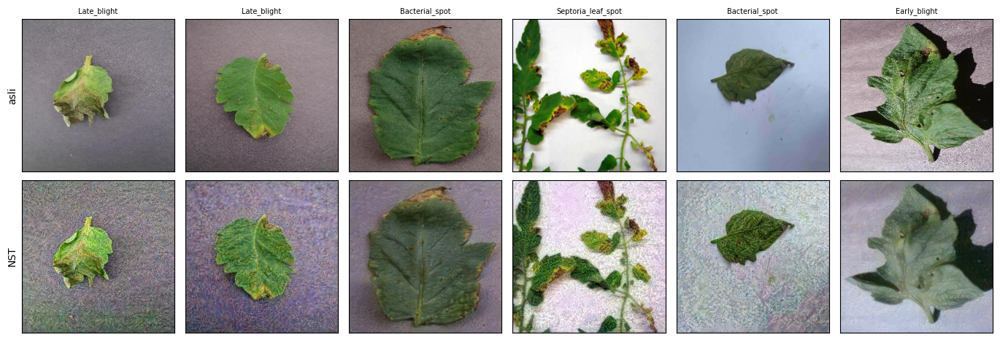

[   14.2m]   U-Net (gambar sintetis): 128/1200 (0s)
[   14.2m] Status data sintetis: {'sd': 'ok (450 gambar)', 'nst': 'ok (1200 gambar)', 'gan': 'dibuat per fold luar'} | UE5: tidak ada | fase mask+sintetis 2.3 menit


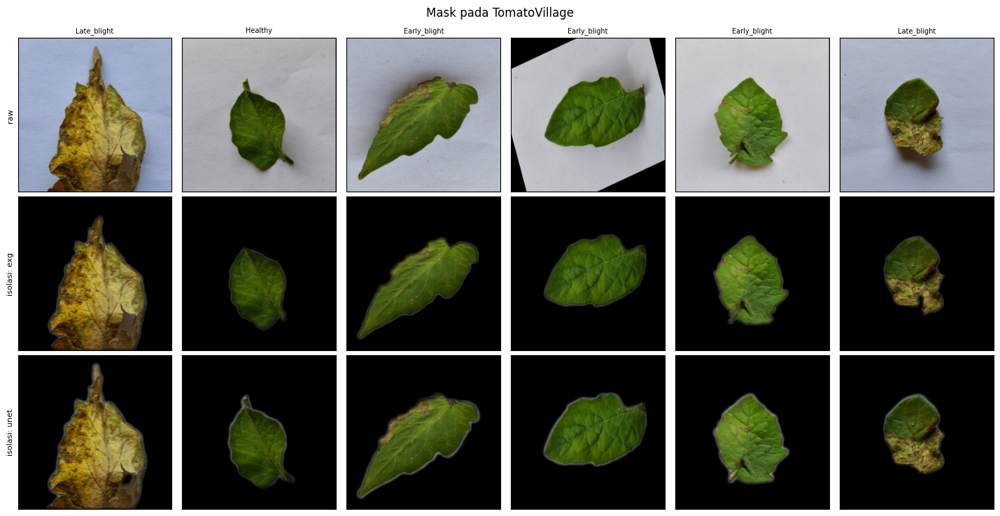

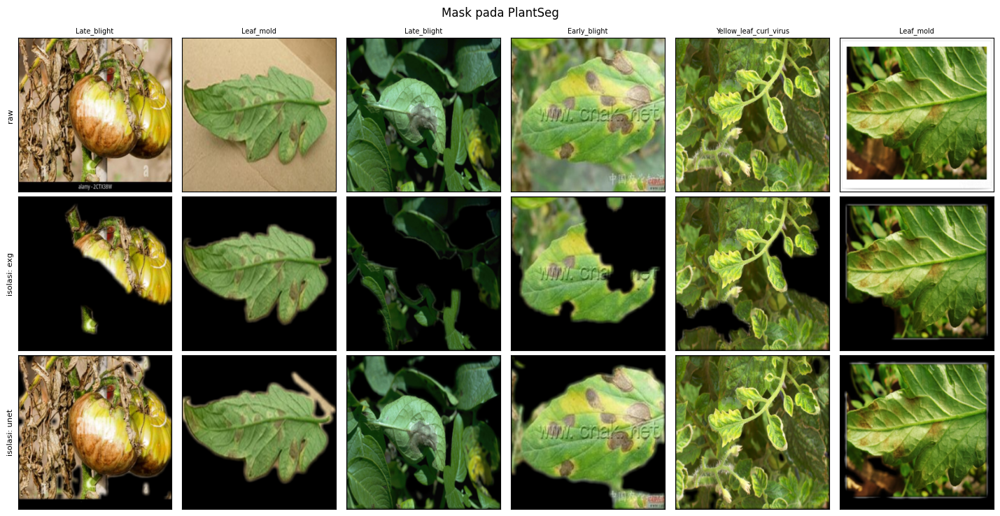

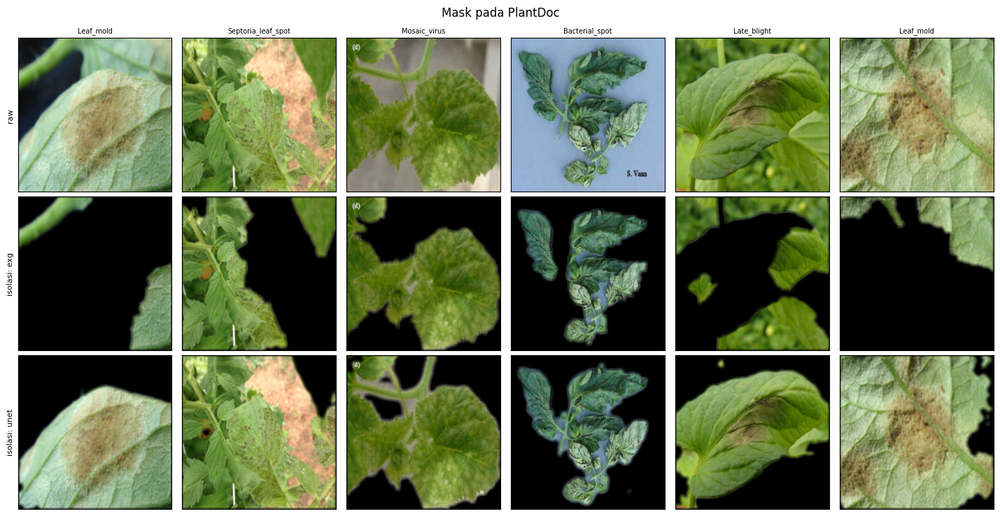

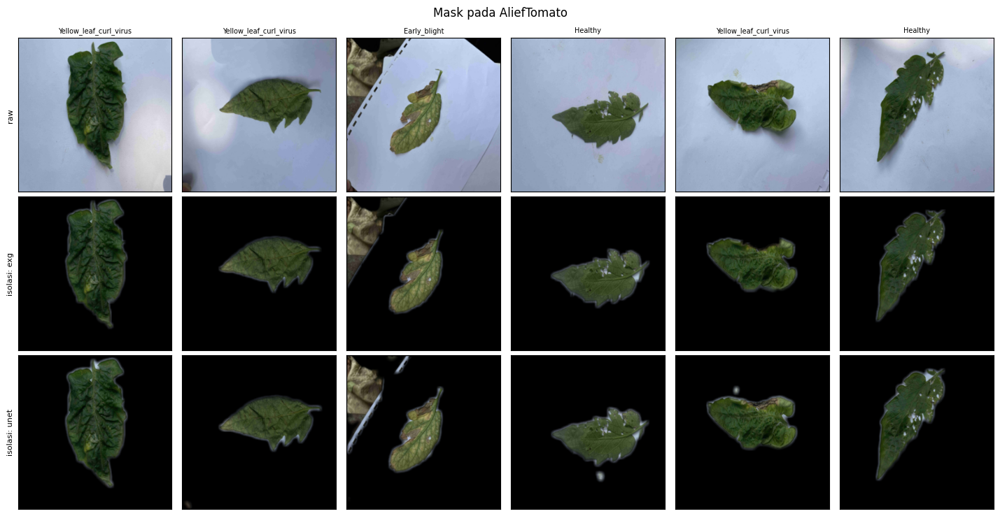

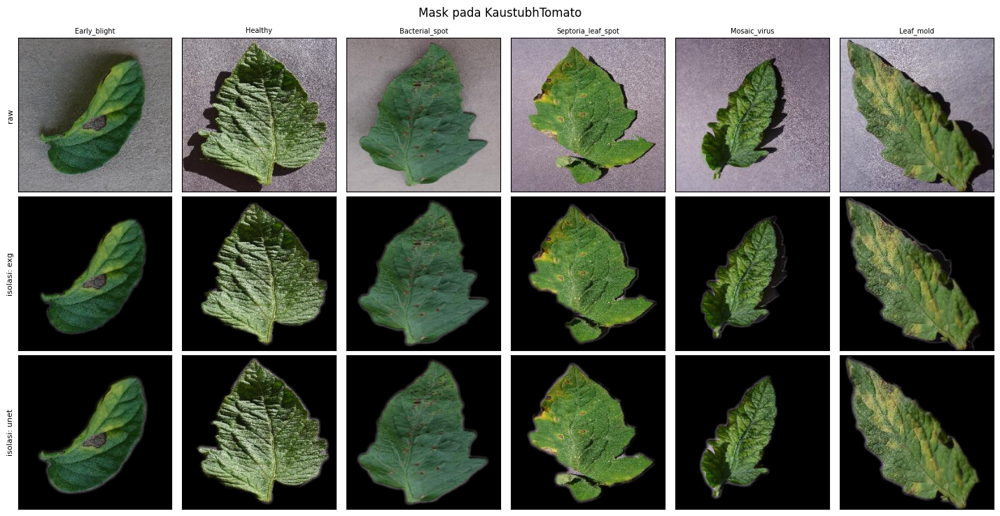

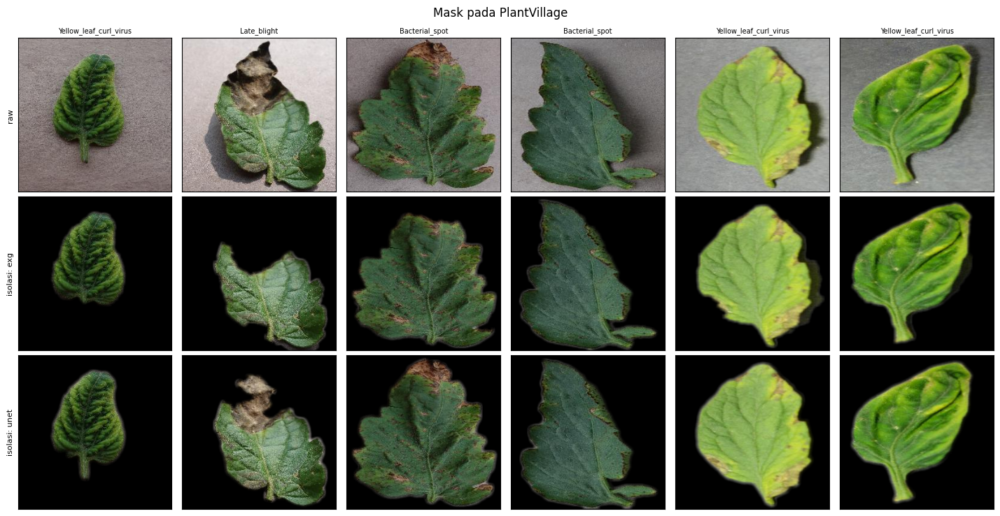

[   14.4m]   bank lesi: 3119 instans dari 800 gambar | per kelas: {'Bacterial_spot': 2161, 'Early_blight': 113, 'Late_blight': 845}


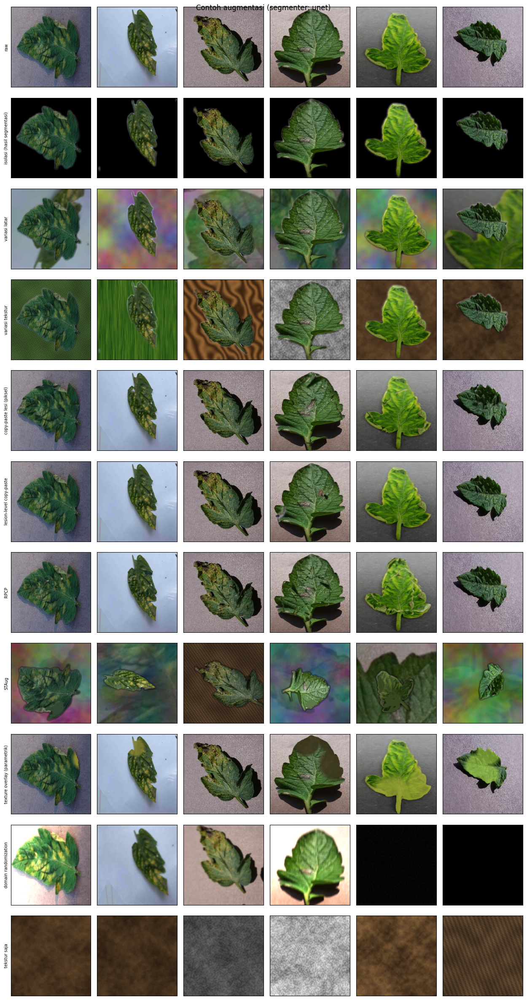

[   14.5m] DILEWATI (mask/sintetis/UE5 tidak tersedia): ['Synthetic UE5']
[   14.5m] Metode yang akan dilatih: ['DAPR-AM-Net [Baseline]', 'ExG+Otsu+GrabCut', 'U-Net (ResNet34)', 'Raw+Seg (campur)', 'Raw+Seg+Latar', 'Raw+Seg+Tekstur', 'Aug lengkap (Latar+Tekstur+CopyPaste)', 'Aug lengkap + Rebalancing generatif', 'Aug lengkap + Multi-channel', 'Aug lengkap + Curriculum', 'BgRecomp+LesionCP+GAN rebal', 'Domain randomization', 'RPCP', 'STAug', 'Lesion-level copy-paste', 'Texture overlay (parametrik)', 'Neural style transfer', 'Raw+Mask+BgRecomposed', 'CycleGAN/AR-GAN rebalancing', 'ALL-aug (gabungan semua)']


In [20]:
phase_t0 = time.time()
NEED_BANKS = []
for _m in RUN_METHODS:
    b_ = SPECS[_m]['bank']
    if b_ and b_ not in NEED_BANKS: NEED_BANKS.append(b_)
if NEW_SEG not in NEED_BANKS: NEED_BANKS.append(NEW_SEG)        # dipakai juga untuk evaluasi `*_iso` semua metode
BANK_FAIL = {}
for _b in sorted(NEED_BANKS, key=lambda b: ['exg', 'unet', 'sam'].index(b)):          # exg (CPU) dulu, lalu U-Net, lalu SAM (GPU)
    try:
        ensure_bank(_b)
    except Exception as e:
        BANK_FAIL[_b] = f'{type(e).__name__}: {str(e)[:200]}'; log(f'GAGAL membuat bank {_b}: {BANK_FAIL[_b]}'); traceback.print_exc()
if 'unet' in BANKS and 'val_idx' not in GT:
    try: build_gt()
    except Exception as e: log('build_gt untuk diagnostik gagal:', e)
if DIAG: print(pd.DataFrame(DIAG).round(2).to_string(index=False))

# sintetis GLOBAL (SD Img2Img, NST); GAN dibuat per fold di loop training
NEEDS = lambda kind: any(kind in SPECS[m].get('syn', ()) for m in RUN_METHODS)
SYN_STATUS = {'sd': 'tidak diminta', 'nst': 'tidak diminta', 'gan': 'dibuat per fold luar' if (GAN_ON and NEEDS('gan')) else ('dimatikan' if NEEDS('gan') else 'tidak diminta')}
for kind, on, fn in (('sd', SD_ON, generate_rebalance), ('nst', NST_ON, generate_nst)):
    if not NEEDS(kind): continue
    if not on: SYN_STATUS[kind] = 'dimatikan (--no-gen/--no-' + kind + ')'; continue
    if not BANKS: SYN_STATUS[kind] = 'dilewati (tidak ada bank mask)'; continue
    try:
        rows_ = fn(); fill_syn_masks(rows_); SYN_STATUS[kind] = f'ok ({len(rows_)} gambar)'
    except Exception as e:
        SYN_STATUS[kind] = f'GAGAL: {type(e).__name__}: {str(e)[:200]}'; log(f'Pembangkitan {kind} dilewati:', SYN_STATUS[kind]); traceback.print_exc()
log('Status data sintetis:', SYN_STATUS, f'| UE5: {"ada, " + str(len(UE5_ROWS)) + " gambar" if HAS_UE5 else "tidak ada"} | fase mask+sintetis {(time.time()-phase_t0)/60:.1f} menit')
for _f in (show_mask_examples, show_aug_examples):
    try: _f()
    except Exception as e: log(f'{_f.__name__} gagal (tidak menghentikan notebook):', type(e).__name__, e)

def usable(m):
    s = SPECS[m]
    if s.get('bank') and s['bank'] not in BANKS: return False
    if s.get('ue5') and not HAS_UE5 and not s.get('syn_opt'): return False
    if not s.get('syn_opt'):
        for k in s.get('syn', ()):
            if k == 'gan' and not GAN_ON: return False
            if k in ('sd', 'nst') and not (SYN_KIND[:_SYN['ptr']] == k).any(): return False
    return True
RUN_LIST = [m for m in RUN_METHODS if usable(m)]
if len(RUN_LIST) < len(RUN_METHODS): log('DILEWATI (mask/sintetis/UE5 tidak tersedia):', [m for m in RUN_METHODS if m not in RUN_LIST])
log('Metode yang akan dilatih:', RUN_LIST)


## 10. Training dan evaluasi

In [21]:
# ---- PENJELASAN KODE ----
# 1. Loop training sama dengan notebook lama: sampler seimbang kelas (1/N), mixup adaptif, label smoothing, loss bantu, loss atensi, early stopping (val loss).
# 2. Yang berbeda: input latih dibangun oleh `build_train_input` (bagian 4) menurut `spec`; model multi-channel punya 7 channel input.
# 3. `evaluate()` menghitung metrik pada val PlantVillage, PlantDoc, PlantSeg, masing-masing pada gambar raw dan daun terisolasi (`_iso`).
def fetch_mask(bank, idx):
    return torch.from_numpy(bank[np.asarray(idx)]).to(DEV, non_blocking=True).float().unsqueeze(1)

@torch.no_grad()
def predict(model, idx, bank=None, mc=False, iso=False, bs=128):
    model.eval(); L = []
    for s in range(0, len(idx), bs):
        ch = idx[s:s + bs]; x = fetch(ch); m = fetch_mask(bank, ch) if bank is not None else None
        inp = build_eval_input(x, m, mc, iso).contiguous(memory_format=torch.channels_last)
        with autocast(): o = model(inp)
        L.append(o['logits'].float().cpu())
    return torch.cat(L).numpy()

def train_model(tr, va, spec, seed, tag):
    seed_everything(seed)
    mc = bool(spec.get('mc')); bank = BANKS[spec['bank']] if spec.get('bank') else None
    model = build(in_ch=7 if mc else 3)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG['LR_DAPR'], weight_decay=CFG['WD_DAPR']); bs = CFG['BATCH']
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='min', factor=0.4, patience=1); scaler = GradScaler()
    E = CFG['EPOCHS']; ytr = Y_all[TI(tr)]; counts = torch.bincount(ytr, minlength=C).float().clamp_min(1)
    samp_w = (1.0 / counts)[ytr]; gamma = 1.0 / counts.sqrt(); cw_d = ((1.0 / counts) / (1.0 / counts).mean()).to(DEV)
    omega = torch.ones(len(Y_all)); beta_dist = torch.distributions.Beta(CFG['MIX_ALPHA'], CFG['MIX_ALPHA'])
    ls = CFG['LABEL_SMOOTH']; steps = max(1, len(tr) // bs); best, best_state, bad, hist = 1e9, None, 0, []
    for ep in range(E):
        model.train(); t0 = time.time(); tl = 0.0
        order = tr[torch.multinomial(samp_w, len(tr), replacement=True).numpy()]; beta_t = CFG['BETA_AUX_MAX'] * (ep + 1) / E
        for st in range(steps):
            bidx = order[st * bs:(st + 1) * bs]
            if len(bidx) < 2: continue
            y = Y_all[TI(bidx)].to(DEV); xb = fetch(bidx); mb = fetch_mask(bank, bidx) if bank is not None else None
            x = build_train_input(xb, mb, y, spec, ep, E); B = x.shape[0]
            lam2 = torch.ones(B, device=DEV); ya = yb = y; mixed = False
            if random.random() < CFG['MIX_P'] and bool(torch.isfinite(omega[TI(bidx)]).all()):
                mixed = True; perm = torch.randperm(B, device=DEV); lam = beta_dist.sample((B,)).to(DEV)
                wi = omega[TI(bidx)].to(DEV); wj = wi[perm]; lam1 = lam * wi / (lam * wi + (1 - lam) * wj + 1e-8)
                gi = gamma.to(DEV)[y]; gj = gi[perm]; lam2 = lam1 * gi / (lam1 * gi + (1 - lam1) * gj + 1e-8)
                x = lam2.view(B, 1, 1, 1) * x + (1 - lam2.view(B, 1, 1, 1)) * x[perm]; yb = y[perm]
            x = x.contiguous(memory_format=torch.channels_last)
            with autocast():
                o = model(x); sw = lam2 * cw_d[ya] + (1 - lam2) * cw_d[yb]
                def mix_ce(lg):
                    lg = lg.float()
                    return (sw * (lam2 * F.cross_entropy(lg, ya, label_smoothing=ls, reduction='none') + (1 - lam2) * F.cross_entropy(lg, yb, label_smoothing=ls, reduction='none'))).mean()
                loss = mix_ce(o['logits']) + beta_t * sum(mix_ce(a) for a in o['aux'])
                loss = loss + CFG['LAMBDA_ATT'] * F.mse_loss(o['att'].float(), o['att_ref'].float())
            if not mixed: omega[TI(bidx)] = o['att'].detach().float().mean((1, 2, 3)).cpu().clamp_min(1e-3)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); scaler.step(opt); scaler.update(); tl += loss.item()
        lv = torch.from_numpy(predict(model, va, bank=bank if mc else None, mc=mc)); yva = Y_all[TI(va)]
        vloss = F.cross_entropy(lv, yva).item(); vacc = (lv.argmax(1) == yva).float().mean().item(); sched.step(vloss)
        hist.append(dict(epoch=ep + 1, train_loss=tl / steps, val_loss=vloss, val_acc=vacc, lr=opt.param_groups[0]['lr'], sec=time.time() - t0))
        log(f'  {tag} ep{ep+1:02d} train_loss={tl/steps:.4f} val_loss={vloss:.4f} val_acc={vacc:.4f} ({time.time()-t0:.0f}s)')
        if vloss < best - 1e-4:
            best, bad = vloss, 0; best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= CFG['PATIENCE']: log(f'  {tag} early stopping @ epoch {ep+1}'); break
    if best_state is not None: model.load_state_dict(best_state)
    return model, pd.DataFrame(hist)

def evaluate(model, spec, name, seed, n_train, train_sec, n_ep):
    mc = bool(spec.get('mc')); bank_m = BANKS[spec['bank']] if spec.get('bank') else None; bank_iso = BANKS.get(NEW_SEG)
    R = dict(method=name, group=spec['group'], seed=seed, train_sec=train_sec, epochs_run=n_ep, n_train=int(n_train),
             params_M=sum(p.numel() for p in model.parameters()) / 1e6); arrs = {}
    for ds in EVAL_SETS:
        ix = IDX[ds]; y = meta.y.values[ix]
        for iso in (False, True):
            if iso and bank_iso is None: continue
            k = EVAL_NAME[ds] + ('_iso' if iso else ''); bank = bank_iso if iso else (bank_m if mc else None)
            lg = predict(model, ix, bank=bank, mc=mc, iso=iso)
            R.update(cls_metrics(lg, y, f'{k}_')); R[f'{k}_n'] = int(len(ix))
            arrs.update({f'{k}_y': y, f'{k}_pred': lg.argmax(1), f'{k}_logits': lg.astype(np.float16)})
    np.savez_compressed(os.path.join(OUT, 'preds', f'{slug(name)}__s{seed}.npz'), **arrs)
    return R

In [22]:
# ---- PENJELASAN KODE (evaluasi nested CV) ----
# 1. `evaluate_fold()` menguji model pada data UJI fold luar, TERPISAH per dataset (+ 'ALL' = gabungan), pada gambar raw dan daun terisolasi (`_iso`).
# 2. Metrik val dalam (`innerval_*`) ikut dicatat; dipakai untuk memilih metode TANPA menyentuh data uji (baris NESTED-SELECT di analisis).
# 3. Prediksi disimpan per job: preds/<metode>__f<fold>__s<seed>.npz (indeks gambar, label, prediksi, logit) -> analisis bisa digabung lintas fold.
def evaluate_fold(model, spec, name, seed, fold, fi, n_train, train_sec, n_ep):
    mc = bool(spec.get('mc')); bank_m = BANKS[spec['bank']] if spec.get('bank') else None; bank_iso = BANKS.get(NEW_SEG)
    R = dict(method=name, group=spec['group'], seed=seed, fold=fold, train_sec=train_sec, epochs_run=n_ep, n_train=int(n_train),
             params_M=sum(p.numel() for p in model.parameters()) / 1e6); arrs = {}
    va = fi['va']; lv = predict(model, va, bank=bank_m if mc else None, mc=mc); R.update(cls_metrics(lv, meta.y.values[va], 'innerval_'))
    te = fi['te']; src_te = meta.src.values[te]; y_te = meta.y.values[te]
    sets = {ds: np.where(src_te == ds)[0] for ds in DS_PRESENT}; sets['ALL'] = np.arange(len(te))
    for iso in (False, True):
        if iso and bank_iso is None: continue
        lg = predict(model, te, bank=bank_iso if iso else (bank_m if mc else None), mc=mc, iso=iso)
        for ds, sel in sets.items():
            if not len(sel): continue
            k = ds + ('_iso' if iso else ''); y = y_te[sel]
            R.update(cls_metrics(lg[sel], y, f'{k}_')); R[f'{k}_n'] = int(len(sel))
            arrs.update({f'{k}_idx': te[sel], f'{k}_y': y, f'{k}_pred': lg[sel].argmax(1), f'{k}_logits': lg[sel].astype(np.float16)})
    np.savez_compressed(os.path.join(OUT, 'preds', f'{slug(name)}__f{fold}__s{seed}.npz'), **arrs)
    return R


[   15.2m] Grid: 100 job (5 fold luar x 1 seed x 20 metode) | sudah selesai: 50
[   15.2m] RESUME: selesai per fold luar -> fold 0: 20/20 | fold 1: 20/20 | fold 2: 10/20 | fold 3: 0/20 | fold 4: 0/20
[   15.2m] RESUME: job pertama yang akan dilatih -> job 51/100: BgRecomp_LesionCP_GAN_rebal__f2__s42
[   15.2m] GAN fold 2: kelas minoritas {'Mosaic_virus': 953, 'Leaf_mold': 1171, 'Septoria_leaf_spot': 1437} | attn | 5.0 menit/kelas
[   16.2m]   [GAN f2 Mosaic_virus] it200 G=1.310 D=0.411 (61s)
[   17.2m]   [GAN f2 Mosaic_virus] it400 G=1.662 D=0.123 (122s)
[   18.2m]   [GAN f2 Mosaic_virus] it600 G=1.963 D=0.138 (183s)
[   19.3m]   [GAN f2 Mosaic_virus] it800 G=1.936 D=0.192 (244s)
[   20.2m]   [GAN f2 Mosaic_virus]: 984 iterasi dalam 5.0 menit
[   20.2m]   kelas Mosaic_virus: selisih rata-rata dari asal 0.001 | lolos 0/150
[   21.2m]   [GAN f2 Leaf_mold] it200 G=1.055 D=0.308 (61s)
[   22.3m]   [GAN f2 Leaf_mold] it400 G=1.228 D=0.275 (122s)
[   23.3m]   [GAN f2 Leaf_mold] it600 G=1.062

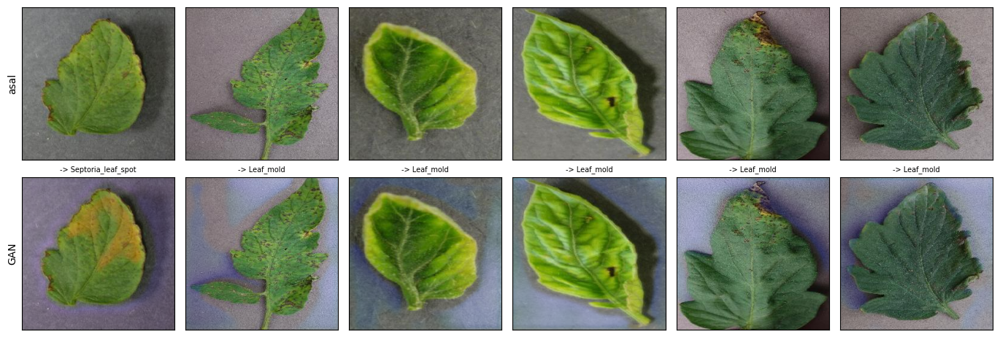

[   30.3m]   U-Net (gambar sintetis): 69/69 (1s)
[   30.3m] --- job 51/100: BgRecomp_LesionCP_GAN_rebal__f2__s42 (latih=14979 + sintetis/UE5=69 | val=1717 | uji=4043) ---
[   32.8m]   [BgRecomp_LesionCP_GAN_rebal__f2__s42] ep01 train_loss=1.0827 val_loss=0.4670 val_acc=0.8847 (144s)
[   33.8m]   [BgRecomp_LesionCP_GAN_rebal__f2__s42] ep02 train_loss=0.8726 val_loss=0.3067 val_acc=0.9260 (65s)
[   34.9m]   [BgRecomp_LesionCP_GAN_rebal__f2__s42] ep03 train_loss=0.8493 val_loss=0.3834 val_acc=0.9214 (65s)
[   36.0m]   [BgRecomp_LesionCP_GAN_rebal__f2__s42] ep04 train_loss=0.8544 val_loss=0.2925 val_acc=0.9336 (65s)
[   37.1m]   [BgRecomp_LesionCP_GAN_rebal__f2__s42] ep05 train_loss=0.8821 val_loss=0.2936 val_acc=0.9383 (65s)
[   38.2m]   [BgRecomp_LesionCP_GAN_rebal__f2__s42] ep06 train_loss=0.9004 val_loss=0.2577 val_acc=0.9418 (65s)
[   39.2m]   [BgRecomp_LesionCP_GAN_rebal__f2__s42] ep07 train_loss=0.9227 val_loss=0.2973 val_acc=0.9278 (65s)
[   40.3m]   [BgRecomp_LesionCP_GAN_rebal__f

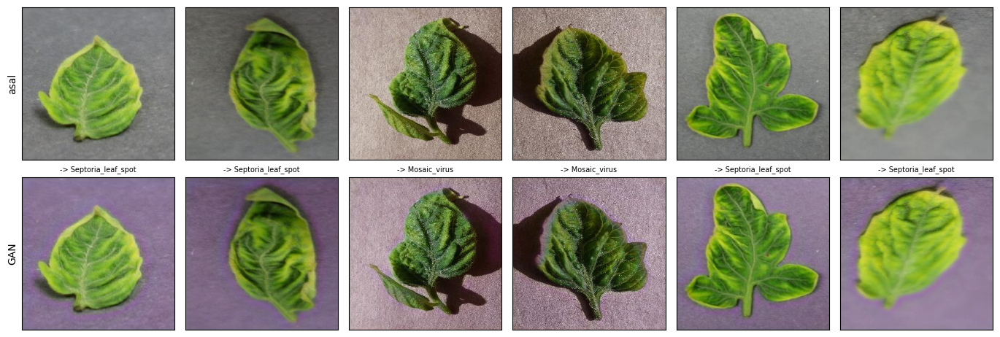

[  273.5m]   U-Net (gambar sintetis): 14/14 (0s)
[  273.5m] --- job 71/100: BgRecomp_LesionCP_GAN_rebal__f3__s42 (latih=14687 + sintetis/UE5=14 | val=2005 | uji=4047) ---
[  274.5m]   [BgRecomp_LesionCP_GAN_rebal__f3__s42] ep01 train_loss=1.0621 val_loss=0.3298 val_acc=0.9242 (63s)
[  275.6m]   [BgRecomp_LesionCP_GAN_rebal__f3__s42] ep02 train_loss=0.8515 val_loss=0.2502 val_acc=0.9441 (63s)
[  276.7m]   [BgRecomp_LesionCP_GAN_rebal__f3__s42] ep03 train_loss=0.8486 val_loss=0.2286 val_acc=0.9486 (63s)
[  277.7m]   [BgRecomp_LesionCP_GAN_rebal__f3__s42] ep04 train_loss=0.8326 val_loss=0.2249 val_acc=0.9531 (63s)
[  278.8m]   [BgRecomp_LesionCP_GAN_rebal__f3__s42] ep05 train_loss=0.8677 val_loss=0.2558 val_acc=0.9431 (63s)
[  279.8m]   [BgRecomp_LesionCP_GAN_rebal__f3__s42] ep06 train_loss=0.8991 val_loss=0.2466 val_acc=0.9576 (63s)
[  280.9m]   [BgRecomp_LesionCP_GAN_rebal__f3__s42] ep07 train_loss=0.8714 val_loss=0.1956 val_acc=0.9606 (63s)
[  281.9m]   [BgRecomp_LesionCP_GAN_rebal__f3

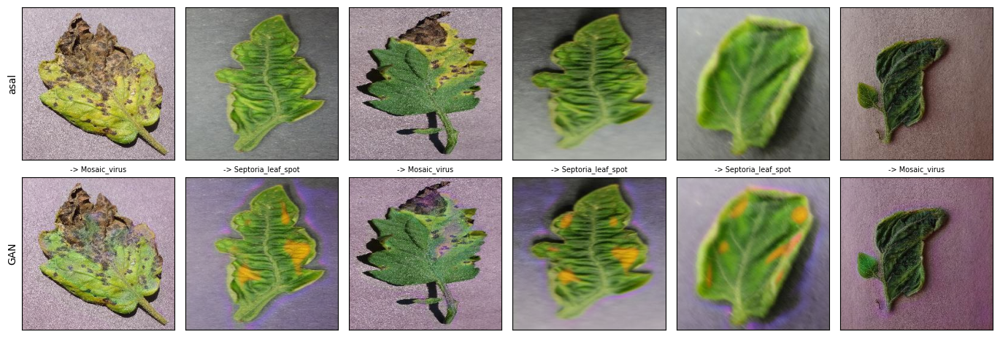

[  515.6m]   U-Net (gambar sintetis): 36/36 (1s)
[  515.6m] --- job 91/100: BgRecomp_LesionCP_GAN_rebal__f4__s42 (latih=14989 + sintetis/UE5=36 | val=1706 | uji=4044) ---
[  516.7m]   [BgRecomp_LesionCP_GAN_rebal__f4__s42] ep01 train_loss=1.0768 val_loss=0.3640 val_acc=0.9068 (64s)
[  517.7m]   [BgRecomp_LesionCP_GAN_rebal__f4__s42] ep02 train_loss=0.8655 val_loss=0.3099 val_acc=0.9209 (64s)
[  518.8m]   [BgRecomp_LesionCP_GAN_rebal__f4__s42] ep03 train_loss=0.8494 val_loss=0.2774 val_acc=0.9320 (64s)
[  519.9m]   [BgRecomp_LesionCP_GAN_rebal__f4__s42] ep04 train_loss=0.8450 val_loss=0.2585 val_acc=0.9390 (65s)
[  521.0m]   [BgRecomp_LesionCP_GAN_rebal__f4__s42] ep05 train_loss=0.8707 val_loss=0.2297 val_acc=0.9502 (65s)
[  522.0m]   [BgRecomp_LesionCP_GAN_rebal__f4__s42] ep06 train_loss=0.8968 val_loss=0.2382 val_acc=0.9426 (65s)
[  523.1m]   [BgRecomp_LesionCP_GAN_rebal__f4__s42] ep07 train_loss=0.9023 val_loss=0.2389 val_acc=0.9519 (65s)
[  524.2m]   [BgRecomp_LesionCP_GAN_rebal__f4

In [23]:
# ---- PENJELASAN KODE ----
# 1. Urutan job: FOLD LUAR -> seed -> metode (fold-major: satu fold selesai untuk semua metode sebelum fold berikutnya, jadi bila waktu habis hasilnya tetap bisa dibandingkan adil).
# 2. Tiap job: data latih = fold-dalam latih (semua dataset) + gambar sintetis yang induknya ada di data latih fold itu (+ render UE5 bila metode memakainya).
#    Val dalam = early stopping. Uji fold luar hanya dipakai di evaluate_fold().
# 3. Hasil tiap job ditulis ke runs/<id>.json HANYA setelah selesai; job yang sudah ada dilewati (aman dilanjutkan, juga lewat --resume-from).
# 4. Sebelum tiap job, waktu dicek; bila perkiraan selesai melewati --max-seconds (dikurangi cadangan analisis), loop berhenti rapi.
MAX_SEC = ARGS.max_seconds; RESERVE = 15 * 60; elapsed = lambda: time.time() - T0
FI = {k: fold_indices(k) for k in OUTER_RUN}
JOBS = [dict(fold=f, seed=s, name=m, id=f'{slug(m)}__f{f}__s{s}') for f in OUTER_RUN for s in ARGS.seeds for m in RUN_LIST]
is_done = lambda j: os.path.exists(os.path.join(OUT, 'runs', j['id'] + '.json'))
JOBLOG = os.path.join(OUT, 'logs', 'job_log.csv'); dur = []; FAILS = defaultdict(int); BLOCKED = {}; stop_reason = 'selesai semua job'
GAN_ROWS, GAN_FAIL, LB_KEY = {}, {}, [None]
log(f'Grid: {len(JOBS)} job ({len(OUTER_RUN)} fold luar x {len(ARGS.seeds)} seed x {len(RUN_LIST)} metode) | sudah selesai: {sum(is_done(j) for j in JOBS)}')
_pf = {f_: (sum(is_done(j_) for j_ in JOBS if j_['fold'] == f_), sum(1 for j_ in JOBS if j_['fold'] == f_)) for f_ in OUTER_RUN}
log('RESUME: selesai per fold luar -> ' + ' | '.join(f'fold {f_}: {d_}/{t_}' for f_, (d_, t_) in _pf.items()))
_nx = next((j_ for j_ in JOBS if not is_done(j_)), None)
log('RESUME: job pertama yang akan dilatih -> ' + (f'job {JOBS.index(_nx) + 1}/{len(JOBS)}: {_nx["id"]}' if _nx else 'TIDAK ADA (semua job sudah selesai, langsung ke analisis)'))
for n_, j in enumerate(JOBS, 1):
    if is_done(j) or j['name'] in BLOCKED: continue
    est = (max(dur) * 1.15) if dur else 0
    if elapsed() + est + RESERVE > MAX_SEC:
        stop_reason = f'batas waktu: sisa {(MAX_SEC-elapsed())/60:.0f} menit < perkiraan job ({est/60:.0f} menit) + cadangan analisis'; log('BERHENTI -', stop_reason); break
    spec = SPECS[j['name']]; fold = j['fold']; fi = FI[fold]; t0_ = time.time(); status = 'ok'
    try:
        kinds = [k for k in spec.get('syn', ()) if not (k == 'gan' and not GAN_ON)]
        if 'gan' in kinds and fold not in GAN_ROWS and fold not in GAN_FAIL:
            try: r_ = generate_gan(fold, fi['tr']); fill_syn_masks(r_); GAN_ROWS[fold] = r_
            except Exception as e: GAN_FAIL[fold] = f'{type(e).__name__}: {str(e)[:200]}'; log(f'GAN fold {fold} GAGAL:', GAN_FAIL[fold]); traceback.print_exc()
        if 'gan' in spec.get('syn', ()) and fold in GAN_FAIL and not spec.get('syn_opt'): raise RuntimeError('GAN fold gagal -> metode dilewati: ' + GAN_FAIL[fold])
        tr_set = set(fi['tr'].tolist()); extra = syn_select(kinds, tr_set, fold) if kinds else np.array([], dtype=np.int64)
        if spec.get('ue5') and HAS_UE5: extra = np.concatenate([extra, UE5_ROWS])
        tr = np.concatenate([fi['tr'], extra]).astype(np.int64)
        if spec.get('lcp', 0) > 0:
            key = (fold, spec['bank'])
            if LB_KEY[0] != key: build_lesion_bank(fi['tr'], BANKS[spec['bank']] if spec.get('bank') else None, seed=fold); LB_KEY[0] = key
        log(f'--- job {n_}/{len(JOBS)}: {j["id"]} (latih={len(fi["tr"])} + sintetis/UE5={len(extra)} | val={len(fi["va"])} | uji={len(fi["te"])}) ---')
        model, hist = train_model(tr, fi['va'], spec, j['seed'], f'[{j["id"]}]')
        R = evaluate_fold(model, spec, j['name'], j['seed'], fold, fi, len(tr), time.time() - t0_, len(hist)); R['n_extra'] = int(len(extra))
        hist.to_csv(os.path.join(OUT, 'logs', f'hist_{j["id"]}.csv'), index=False)
        tmp = os.path.join(OUT, 'runs', j['id'] + '.json.tmp'); json.dump(R, open(tmp, 'w'), indent=1, default=float); os.replace(tmp, tmp[:-4])
        log(f'   selesai {j["id"]} dalam {(time.time()-t0_)/60:.1f} menit | ALL acc={R.get("ALL_acc", float("nan")):.4f} F1={R.get("ALL_macro_f1", float("nan")):.4f} | ' +
            ' '.join(f'{d}={R.get(d + "_macro_f1", float("nan")):.3f}' for d in DS_PRESENT))
        dur.append(time.time() - t0_); del model
    except Exception as e:
        status = f'GAGAL {type(e).__name__}: {str(e)[:150]}'; log('   ', status); traceback.print_exc(); FAILS[j['name']] += 1
        if FAILS[j['name']] >= 2: BLOCKED[j['name']] = status; log(f'   METODE DIBLOKIR: {j["name"]}')
    gc_ = __import__('gc'); gc_.collect(); torch.cuda.empty_cache() if DEV.type == 'cuda' else None
    pd.DataFrame([dict(job=j['id'], status=status, minutes=round((time.time() - t0_) / 60, 2))]).to_csv(JOBLOG, mode='a', header=not os.path.exists(JOBLOG), index=False)
log(f'Training selesai ({stop_reason}). Total waktu: {elapsed()/3600:.2f} jam')


## 11. Analisis hasil (nested CV)

Prediksi uji semua fold digabung (out-of-fold) per dataset dan `ALL`. Uji berpasangan vs baseline: McNemar eksak + CI bootstrap + Holm. Baris `NESTED-SELECT` = metode dipilih lewat val dalam, tanpa menyentuh uji. Kriteria 'mengalahkan baseline' ketat: Holm p<0,05, ΔF1>0, batas bawah CI>0.

In [24]:
# ---- PENJELASAN KODE ----
# 1. `holm`, `mcnemar_exact`, `bootstrap_dist` sama dengan notebook lama. Hanya seed yang selesai untuk SEMUA metode dipakai untuk uji berpasangan.
# 2. Tanda signifikansi: Holm-p < 0,05 pada McNemar eksak terhadap baseline.
KEYS_ALL = ['plantdoc', 'plantseg', 'plantdoc_iso', 'plantseg_iso', 'pv_val', 'pv_val_iso']
KEY_LABEL = {'plantdoc': 'PlantDoc', 'plantseg': 'PlantSeg', 'plantdoc_iso': 'PlantDoc (daun terisolasi)', 'plantseg_iso': 'PlantSeg (daun terisolasi)',
             'pv_val': 'PV val (in-domain)', 'pv_val_iso': 'PV val (terisolasi)'}
def holm(p):
    p = np.asarray(p, float); n = len(p); o = np.argsort(p); adj = np.empty(n); run = 0.0
    for r, i in enumerate(o): run = max(run, (n - r) * p[i]); adj[i] = min(1.0, run)
    return adj
def md_table(df, floatfmt='{:.4f}'):
    cols = list(df.columns)
    f = lambda v: ('' if np.isnan(v) else floatfmt.format(v)) if isinstance(v, (float, np.floating)) else str(v)
    return '\n'.join(['| ' + ' | '.join(map(str, cols)) + ' |', '|' + '|'.join(['---'] * len(cols)) + '|'] + ['| ' + ' | '.join(f(r[c]) for c in cols) + ' |' for _, r in df.iterrows()])
def conf_counts(y, pred): return np.bincount(y * C + pred, minlength=C * C).reshape(C, C)
def f1_acc_from_conf(cm, present):
    tp = np.diag(cm).astype(float); sup = cm.sum(1); pr = cm.sum(0)
    f1 = np.where(sup + pr > 0, 2 * tp / np.maximum(sup + pr, 1), 0.0); return float(tp.sum() / max(cm.sum(), 1)), float(f1[present].mean())
def mcnemar_exact(ok_m, ok_r):
    b = int((ok_m & ~ok_r).sum()); c = int((~ok_m & ok_r).sum())
    return b, c, (1.0 if b + c == 0 else float(stats.binomtest(b, b + c, 0.5).pvalue))
def bootstrap_dist(y, P, idx_list, present):
    acc = np.zeros(len(idx_list)); f1 = np.zeros(len(idx_list))
    for b, ix in enumerate(idx_list):
        r_ = [f1_acc_from_conf(conf_counts(y[ix], P[r, ix]), present) for r in range(P.shape[0])]; acc[b] = np.mean([a for a, _ in r_]); f1[b] = np.mean([f for _, f in r_])
    return acc, f1
def build_preds(methods, key, seeds):
    y, P = None, {}
    for m in methods:
        rows = []
        for s in seeds:
            z = np.load(os.path.join(OUT, 'preds', f'{slug(m)}__s{s}.npz'))
            if f'{key}_pred' not in z.files: return None, None
            rows.append(z[f'{key}_pred']); y = z[f'{key}_y']
        P[m] = np.stack(rows)
    return y, P

def analyze():
    tab = TAB; fig = FIG; cmdir = os.path.join(OUT, 'confusion_matrices')
    df = pd.DataFrame([json.load(open(f)) for f in sorted(glob.glob(os.path.join(OUT, 'runs', '*.json')))])
    if df.empty: print('Tidak ada hasil di', os.path.join(OUT, 'runs')); return
    df.to_csv(os.path.join(OUT, 'results_per_run.csv'), index=False)
    methods = [m for m in METHOD_ORDER if m in set(df.method)]
    keys = [k for k in KEYS_ALL if f'{k}_acc' in df.columns and df[f'{k}_acc'].notna().any()]
    common = sorted(set.intersection(*[set(df[df.method == m].seed) for m in methods]))
    use = df[df.seed.isin(common)] if common else df
    if not common: print('PERINGATAN: tidak ada seed yang selesai untuk semua metode -> uji berpasangan dilewati.')
    print('Metode:', methods, '| seed bersama:', common)
    # ---------- 1. ringkasan metrik ----------
    rows = []
    for m in methods:
        d = use[use.method == m]
        for k in keys:
            r = dict(dataset=k, dataset_label=KEY_LABEL[k], method=m, group=GROUP.get(m, ''), n_runs=len(d))
            for met in ('acc', 'macro_f1', 'macro_precision', 'macro_recall', 'bal_acc', 'mcc', 'nll', 'ece'):
                c = f'{k}_{met}'
                if c in d: r[f'{met}_mean'] = d[c].mean(); r[f'{met}_std'] = d[c].std(ddof=1) if len(d) > 1 else np.nan
            rows.append(r)
    S_ = pd.DataFrame(rows)
    fmt = lambda mu, sd: f'{mu*100:.1f}' + (f' ± {sd*100:.1f}' if not np.isnan(sd) else '')
    main = pd.DataFrame({'Metode': methods, 'Kelompok': [GROUP.get(m, '') for m in methods]})
    for k in keys:
        for met, lab in (('acc', 'acc'), ('macro_f1', 'F1')):
            sub = S_[S_.dataset == k].set_index('method'); main[f'{KEY_LABEL[k]} {lab}'] = [fmt(sub.loc[m, f'{met}_mean'], sub.loc[m, f'{met}_std']) for m in methods]
    main.to_csv(os.path.join(tab, 'main_table.csv'), index=False)
    # ---------- 2. signifikansi vs baseline ----------
    sig = []
    if common and M_BASE in methods and len(methods) > 1:
        rng = np.random.RandomState(0)
        for k in keys:
            y, P = build_preds(methods, k, common)
            if y is None: continue
            present = sorted(set(y.tolist())); idx_list = [rng.randint(0, len(y), len(y)) for _ in range(ARGS.boot if not QUICK else 50)]
            ba, bf = bootstrap_dist(y, P[M_BASE], idx_list, present); rec = []
            for m in methods:
                if m == M_BASE: continue
                ps = [mcnemar_exact(P[m][r] == y, P[M_BASE][r] == y) for r in range(len(common))]
                ma, mf = bootstrap_dist(y, P[m], idx_list, present); da, df_ = ma - ba, mf - bf
                rec.append(dict(dataset=k, dataset_label=KEY_LABEL[k], method=m, delta_acc=float(da.mean()), acc_ci_lo=float(np.percentile(da, 2.5)), acc_ci_hi=float(np.percentile(da, 97.5)),
                                delta_f1=float(df_.mean()), f1_ci_lo=float(np.percentile(df_, 2.5)), f1_ci_hi=float(np.percentile(df_, 97.5)),
                                mcnemar_b_better=int(np.median([p[0] for p in ps])), mcnemar_c_worse=int(np.median([p[1] for p in ps])), mcnemar_p=float(np.median([p[2] for p in ps]))))
            for r_, h in zip(rec, holm([r['mcnemar_p'] for r in rec])): r_['mcnemar_p_holm'] = float(h); r_['signif'] = ('▲' if r_['delta_acc'] > 0 else '▼') if h < 0.05 else ''
            sig += rec
    SG = pd.DataFrame(sig); SG.to_csv(os.path.join(OUT, 'significance_vs_baseline.csv'), index=False)
    # ---------- 3. per kelas + confusion matrix ----------
    CM, pc = {}, []
    for k in [k for k in ('plantdoc', 'plantseg') if k in keys]:
        for m in methods:
            cm = np.zeros((C, C), int)
            for s in (common or sorted(use[use.method == m].seed)):
                z = np.load(os.path.join(OUT, 'preds', f'{slug(m)}__s{s}.npz'))
                if f'{k}_pred' in z.files: cm += conf_counts(z[f'{k}_y'], z[f'{k}_pred'])
            if cm.sum() == 0: continue
            CM[(m, k)] = cm; pd.DataFrame(cm, index=ID_CLASSES, columns=ID_CLASSES).to_csv(os.path.join(cmdir, f'cm_{k}_{slug(m)}.csv'))
            tp = np.diag(cm); sup = cm.sum(1); pr = cm.sum(0)
            for i in range(C):
                if sup[i] == 0: continue
                P_ = tp[i] / pr[i] if pr[i] else 0.0; R_ = tp[i] / sup[i]
                pc.append(dict(dataset=k, method=m, cls=ID_CLASSES[i], support=int(sup[i]), precision=P_, recall=R_, f1=(2 * P_ * R_ / (P_ + R_)) if P_ + R_ else 0.0))
    PC = pd.DataFrame(pc); PC.to_csv(os.path.join(tab, 'per_class_metrics.csv'), index=False)
    for k in sorted({k for _, k in CM}):
        ms = [m for m in methods if (m, k) in CM]; nc = min(4, len(ms)); nr = math.ceil(len(ms) / nc)
        fg, axes = plt.subplots(nr, nc, figsize=(4.4 * nc, 4.2 * nr), squeeze=False)
        for ax in axes.ravel(): ax.axis('off')
        for ax, m in zip(axes.ravel(), ms):
            cm = CM[(m, k)]; rp = cm / np.maximum(cm.sum(1, keepdims=True), 1); ax.axis('on'); ax.imshow(rp, cmap='Blues', vmin=0, vmax=1)
            ax.set_xticks(range(C)); ax.set_yticks(range(C)); ax.set_xticklabels(range(C), fontsize=7); ax.set_yticklabels(range(C), fontsize=7)
            for i in range(C):
                for j in range(C): ax.text(j, i, f'{rp[i, j]*100:.0f}', ha='center', va='center', fontsize=6, color='white' if rp[i, j] > .5 else 'black')
            ax.set_title(textwrap.fill(m, 32) + f'\nacc={np.trace(cm)/max(cm.sum(),1)*100:.1f}%', fontsize=8)
        fg.suptitle(f'Confusion matrix (% per baris), {KEY_LABEL[k]}. Kelas: ' + ', '.join(f'{i}={c}' for i, c in enumerate(ID_CLASSES)), fontsize=9)
        fg.tight_layout(); fg.savefig(os.path.join(fig, f'cm_{k}.png'), dpi=140, bbox_inches='tight'); plt.show()
    # ---------- 4. grafik macro-F1 ----------
    pk = [k for k in ('plantdoc', 'plantseg', 'plantdoc_iso', 'plantseg_iso') if k in keys]
    if pk:
        fg, axes = plt.subplots(1, len(pk), figsize=(4.6 * len(pk), 0.45 * len(methods) + 1.6), squeeze=False)
        for ax, k in zip(axes[0], pk):
            sub = S_[S_.dataset == k].set_index('method').loc[methods]; yv = np.arange(len(methods))[::-1]
            ax.barh(yv, sub.macro_f1_mean * 100, xerr=(sub.macro_f1_std * 100).fillna(0), color=['#888' if m == M_BASE else '#3b7dd8' for m in methods])
            ax.set_yticks(yv); ax.set_yticklabels([textwrap.fill(m, 28) for m in methods] if k == pk[0] else [], fontsize=7); ax.set_title(KEY_LABEL[k] + ': macro-F1 (%)', fontsize=9)
            ax.axvline(sub.loc[M_BASE, 'macro_f1_mean'] * 100 if M_BASE in sub.index else 0, color='r', ls='--', lw=0.8)
        fg.tight_layout(); fg.savefig(os.path.join(fig, 'macro_f1_bars.png'), dpi=140, bbox_inches='tight'); plt.show()
    # ---------- 5. CSV gabungan + markdown ----------
    ALL = S_.merge(SG.drop(columns=['dataset_label']), on=['dataset', 'method'], how='left') if len(SG) else S_
    ALL.to_csv(os.path.join(OUT, 'all_results_comparison.csv'), index=False)
    md_ = ['# Hasil: raw + segmentasi + augmentasi baru (latih PlantVillage; uji PlantDoc, PlantSeg)\n', f'Seed: {common}  |  segmenter metode baru: {NEW_SEG}  |  rebalancing generatif: {GEN_STATUS}\n',
           '## Tabel utama (%; rata-rata ± std antar seed bila >1 seed)\n', md_table(main)]
    if len(SG):
        for k in [k for k in ('plantdoc', 'plantseg') if k in set(SG.dataset)]:
            s_ = SG[SG.dataset == k][['method', 'delta_acc', 'acc_ci_lo', 'acc_ci_hi', 'delta_f1', 'f1_ci_lo', 'f1_ci_hi', 'mcnemar_p_holm', 'signif']]
            md_ += [f'\n## Selisih vs baseline, {KEY_LABEL[k]} (CI bootstrap 95%, McNemar eksak + Holm)\n', md_table(s_, '{:.4f}')]
    if len(PC):
        for k in sorted(PC.dataset.unique()):
            pv_ = PC[PC.dataset == k].pivot(index='method', columns='cls', values='f1').reindex(index=methods).reset_index()
            md_ += [f'\n## F1 per kelas, {KEY_LABEL[k]}\n', md_table(pv_.rename(columns={'method': 'Metode'}), '{:.3f}')]
    open(os.path.join(OUT, 'RESULTS_TABLES.md'), 'w').write('\n'.join(md_))
    print(md_table(main)); print()
    if len(SG): print(SG[SG.dataset.isin(['plantdoc', 'plantseg'])][['dataset', 'method', 'delta_acc', 'delta_f1', 'f1_ci_lo', 'f1_ci_hi', 'mcnemar_p_holm', 'signif']].round(4).to_string(index=False))

def make_light_zip(max_mb=20):
    zp = os.path.join(os.path.dirname(os.path.abspath(OUT)), 'hasil_ringan_' + os.path.basename(os.path.abspath(OUT)) + '.zip'); n = 0
    with zipfile.ZipFile(zp, 'w', zipfile.ZIP_DEFLATED) as z:
        for dp, dns, fns in os.walk(OUT):
            dns[:] = [d for d in dns if d not in ('preds', 'masks', 'gen')]
            for f in fns:
                p = os.path.join(dp, f)
                if f.endswith(('.png', '.csv', '.md', '.json', '.txt', '.jpg')) and os.path.getsize(p) <= max_mb * 2 ** 20:
                    z.write(p, os.path.join(os.path.basename(os.path.abspath(OUT)), os.path.relpath(p, OUT))); n += 1
    print(f'zip ringan: {zp} ({n} file, {os.path.getsize(zp)/2**20:.1f} MB)'); return zp

In [25]:
# ---- PENJELASAN KODE (analisis nested CV) ----
# 1. Prediksi uji dari semua fold luar digabung (tiap gambar diuji tepat sekali per seed) -> metrik OUT-OF-FOLD per dataset + 'ALL'.
# 2. Hanya (fold, seed) yang selesai untuk SEMUA metode dipakai untuk uji berpasangan. McNemar eksak + selisih dengan CI bootstrap 95% + koreksi Holm terhadap baseline.
# 3. Baris 'NESTED-SELECT': per fold luar dipilih metode non-baseline dengan macro-F1 val DALAM tertinggi (tanpa melihat data uji), lalu prediksi ujinya digabung.
#    Ini perbandingan yang jujur untuk klaim "metode terpilih mengalahkan baseline".
# 4. Bootstrap meresampel gambar (bukan grup foto), jadi CI sedikit terlalu sempit; anggap sebagai indikasi, bukan bukti mutlak.
NS_NAME = 'NESTED-SELECT (pilih lewat val dalam)'
def _pz(m, f, s):
    p = os.path.join(OUT, 'preds', f'{slug(m)}__f{f}__s{s}.npz'); return np.load(p) if os.path.exists(p) else None
def analyze_nested():
    tab, fig, cmdir = TAB, FIG, os.path.join(OUT, 'confusion_matrices')
    df = pd.DataFrame([json.load(open(f)) for f in sorted(glob.glob(os.path.join(OUT, 'runs', '*.json')))])
    if df.empty: print('Tidak ada hasil di', os.path.join(OUT, 'runs')); return
    df.to_csv(os.path.join(OUT, 'results_per_run.csv'), index=False)
    methods = [m for m in METHOD_ORDER if m in set(df.method)]
    units = {m: set(zip(df[df.method == m].fold, df[df.method == m].seed)) for m in methods}
    common = set.intersection(*units.values()); folds_c = sorted({f for f, _ in common})
    seeds_c = sorted({s for _, s in common if all((f, s) in common for f in folds_c)})
    if not folds_c or not seeds_c: print('PERINGATAN: tidak ada (fold, seed) yang selesai untuk semua metode; analisis berpasangan dilewati.'); return
    print('Metode:', methods, '| fold bersama:', folds_c, '| seed bersama:', seeds_c)
    keys = [k for k in DS_PRESENT + ['ALL'] if f'{k}_acc' in df.columns]; keys_iso = [k + '_iso' for k in keys if f'{k}_iso_acc' in df.columns]
    # ---------- gabung prediksi lintas fold ----------
    def gather(m, key, sel_by_fold=None):
        Y, P = None, []
        for s in seeds_c:
            ys, ps = [], []
            for f in folds_c:
                mm = sel_by_fold[f] if sel_by_fold else m; z = _pz(mm, f, s)
                if z is None or f'{key}_pred' not in z.files: return None, None
                ys.append(z[f'{key}_y']); ps.append(z[f'{key}_pred'])
            Y = np.concatenate(ys); P.append(np.concatenate(ps))
        return Y, np.stack(P)
    # ---------- pemilihan nested ----------
    sel_rows, sel_by_fold = [], {}
    cand = [m for m in methods if m != M_BASE]
    for f in folds_c:
        d = df[(df.fold == f) & df.seed.isin(seeds_c) & df.method.isin(cand)].groupby('method').innerval_macro_f1.mean()
        if len(d): sel_by_fold[f] = d.idxmax(); sel_rows.append(dict(fold=f, terpilih=d.idxmax(), innerval_macro_f1=float(d.max())))
    SEL = pd.DataFrame(sel_rows); SEL.to_csv(os.path.join(tab, 'nested_selection.csv'), index=False)
    if len(SEL): print('\nMetode terpilih per fold luar (berdasar val dalam):'); print(SEL.to_string(index=False))
    all_methods = methods + ([NS_NAME] if len(sel_by_fold) == len(folds_c) and cand else [])
    GROUP[NS_NAME] = '7 Nested-select'
    def G(m, key): return gather(m, key, sel_by_fold if m == NS_NAME else None)
    # ---------- 1. ringkasan metrik OOF ----------
    rows = []
    for m in all_methods:
        for k in keys + keys_iso:
            y, P = G(m, k)
            if y is None: continue
            present = sorted(set(y.tolist())); r_ = [f1_acc_from_conf(conf_counts(y, P[i]), present) for i in range(P.shape[0])]
            rows.append(dict(dataset=k, method=m, group=GROUP.get(m, ''), n=len(y), n_seeds=len(seeds_c), n_folds=len(folds_c), acc_mean=np.mean([a for a, _ in r_]), acc_std=np.std([a for a, _ in r_], ddof=1) if len(r_) > 1 else np.nan,
                             macro_f1_mean=np.mean([f for _, f in r_]), macro_f1_std=np.std([f for _, f in r_], ddof=1) if len(r_) > 1 else np.nan))
    S_ = pd.DataFrame(rows); fmt = lambda mu, sd: f'{mu*100:.1f}' + (f' ± {sd*100:.1f}' if not np.isnan(sd) else '')
    main = pd.DataFrame({'Metode': all_methods, 'Kelompok': [GROUP.get(m, '') for m in all_methods]})
    for k in keys:
        sub = S_[S_.dataset == k].set_index('method')
        for met, lab in (('acc', 'acc'), ('macro_f1', 'F1')): main[f'{k} {lab}'] = [fmt(sub.loc[m, f'{met}_mean'], sub.loc[m, f'{met}_std']) if m in sub.index else '' for m in all_methods]
    main.to_csv(os.path.join(tab, 'main_table.csv'), index=False)
    # per fold (rata-rata dan std antar fold, dari json)
    pf = df[df.fold.isin(folds_c) & df.seed.isin(seeds_c)].groupby('method')[[f'{k}_macro_f1' for k in keys if f'{k}_macro_f1' in df.columns]].agg(['mean', 'std']); pf.to_csv(os.path.join(tab, 'macro_f1_per_fold_mean_std.csv'))
    # ---------- 2. signifikansi vs baseline ----------
    sig = []; rng = np.random.RandomState(0)
    for k in keys + keys_iso:
        yb, Pb = G(M_BASE, k)
        if yb is None: continue
        present = sorted(set(yb.tolist())); idx_list = [rng.randint(0, len(yb), len(yb)) for _ in range(ARGS.boot if not QUICK else 50)]; ba, bf = bootstrap_dist(yb, Pb, idx_list, present); rec = []
        for m in all_methods:
            if m == M_BASE: continue
            y, P = G(m, k)
            if y is None or len(y) != len(yb) or not (y == yb).all(): continue
            ps = [mcnemar_exact(P[i] == y, Pb[i] == y) for i in range(len(seeds_c))]; ma, mf = bootstrap_dist(y, P, idx_list, present); da, df_ = ma - ba, mf - bf
            rec.append(dict(dataset=k, method=m, delta_acc=float(da.mean()), acc_ci_lo=float(np.percentile(da, 2.5)), acc_ci_hi=float(np.percentile(da, 97.5)), delta_f1=float(df_.mean()),
                            f1_ci_lo=float(np.percentile(df_, 2.5)), f1_ci_hi=float(np.percentile(df_, 97.5)), mcnemar_b_better=int(np.median([p[0] for p in ps])), mcnemar_c_worse=int(np.median([p[1] for p in ps])), mcnemar_p=float(np.median([p[2] for p in ps]))))
        for r_, h in zip(rec, holm([r['mcnemar_p'] for r in rec])): r_['mcnemar_p_holm'] = float(h); r_['signif'] = ('▲' if r_['delta_acc'] > 0 else '▼') if h < 0.05 else ''; r_['mengalahkan_baseline'] = bool(h < 0.05 and r_['delta_f1'] > 0 and r_['f1_ci_lo'] > 0)
        sig += rec
    SG = pd.DataFrame(sig); SG.to_csv(os.path.join(OUT, 'significance_vs_baseline.csv'), index=False)
    # ---------- 3. per kelas + confusion matrix (raw, OOF, per dataset) ----------
    CM, pc = {}, []
    for k in keys:
        for m in all_methods:
            y, P = G(m, k)
            if y is None: continue
            cm = sum(conf_counts(y, P[i]) for i in range(P.shape[0])); CM[(m, k)] = cm; pd.DataFrame(cm, index=ID_CLASSES, columns=ID_CLASSES).to_csv(os.path.join(cmdir, f'cm_{k}_{slug(m)}.csv'))
            tp = np.diag(cm); sup = cm.sum(1); pr = cm.sum(0)
            for i in range(C):
                if sup[i] == 0: continue
                P_ = tp[i] / pr[i] if pr[i] else 0.0; R_ = tp[i] / sup[i]; pc.append(dict(dataset=k, method=m, cls=ID_CLASSES[i], support=int(sup[i]), precision=P_, recall=R_, f1=(2 * P_ * R_ / (P_ + R_)) if P_ + R_ else 0.0))
    PC = pd.DataFrame(pc); PC.to_csv(os.path.join(tab, 'per_class_metrics.csv'), index=False)
    for k in [k for k in keys if k in {k_ for _, k_ in CM}]:
        ms = [m for m in all_methods if (m, k) in CM]; nc = min(4, len(ms)); nr = math.ceil(len(ms) / nc); fg, axes = plt.subplots(nr, nc, figsize=(4.0 * nc, 3.9 * nr), squeeze=False)
        for ax in axes.ravel(): ax.axis('off')
        for ax, m in zip(axes.ravel(), ms):
            cm = CM[(m, k)]; rp = cm / np.maximum(cm.sum(1, keepdims=True), 1); ax.axis('on'); ax.imshow(rp, cmap='Blues', vmin=0, vmax=1); ax.set_xticks(range(C)); ax.set_yticks(range(C)); ax.tick_params(labelsize=6)
            ax.set_title(textwrap.fill(m, 30) + f'\nacc={np.trace(cm)/max(cm.sum(),1)*100:.1f}%', fontsize=7)
        fg.suptitle(f'Confusion matrix OOF (% per baris), {k}. Kelas: ' + ', '.join(f'{i}={c}' for i, c in enumerate(ID_CLASSES)), fontsize=8); fg.tight_layout(); fg.savefig(os.path.join(fig, f'cm_{k}.png'), dpi=110, bbox_inches='tight'); plt.close(fg)
    # ---------- 4. grafik: macro-F1 per dataset dan heatmap selisih vs baseline ----------
    if len(S_):
        fg, axes = plt.subplots(1, len(keys), figsize=(3.6 * len(keys), 0.42 * len(all_methods) + 1.8), squeeze=False)
        for ax, k in zip(axes[0], keys):
            sub = S_[S_.dataset == k].set_index('method').reindex(all_methods); yv = np.arange(len(all_methods))[::-1]
            ax.barh(yv, sub.macro_f1_mean * 100, xerr=(sub.macro_f1_std * 100).fillna(0), color=['#888' if m == M_BASE else '#3b7dd8' for m in all_methods]); ax.set_yticks(yv); ax.set_yticklabels([textwrap.fill(m, 26) for m in all_methods] if k == keys[0] else [], fontsize=6)
            ax.set_title(f'{k}: macro-F1 (%)', fontsize=8); ax.axvline(sub.loc[M_BASE, 'macro_f1_mean'] * 100, color='r', ls='--', lw=0.8); lo = np.nanmin(sub.macro_f1_mean) * 100; ax.set_xlim(max(0, lo - 5), min(100, np.nanmax(sub.macro_f1_mean) * 100 + 3))
        fg.tight_layout(); fg.savefig(os.path.join(fig, 'macro_f1_bars.png'), dpi=120, bbox_inches='tight'); plt.show()
    if len(SG):
        hm = SG[SG.dataset.isin(keys)].pivot(index='method', columns='dataset', values='delta_f1').reindex(index=[m for m in all_methods if m != M_BASE], columns=keys) * 100
        sg = SG[SG.dataset.isin(keys)].pivot(index='method', columns='dataset', values='signif').reindex_like(hm).fillna('')
        fg, ax = plt.subplots(figsize=(1.1 * len(keys) + 4, 0.38 * len(hm) + 1.5)); v = np.nanmax(np.abs(hm.values)) or 1; im = ax.imshow(hm.values, cmap='RdYlGn', vmin=-v, vmax=v, aspect='auto')
        ax.set_xticks(range(len(keys))); ax.set_xticklabels(keys, fontsize=7, rotation=30); ax.set_yticks(range(len(hm))); ax.set_yticklabels([textwrap.fill(m, 30) for m in hm.index], fontsize=6)
        for i in range(hm.shape[0]):
            for j in range(hm.shape[1]):
                if not np.isnan(hm.values[i, j]): ax.text(j, i, f'{hm.values[i, j]:+.1f}{sg.values[i, j]}', ha='center', va='center', fontsize=6)
        ax.set_title('Δ macro-F1 vs baseline (poin %, ▲▼ = Holm p<0,05)', fontsize=8); fg.colorbar(im, ax=ax, fraction=0.03); fg.tight_layout(); fg.savefig(os.path.join(fig, 'delta_f1_heatmap.png'), dpi=120, bbox_inches='tight'); plt.show()
    # ---------- 5. CSV gabungan + markdown + ringkasan jujur ----------
    ALL = S_.merge(SG.drop(columns=[]), on=['dataset', 'method'], how='left') if len(SG) else S_; ALL.to_csv(os.path.join(OUT, 'all_results_comparison.csv'), index=False)
    md_ = ['# Hasil nested CV: semua dataset di latih, uji per dataset\n', f'Fold luar: {folds_c} dari {OUTER_K} | seed: {seeds_c} | segmenter metode baru: {NEW_SEG} | sintetis: {SYN_STATUS} | UE5: {HAS_UE5}\n',
           '## Tabel utama OOF (%; rata-rata ± std antar seed)\n', md_table(main)]
    if len(SG):
        for k in keys:
            if k in set(SG.dataset): md_ += [f'\n## Selisih vs baseline, {k}\n', md_table(SG[SG.dataset == k][['method', 'delta_acc', 'acc_ci_lo', 'acc_ci_hi', 'delta_f1', 'f1_ci_lo', 'f1_ci_hi', 'mcnemar_p_holm', 'signif']], '{:.4f}')]
    open(os.path.join(OUT, 'RESULTS_TABLES.md'), 'w').write('\n'.join(md_)); print(md_table(main))
    if len(SG):
        win = SG[SG.mengalahkan_baseline & SG.dataset.isin(keys)]; print('\n=== RINGKASAN vs BASELINE (kriteria ketat: Holm p<0,05, Δ F1>0, CI95 bawah>0) ===')
        for m in [m for m in all_methods if m != M_BASE]:
            w = sorted(win[win.method == m].dataset.tolist()); d_all = SG[(SG.method == m) & (SG.dataset == 'ALL')]
            print(f'{m:45s} menang di {len(w)}/{len(keys)} set: {w} | ΔF1 ALL = {d_all.delta_f1.iloc[0]*100:+.2f} poin' if len(d_all) else f'{m}: -')
        if not len(win): print('\nTidak ada metode yang mengalahkan baseline secara signifikan; lihat delta_f1_heatmap.png dan per-kelas. Jangan klaim perbaikan.')


Metode: ['DAPR-AM-Net [Baseline]', 'ExG+Otsu+GrabCut', 'U-Net (ResNet34)', 'Raw+Seg (campur)', 'Raw+Seg+Latar', 'Raw+Seg+Tekstur', 'Aug lengkap (Latar+Tekstur+CopyPaste)', 'Aug lengkap + Rebalancing generatif', 'Aug lengkap + Multi-channel', 'Aug lengkap + Curriculum', 'BgRecomp+LesionCP+GAN rebal', 'Domain randomization', 'RPCP', 'STAug', 'Lesion-level copy-paste', 'Texture overlay (parametrik)', 'Neural style transfer', 'Raw+Mask+BgRecomposed', 'CycleGAN/AR-GAN rebalancing', 'ALL-aug (gabungan semua)'] | fold bersama: [0, 1, 2, 3, 4] | seed bersama: [42]

Metode terpilih per fold luar (berdasar val dalam):
 fold                    terpilih  innerval_macro_f1
    0 CycleGAN/AR-GAN rebalancing           0.954841
    1            Raw+Seg (campur)           0.962725
    2 CycleGAN/AR-GAN rebalancing           0.954149
    3             Raw+Seg+Tekstur           0.958982
    4     Lesion-level copy-paste           0.968736


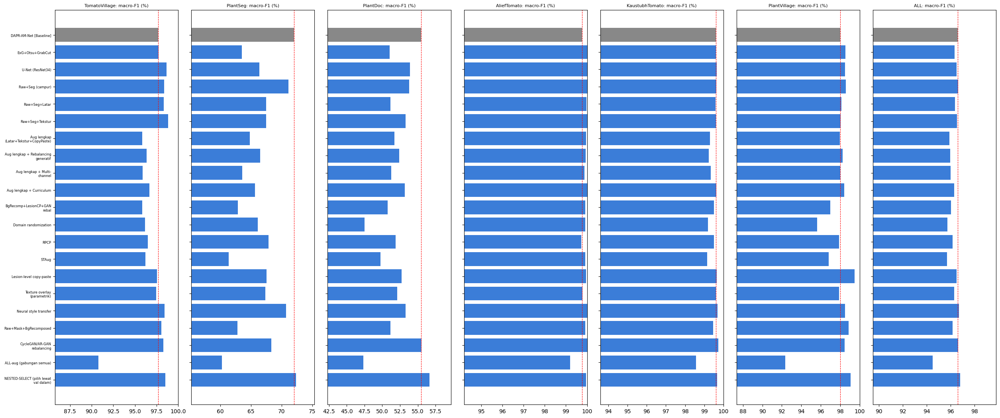

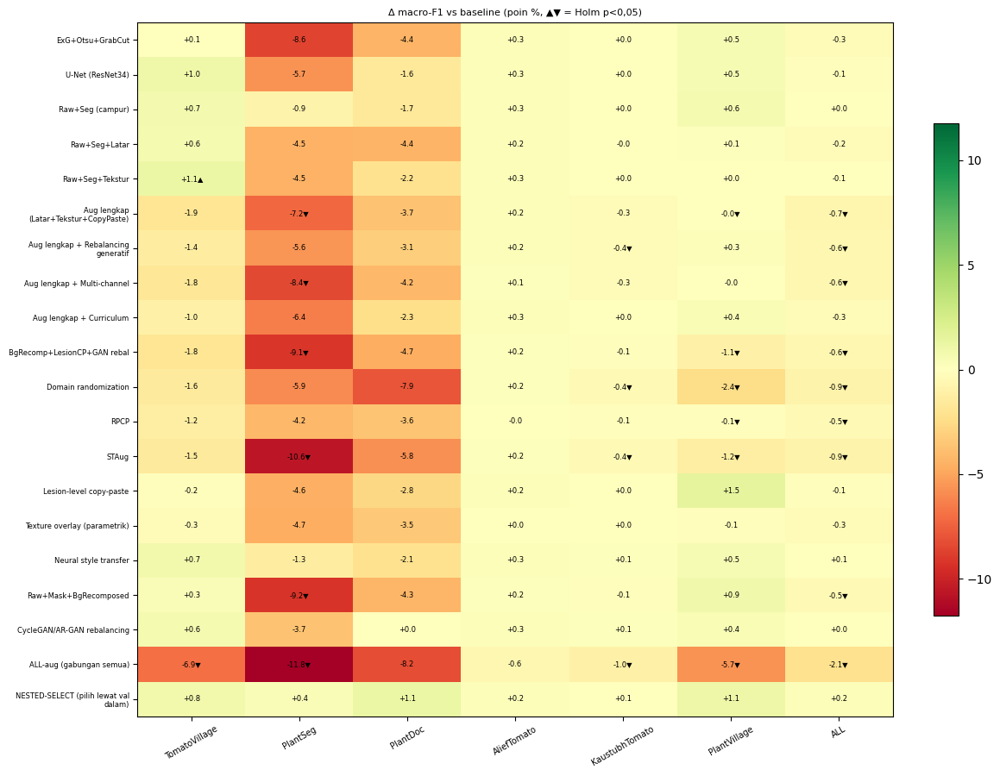

| Metode | Kelompok | TomatoVillage acc | TomatoVillage F1 | PlantSeg acc | PlantSeg F1 | PlantDoc acc | PlantDoc F1 | AliefTomato acc | AliefTomato F1 | KaustubhTomato acc | KaustubhTomato F1 | PlantVillage acc | PlantVillage F1 | ALL acc | ALL F1 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| DAPR-AM-Net [Baseline] | 0 Baseline | 97.9 | 97.7 | 75.2 | 72.0 | 57.1 | 55.5 | 99.7 | 99.8 | 99.6 | 99.6 | 99.6 | 98.0 | 97.3 | 96.6 |
| ExG+Otsu+GrabCut | 1 Lama (ganti latar) | 98.3 | 97.7 | 70.3 | 63.5 | 54.4 | 51.0 | 100.0 | 100.0 | 99.6 | 99.6 | 99.8 | 98.5 | 97.1 | 96.3 |
| U-Net (ResNet34) | 1 Lama (ganti latar) | 98.8 | 98.6 | 71.3 | 66.4 | 57.2 | 53.9 | 100.0 | 100.0 | 99.6 | 99.6 | 99.6 | 98.5 | 97.2 | 96.5 |
| Raw+Seg (campur) | 2 Lama: raw+seg | 98.8 | 98.4 | 74.1 | 71.1 | 57.1 | 53.8 | 100.0 | 100.0 | 99.6 | 99.6 | 99.7 | 98.6 | 97.3 | 96.7 |
| Raw+Seg+Latar | 2 Lama: raw+seg | 98.7 | 98.3 | 71.7 | 67.5 | 54.7 | 51.2 | 99.9 | 100.0 | 99.6 | 99.6 | 99.6 | 98.1

In [26]:
try:
    analyze_nested()
except Exception as e:
    log('Analisis gagal:', type(e).__name__, e); traceback.print_exc()
    log('Hasil mentah (runs/, preds/) tetap ada; jalankan ulang sel ini setelah memperbaiki, job yang selesai tidak diulang.')
rows = []
for m in METHOD_ORDER:
    jobs_m = [j for j in JOBS if j['name'] == m]; bk = SPECS[m].get('bank')
    note = BLOCKED.get(m, BANK_FAIL.get(bk, '') if bk else '')
    for k in SPECS[m].get('syn', ()):
        if k in ('sd', 'nst') and not SPECS[m].get('syn_opt') and not (SYN_KIND[:_SYN['ptr']] == k).any(): note = note or f'sintetis {k}: {SYN_STATUS.get(k)}'
    if SPECS[m].get('ue5') and not HAS_UE5 and not SPECS[m].get('syn_opt'): note = note or 'render UE5 tidak ditemukan'
    rows.append(dict(metode=m, dijalankan=m in RUN_LIST, job_selesai=f'{sum(is_done(j) for j in jobs_m)}/{len(jobs_m)}', catatan=note))
ST = pd.DataFrame(rows); ST.to_csv(os.path.join(TAB, 'status_akhir.csv'), index=False); print(ST.to_string(index=False))
try: make_light_zip()
except Exception as e: log('zip ringan gagal:', e)
log(f'Total waktu notebook: {(time.time()-T0)/3600:.2f} jam')
